In [66]:
import re                       # expresiones regulares, para interpretar el nombre de cada registro
from pathlib import Path        # manejo de rutas de archivos

import numpy as np              # operaciones numéricas con vectores y matrices
import pandas as pd             # tablas de datos
import matplotlib.pyplot as plt # gráficos
from matplotlib.colors import TwoSlopeNorm
import wfdb                     # lectura de registros en formato WFDB (PhysioNet)

from scipy import signal
from scipy.signal import find_peaks

# Carpeta con el dataset. El notebook tiene que estar en la misma carpeta que "Data"
carpeta_data = Path("Data")

# Reducción de interferencias magnetohidrodinámicas en ECG adquiridos durante resonancia magnética

## 1. Carga y caracterización de los registros

Se utiliza la base de datos *Influence of the MHD effect on 12-lead and 3-lead ECGs recorded in 1T to 7T MRI scanners* (Krug Passand, 2021), publicada en PhysioNet (Goldberger et al., 2000). Contiene registros de ECG de sujetos sanos adquiridos dentro de resonadores de 1 T, 3 T y 7 T, sin secuencias de adquisición activas, por lo que la distorsión registrada corresponde principalmente al efecto magnetohidrodinámico (MHD). También incluye registros de referencia adquiridos fuera del resonador.

Los archivos están en formato **WFDB** (*WaveForm DataBase*), el formato estándar de PhysioNet para señales fisiológicas. Cada registro se compone de tres archivos:

- **`.hea` (encabezado):** archivo de texto con la frecuencia de muestreo, la cantidad de derivaciones, sus nombres, unidades y la duración del registro.
- **`.dat` (señal):** los valores muestreados de cada derivación, en formato binario.
- **`.qrs` (anotaciones):** la posición, en muestras, de cada complejo QRS, marcada manualmente por médicos o especialistas en ECG. Se utilizarán como referencia para evaluar la detección automática de latidos.

Para leerlos se utiliza la librería de Python **`wfdb`**, desarrollada por PhysioNet, que interpreta estos formatos y devuelve las señales como matrices de NumPy y las anotaciones como vectores de posiciones.

El nombre de cada registro codifica las condiciones de adquisición. Por ejemplo, `ECGMRI3T04Ff` corresponde a un campo de 3 T, sujeto 04 y posición Ff. Las posiciones son:

- **Hf** (*head first*): el sujeto ingresa al resonador con la cabeza primero.
- **Ff** (*feet first*): ingresa con los pies primero.
- **Pro** y **Sup**: decúbito prono y supino (solo en el resonador de 1 T, de campo vertical).
- **Out**: registro de referencia, fuera del resonador.

Algunos registros tienen un número final (por ejemplo, `ECGMRI3T09Ff1` a `Ff3`), que corresponde a mediciones repetidas en la misma posición.

En esta sección se leen los encabezados y las anotaciones de todos los registros, sin cargar todavía las señales completas, para construir una tabla descriptiva del conjunto.

In [5]:
# El nombre de cada registro tiene la forma ECGMRI<campo>T<sujeto><posición><repetición>.
# La expresión regular separa esas partes:
#   (\d)            -> intensidad del campo en tesla (1, 3 o 7)
#   (\d{2})         -> número de sujeto (dos dígitos)
#   (Ff|Hf|Pro|Sup|Out) -> posición
#   (\d?)           -> número de repetición (opcional)
patron_nombre = re.compile(r"ECGMRI(\d)T(\d{2})(Ff|Hf|Pro|Sup|Out)(\d?)$")

filas = []

# Se recorre cada encabezado (.hea) de la carpeta, ordenados por nombre
for archivo_hea in sorted(carpeta_data.glob("*.hea")):
    nombre = archivo_hea.stem                  # nombre del registro, sin la extensión
    ruta = str(carpeta_data / nombre)          # wfdb recibe la ruta sin extensión

    partes = patron_nombre.match(nombre)
    if partes is None:
        raise ValueError(f"Nombre de registro no reconocido: {nombre}")
    campo, sujeto, posicion, repeticion = partes.groups()

    # rdheader lee solo el encabezado (no la señal), por lo que es rápido
    encabezado = wfdb.rdheader(ruta)

    # rdann lee las anotaciones manuales de QRS (archivo .qrs)
    anotaciones = wfdb.rdann(ruta, "qrs")

    duracion_s = encabezado.sig_len / encabezado.fs

    filas.append({
        "Registro": nombre,
        "Campo (T)": int(campo),
        "Sujeto": f"{campo}T{sujeto}",          # el sujeto se identifica junto con el campo
        "Posición": posicion,
        "Repetición": repeticion or "—",
        "Dentro del resonador": posicion != "Out",
        "Frecuencia (Hz)": encabezado.fs,
        "Derivaciones": encabezado.n_sig,
        "Nombres de derivaciones": ", ".join(encabezado.sig_name),
        "Unidades": ", ".join(sorted(set(encabezado.units))),
        "Duración (s)": round(duracion_s, 1),
        "QRS anotados": len(anotaciones.sample),
        # Frecuencia cardíaca media aproximada a partir de las anotaciones
        "FC media (lpm)": round(60 * len(anotaciones.sample) / duracion_s, 1),
    })

registros = pd.DataFrame(filas)

print(f"Registros leídos: {len(registros)}")
print(f"Duración total: {registros['Duración (s)'].sum() / 60:.1f} minutos")
display(registros)

Registros leídos: 53
Duración total: 226.6 minutos


,Registro,Campo (T),Sujeto,Posición,Repetición,Dentro del resonador,Frecuencia (Hz),Derivaciones,Nombres de derivaciones,Unidades,Duración (s),QRS anotados,FC media (lpm)
0,ECGMRI1T01Out,1,1T01,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,29.3,44,90.1
1,ECGMRI1T01Pro,1,1T01,Pro,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,39.1,57,87.6
2,ECGMRI1T01Sup,1,1T01,Sup,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,26.4,38,86.5
3,ECGMRI3T01Ff,3,3T01,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,326.2,361,66.4
4,ECGMRI3T01Hf,3,3T01,Hf,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,366.2,400,65.5
5,ECGMRI3T01Out,3,3T01,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,156.2,171,65.7
6,ECGMRI3T02Ff,3,3T02,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,24.4,27,66.4
7,ECGMRI3T02Out,3,3T02,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,24.4,27,66.4
8,ECGMRI3T03Ff,3,3T03,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,195.3,186,57.1
9,ECGMRI3T03Out,3,3T03,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,127.0,119,56.2


In [6]:
# Cantidad de registros según el campo magnético y la posición
print("Registros por campo y posición:")
display(pd.crosstab(registros["Campo (T)"], registros["Posición"], margins=True, margins_name="Total"))

# Cantidad de registros según la cantidad de derivaciones (equipo de 3 o de 12 derivaciones)
print("Registros por cantidad de derivaciones:")
display(registros["Derivaciones"].value_counts().rename("Registros"))

# Sujetos que tienen al menos un registro dentro del resonador y uno de
# referencia fuera. Son los que permiten comparar el ECG del mismo sujeto
# con y sin efecto MHD
con_referencia = (
    registros.groupby("Sujeto")["Dentro del resonador"]
    .agg(lambda x: x.any() and (~x).any())
)
sujetos_pareados = con_referencia[con_referencia].index.tolist()

print(f"Sujetos con registro dentro y fuera del resonador: {len(sujetos_pareados)}")
print(sujetos_pareados)

Registros por campo y posición:


Posición,Ff,Hf,Out,Pro,Sup,Total
Campo (T),,,,,,
1,0,0,1,1,1,3
3,25,6,4,0,0,35
7,5,5,5,0,0,15
Total,30,11,10,1,1,53


Registros por cantidad de derivaciones:


Derivaciones
12    39
3     14
Name: Registros, dtype: int64

Sujetos con registro dentro y fuera del resonador: 10
['1T01', '3T01', '3T02', '3T03', '3T04', '7T01', '7T02', '7T03', '7T04', '7T05']


### Control de registros duplicados

En la tabla descriptiva, los registros del sujeto 7T04 presentan exactamente la misma duración, cantidad de QRS anotados y frecuencia cardíaca que los del sujeto 3T01, en las tres posiciones. Lo mismo ocurre entre los registros 3T02Ff y 3T02Out. Como es muy poco probable que dos mediciones distintas coincidan en estos tres valores, se verifica si los archivos son copias.

Para eso se calcula una huella digital (hash SHA-256) del contenido de cada archivo de señal (`.dat`) y de anotaciones (`.qrs`). El hash es un código que se obtiene a partir de todos los bytes del archivo: dos archivos con el mismo contenido producen exactamente el mismo código, y cualquier diferencia, aunque sea de un solo valor, produce un código distinto. Así se puede comprobar si dos registros son idénticos sin comparar las señales muestra por muestra.

In [7]:
import hashlib  # cálculo de huellas digitales (hash) de archivos

# Nombres de los registros (sirve tanto si la tabla tiene el nombre como
# columna como si lo tiene como índice)
nombres = (
    list(registros["Registro"]) if "Registro" in registros.columns
    else list(registros.index)
)


def huella(archivo):
    """Hash SHA-256 de todos los bytes del archivo."""
    return hashlib.sha256(archivo.read_bytes()).hexdigest()


huellas_senal = [huella(carpeta_data / f"{n}.dat") for n in nombres]
huellas_qrs = [huella(carpeta_data / f"{n}.qrs") for n in nombres]

# Agrupar los registros que comparten la misma huella
for tipo, huellas in [("señal (.dat)", huellas_senal), ("anotaciones (.qrs)", huellas_qrs)]:
    grupos = pd.Series(nombres).groupby(huellas).apply(list)
    repetidos = grupos[grupos.apply(len) > 1]

    print(f"Grupos de registros con {tipo} idénticas: {len(repetidos)}")
    for lista in repetidos:
        print("   " + " = ".join(lista))
    print()

Grupos de registros con señal (.dat) idénticas: 1
   ECGMRI3T01Out = ECGMRI7T04Out

Grupos de registros con anotaciones (.qrs) idénticas: 3
   ECGMRI3T01Hf = ECGMRI7T04Hf
   ECGMRI3T01Ff = ECGMRI7T04Ff
   ECGMRI3T01Out = ECGMRI7T04Out



El registro `ECGMRI7T04Out` es una copia exacta de `ECGMRI3T01Out`. Los registros `ECGMRI7T04Ff` y `ECGMRI7T04Hf` tienen las mismas anotaciones que `ECGMRI3T01Ff` y `ECGMRI3T01Hf`, aunque sus archivos de señal no son idénticos. Como dos sesiones distintas no pueden presentar los latidos exactamente en las mismas posiciones, se comparan las señales de cada par para determinar si corresponden a la misma grabación.

Para cada par se calcula la **correlación de Pearson** entre las señales, derivación por derivación. Mide qué tan parecida es la forma de dos señales, independientemente de su escala: vale 1 si una es copia de la otra (aunque esté multiplicada por una constante) y valores cercanos a 0 si no se parecen. También se calcula la diferencia máxima entre ambas, en mV.

In [8]:
# Pares de registros a comparar
pares = [
    ("ECGMRI3T01Ff", "ECGMRI7T04Ff"),
    ("ECGMRI3T01Hf", "ECGMRI7T04Hf"),
    ("ECGMRI3T01Out", "ECGMRI7T04Out"),
    ("ECGMRI3T02Ff", "ECGMRI3T02Out"),
]

filas_pares = []
for nombre_a, nombre_b in pares:
    # rdrecord lee la señal completa; p_signal es la matriz (muestras x derivaciones) en mV
    a = wfdb.rdrecord(str(carpeta_data / nombre_a)).p_signal
    b = wfdb.rdrecord(str(carpeta_data / nombre_b)).p_signal

    # Si tienen distinta longitud, se comparan solo las muestras en común
    n = min(len(a), len(b))
    a, b = a[:n], b[:n]

    # Correlación de cada derivación entre ambos registros
    correlaciones = [np.corrcoef(a[:, i], b[:, i])[0, 1] for i in range(a.shape[1])]

    filas_pares.append({
        "Registro A": nombre_a,
        "Registro B": nombre_b,
        "Muestras comparadas": n,
        "Correlación mínima": min(correlaciones),
        "Correlación media": np.mean(correlaciones),
        "Diferencia máxima (mV)": np.nanmax(np.abs(a - b)),
    })

display(pd.DataFrame(filas_pares).round(4))

,Registro A,Registro B,Muestras comparadas,Correlación mínima,Correlación media,Diferencia máxima (mV)
0,ECGMRI3T01Ff,ECGMRI7T04Ff,334001,0.9352,0.9485,7.7055
1,ECGMRI3T01Hf,ECGMRI7T04Hf,375001,0.9219,0.9455,17.5597
2,ECGMRI3T01Out,ECGMRI7T04Out,160000,1.0000,1.0000,0.0000
3,ECGMRI3T02Ff,ECGMRI3T02Out,25000,-0.1159,-0.0079,3.7222


In [9]:
# Registros excluidos: los tres de 7T04 duplican la sesión de 3T01
# (7T04Out es una copia exacta y 7T04Ff/7T04Hf comparten las anotaciones
# y tienen correlación > 0,92 con 3T01Ff/3T01Hf)
excluidos = ["ECGMRI7T04Ff", "ECGMRI7T04Hf", "ECGMRI7T04Out"]

registros["Excluido"] = [n in excluidos for n in nombres]
registros_validos = registros[~registros["Excluido"]].copy()

dentro = registros_validos["Dentro del resonador"]
print(f"Registros válidos: {len(registros_validos)} "
      f"({dentro.sum()} dentro y {(~dentro).sum()} fuera del resonador)")

# Comprobación con la descripción de PhysioNet (43 registros dentro, 203 minutos),
# usando la tabla completa, antes de excluir
dentro_total = registros["Dentro del resonador"]
print(f"Duración de los registros dentro del resonador (tabla completa): "
      f"{registros.loc[dentro_total, 'Duración (s)'].sum() / 60:.1f} min "
      f"en {dentro_total.sum()} registros")

print("\nRegistros válidos por campo y posición:")
display(pd.crosstab(registros_validos["Campo (T)"], registros_validos["Posición"],
                    margins=True, margins_name="Total"))

con_referencia = (
    registros_validos.groupby("Sujeto")["Dentro del resonador"]
    .agg(lambda x: x.any() and (~x).any())
)
sujetos_pareados = con_referencia[con_referencia].index.tolist()
print(f"Sujetos con registro dentro y fuera del resonador: {len(sujetos_pareados)}")
print(sujetos_pareados)

Registros válidos: 50 (41 dentro y 9 fuera del resonador)
Duración de los registros dentro del resonador (tabla completa): 203.1 min en 43 registros

Registros válidos por campo y posición:


Posición,Ff,Hf,Out,Pro,Sup,Total
Campo (T),,,,,,
1,0,0,1,1,1,3
3,25,6,4,0,0,35
7,4,4,4,0,0,12
Total,29,10,9,1,1,50


Sujetos con registro dentro y fuera del resonador: 9
['1T01', '3T01', '3T02', '3T03', '3T04', '7T01', '7T02', '7T03', '7T05']


### Resultado de la caracterización de los registros

El conjunto contiene 53 registros, todos muestreados a 1024 Hz y con las señales expresadas en mV:

- 43 registros dentro del resonador, con una duración total de 203,1 minutos, que coincide con la descripción de PhysioNet, y 10 registros de referencia fuera del resonador.
- 39 registros de 12 derivaciones (I, II, III, aVR, aVL, aVF y V1 a V6), adquiridos con el Holter CardioMem 3000, y 14 de 3 derivaciones (I, II y III), adquiridos con el monitor inalámbrico del equipo de resonancia (Tesla M3). Los de 3 derivaciones corresponden a los sujetos 3T10 a 3T23, todos en posición Ff y sin registro de referencia.
- Los registros a 1 T son cortos (26 a 39 s), mientras que los de 3 T y 7 T duran entre 24 s y 12 minutos. La frecuencia cardíaca media, estimada a partir de las anotaciones, varía entre 46 y 90 lpm.

**Registros duplicados:** El control de huellas digitales mostró que `ECGMRI7T04Out` es una copia exacta de `ECGMRI3T01Out`, y que `ECGMRI7T04Ff` y `ECGMRI7T04Hf` comparten las anotaciones de `ECGMRI3T01Ff` y `ECGMRI3T01Hf`. Sus señales presentan una correlación de entre 0,92 y 0,95 con los latidos alineados muestra a muestra, lo que no es posible entre sesiones distintas (como referencia, los registros 3T02Ff y 3T02Out, que sí son sesiones distintas, tienen una correlación cercana a 0). Por lo tanto, corresponden a una misma sesión. Se excluyen los tres registros de 7T04 y se conservan los de 3T01, ya que la serie de 3 T es consecutiva (sujetos 01 a 23) y coincide con los 23 sujetos informados en el dataset. Como no es posible confirmar cuál de las dos etiquetas de campo es la correcta, esto se considera una limitación del trabajo.

Quedan 50 registros válidos y 9 sujetos con registro dentro y fuera del resonador, que se utilizarán para comparar la morfología del ECG con y sin efecto MHD. Los 50 registros, al tener anotaciones manuales de QRS, se utilizarán para evaluar la detección de latidos.

## 2. Caracterización temporal y frecuencial

Se caracterizan las señales originales, antes de aplicar filtros,
mediante media, varianza, valor RMS, autocorrelación y densidad
espectral de potencia (PSD).

### Caracterización temporal

La media describe el nivel medio del registro. La varianza cuantifica
las fluctuaciones alrededor de ese nivel y el RMS representa la
amplitud cuadrática media. Se calculan sobre cada derivación del
registro completo, conservando las unidades físicas de adquisición.

Estas medidas describen la señal observada en su conjunto: no permiten
separar la actividad cardíaca, el efecto MHD y otras fuentes de ruido.
Por lo tanto, un aumento de varianza o RMS no se interpreta por sí
solo como una medida de interferencia MHD.

La autocorrelación se calcula sobre la señal centrada y se normaliza
por su valor a retardo cero. Se utiliza para explorar la repetitividad
temporal. Una estructura periódica no implica ausencia de interferencia,
ya que el efecto MHD también está relacionado con el ciclo cardíaco.

### Estimación de la densidad espectral de potencia

La PSD se estima mediante el método de Welch, que divide la señal en
segmentos, calcula sus periodogramas modificados y los promedia para
reducir la variabilidad de la estimación espectral (Welch, 1967).

Se utiliza una ventana Hann para reducir la fuga espectral respecto
del truncamiento rectangular. Esta reducción se obtiene a costa de
ensanchar el lóbulo principal y disminuir la capacidad de distinguir
componentes frecuenciales próximas (Harris, 1978).

Se adoptan segmentos de 4 segundos con un solapamiento del 50 %.
Como antecedente aplicado al voltaje del ECG, Ishmakhametov et al.
(2026) utilizaron Welch con ventanas Hann de 2048 muestras a 512 Hz,
equivalentes a 4 segundos, y un solapamiento del 50 %, para estimar
la PSD en una evaluación de calidad de señales fisiológicas.

En nuestro caso, se conserva esa duración temporal y se adapta la
cantidad de muestras a la frecuencia de muestreo del dataset:

N_segmento = 4 s × 1024 muestras/s = 4096 muestras.

El solapamiento corresponde a 2048 muestras y el desplazamiento
entre segmentos consecutivos es de 2 segundos.

Sin relleno con ceros, la separación entre bins es:

Δf = fs / N_segmento = 1024 / 4096 = 0,25 Hz.

Esta separación no equivale a la resolución espectral efectiva,
que también depende de la ventana.

La duración de 4 segundos permite calcular varios periodogramas
incluso en los registros más cortos del conjunto. Se adopta como
configuración inicial respaldada por un antecedente de ECG,
sin considerarla una duración óptima demostrada para este dataset.

El solapamiento permite incorporar segmentos adicionales al promedio,
aunque estos no constituyen observaciones estadísticamente
independientes.

Para calcular la PSD se elimina la media de cada segmento antes
del enventanado. Este centrado se aplica únicamente a la estimación
espectral; las estadísticas temporales se calculan sobre las señales
originales. La PSD se expresa en mV²/Hz.

### Comparación entre condiciones

Se mantienen los mismos parámetros de estimación en todos los
registros y derivaciones.

Las comparaciones dentro–fuera se realizan entre registros del mismo
identificador de sujeto y con derivaciones coincidentes. Para las
figuras comparativas se utilizan tramos iniciales de igual duración,
de hasta 30 segundos, limitados por el registro más corto del par.
Este criterio es reproducible, pero requiere inspeccionar los tramos
para identificar posibles transitorios o artefactos.

Las estadísticas generales describen los registros completos.
Las tablas que acompañan a las figuras describen únicamente
los tramos representados.

Las señales temporales no están alineadas por latidos, por lo que
no se interpreta su diferencia muestra a muestra. La alineación
y el análisis morfológico se abordarán en una etapa posterior.

Las referencias externas no son simultáneas con las adquisiciones
internas. Por ello, las diferencias temporales y espectrales no se
atribuyen exclusivamente al MHD (Krug et al., 2017).

Abi-Abdallah et al. (2007) constituye un antecedente directo de
comparación temporal y espectral de ECG dentro y fuera de un
resonador mediante Welch. Ese trabajo no especifica la ventana,
la duración de los segmentos ni el solapamiento, por lo que no
se utiliza para justificar esos parámetros.


In [10]:
# Configuración de Welch:
# Hann de 4 s y 50 % de solapamiento.
VENTANA_S = 4.0
SOLAPAMIENTO = 0.50


def estadisticas_temporales(x):
    """Estadísticas descriptivas sobre la señal original."""
    x = np.asarray(x, dtype=float)

    if (x.ndim != 1 or len(x) == 0) or (not np.isfinite(x).all()):
        raise ValueError("Error en la señal: debe ser unidimensional, no vacía y finita.")

    return {
        "Media (mV)": np.mean(x),
        "Varianza (mV²)": np.var(x, ddof=0),
        "RMS (mV)": np.sqrt(np.mean(x**2)),
    }


def calcular_psd(x, fs):
    """PSD unilateral de Welch, expresada en mV²/Hz."""
    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or not np.isfinite(x).all():
        raise ValueError("La señal debe ser unidimensional y finita.")

    nperseg = int(round(VENTANA_S * fs))
    noverlap = int(round(nperseg * SOLAPAMIENTO))

    if len(x) < nperseg:
        raise ValueError(
            f"Se necesitan al menos {nperseg} muestras "
            f"para una ventana de {VENTANA_S} s."
        )

    # Hann periódica, adecuada para análisis mediante DFT.
    ventana = signal.windows.hann(nperseg, sym=False)

    f, psd = signal.welch(
        x,
        fs=fs,
        window=ventana,
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nperseg,             # Sin relleno con ceros
        detrend="constant",       # Restar media antes del enventanado
        return_onesided=True,
        scaling="density",
        average="mean",
    )

    paso = nperseg - noverlap
    cantidad_segmentos = 1 + (len(x) - nperseg) // paso

    return f, psd, cantidad_segmentos


def calcular_autocorrelacion(x, fs, max_retardo_s=3.0):
    """Autocorrelación sesgada, centrada y normalizada en retardo cero."""
    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or len(x) == 0 or not np.isfinite(x).all():
        raise ValueError("La señal debe ser unidimensional, no vacía y finita.")

    centrada = x - np.mean(x)
    energia = np.dot(centrada, centrada)

    n_retardos = min(
        len(x),
        int(round(max_retardo_s * fs)) + 1,
    )
    retardos = np.arange(n_retardos) / fs

    # Una señal constante no tiene autocorrelación normalizada definida.
    if energia == 0:
        return retardos, np.full(n_retardos, np.nan)

    correlacion = signal.correlate(
        centrada,
        centrada,
        mode="full",
        method="fft",
    )

    correlacion = correlacion[
        len(x) - 1:len(x) - 1 + n_retardos
    ]

    # El factor 1/N se cancela al normalizar por el retardo cero.
    normalizada = correlacion / energia

    return retardos, normalizada

In [11]:
filas_caracteristicas = []
espectros = {}

for _, fila in registros_validos.iterrows():
    nombre = fila["Registro"]
    registro = wfdb.rdrecord(str(carpeta_data / nombre))

    fs = float(registro.fs)

    if registro.p_signal is None:
        raise ValueError(f"{nombre}: no se pudieron cargar las señales físicas.")

    for canal, derivacion in enumerate(registro.sig_name):
        unidad = registro.units[canal]

        # Las etiquetas y comparaciones de este análisis utilizan mV.
        if unidad != "mV":
            raise ValueError(
                f"{nombre}, {derivacion}: unidad inesperada '{unidad}'."
            )

        x = np.asarray(registro.p_signal[:, canal], dtype=float)

        try:
            estadisticas = estadisticas_temporales(x)
            f, psd, cantidad_segmentos = calcular_psd(x, fs)
        except ValueError as error:
            raise ValueError(
                f"Error en {nombre}, derivación {derivacion}: {error}"
            ) from error

        filas_caracteristicas.append({
            "Registro": nombre,
            "Sujeto": fila["Sujeto"],
            "Campo de la serie (T)": fila["Campo (T)"],
            "Posición": fila["Posición"],
            "Dentro del resonador": fila["Dentro del resonador"],
            "Derivación": derivacion,
            "Frecuencia de muestreo (Hz)": fs,
            "Duración (s)": len(x) / fs,
            **estadisticas,
            "Segmentos Welch": cantidad_segmentos,
        })

        espectros[(nombre, derivacion)] = {
            "Frecuencia (Hz)": f,
            "PSD (mV²/Hz)": psd,
        }

caracteristicas = pd.DataFrame(filas_caracteristicas)

print(
    f"Registros caracterizados: "
    f"{caracteristicas['Registro'].nunique()}"
)
print(f"Combinaciones registro–derivación: {len(caracteristicas)}")

display(caracteristicas.round(4))

Registros caracterizados: 50
Combinaciones registro–derivación: 474


,Registro,Sujeto,Campo de la serie (T),Posición,Dentro del resonador,Derivación,Frecuencia de muestreo (Hz),Duración (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,ECGMRI1T01Out,1T01,1,Out,False,I,1024.0,29.2959,-0.0933,0.0087,0.1321,13
1,ECGMRI1T01Out,1T01,1,Out,False,II,1024.0,29.2959,5.9921,0.0761,5.9985,13
2,ECGMRI1T01Out,1T01,1,Out,False,III,1024.0,29.2959,0.0848,0.0405,0.2185,13
3,ECGMRI1T01Out,1T01,1,Out,False,aVR,1024.0,29.2959,-14.9500,0.0323,14.9511,13
4,ECGMRI1T01Out,1T01,1,Out,False,aVL,1024.0,29.2959,-6.0891,0.0056,6.0895,13
...,...,...,...,...,...,...,...,...,...,...,...,...
469,ECGMRI7T05Out,7T05,7,Out,False,V2,1024.0,107.4229,0.0000,0.1342,0.3664,52
470,ECGMRI7T05Out,7T05,7,Out,False,V3,1024.0,107.4229,0.0000,0.1312,0.3622,52
471,ECGMRI7T05Out,7T05,7,Out,False,V4,1024.0,107.4229,-0.0000,0.1794,0.4236,52
472,ECGMRI7T05Out,7T05,7,Out,False,V5,1024.0,107.4229,0.0000,0.1177,0.3430,52


In [12]:
# Resumen de las estadísticas de todos los registros y derivaciones.
metricas = ["Media (mV)", "Varianza (mV²)", "RMS (mV)"]

estadisticas_globales = caracteristicas.copy()

numero_derivaciones = (
    registros_validos.set_index("Registro")["Derivaciones"]
)

estadisticas_globales["Derivaciones"] = (
    estadisticas_globales["Registro"].map(numero_derivaciones)
)

estadisticas_globales["Condición"] = np.where(
    estadisticas_globales["Dentro del resonador"],
    "Dentro",
    "Fuera",
)

grupos = estadisticas_globales.groupby(
    ["Derivaciones", "Derivación", "Condición"]
)

resumen_global = pd.concat(
    [
        grupos.size().rename("Cantidad"),
        grupos[metricas].median().add_suffix(" — Mediana"),
        grupos[metricas].quantile(0.25).add_suffix(" — Q25"),
        grupos[metricas].quantile(0.75).add_suffix(" — Q75"),
    ],
    axis=1,
).reset_index()

# Mostrar una tabla por métrica para facilitar su lectura.
for metrica in metricas:
    print(f"\nResumen de {metrica}")

    columnas = [
        "Derivaciones",
        "Derivación",
        "Condición",
        "Cantidad",
        f"{metrica} — Mediana",
        f"{metrica} — Q25",
        f"{metrica} — Q75",
    ]

    display(resumen_global[columnas].round(4))


Resumen de Media (mV)


,Derivaciones,Derivación,Condición,Cantidad,Media (mV) — Mediana,Media (mV) — Q25,Media (mV) — Q75
0,3,I,Dentro,14,-1.1593,-2.5902,2.2159
1,3,II,Dentro,14,0.0922,-3.2875,3.5185
2,3,III,Dentro,14,0.1537,-2.2869,0.9641
3,12,I,Dentro,27,0.0000,-0.0034,0.0086
4,12,I,Fuera,9,-0.0000,-0.0088,0.0000
5,12,II,Dentro,27,0.0000,-0.0000,0.0154
6,12,II,Fuera,9,-0.0000,-0.0000,-0.0000
7,12,III,Dentro,27,0.0000,-0.0002,0.0084
8,12,III,Fuera,9,0.0000,-0.0000,0.0176
9,12,V1,Dentro,27,0.0000,-0.0108,0.0075



Resumen de Varianza (mV²)


,Derivaciones,Derivación,Condición,Cantidad,Varianza (mV²) — Mediana,Varianza (mV²) — Q25,Varianza (mV²) — Q75
0,3,I,Dentro,14,0.0548,0.0393,0.1091
1,3,II,Dentro,14,0.1990,0.1430,0.3387
2,3,III,Dentro,14,0.0836,0.0536,0.1286
3,12,I,Dentro,27,0.8732,0.5749,1.9683
4,12,I,Fuera,9,0.0116,0.0087,0.0137
5,12,II,Dentro,27,0.8654,0.6325,1.5066
6,12,II,Fuera,9,0.1063,0.0761,0.1253
7,12,III,Dentro,27,1.1641,0.7145,2.5547
8,12,III,Fuera,9,0.0592,0.0405,0.0676
9,12,V1,Dentro,27,0.3551,0.2479,1.0765



Resumen de RMS (mV)


,Derivaciones,Derivación,Condición,Cantidad,RMS (mV) — Mediana,RMS (mV) — Q25,RMS (mV) — Q75
0,3,I,Dentro,14,2.6473,1.3964,6.1057
1,3,II,Dentro,14,3.6999,2.3753,4.4858
2,3,III,Dentro,14,1.5201,0.9463,3.0517
3,12,I,Dentro,27,0.9345,0.7599,1.4016
4,12,I,Fuera,9,0.1114,0.0938,0.1321
5,12,II,Dentro,27,0.9330,0.7960,1.3603
6,12,II,Fuera,9,0.3274,0.3047,0.4006
7,12,III,Dentro,27,1.0789,0.8467,1.5984
8,12,III,Fuera,9,0.2434,0.2185,0.2601
9,12,V1,Dentro,27,0.5961,0.4985,1.0372


In [13]:
claves = ["Sujeto", "Derivación", "Derivaciones"]

referencias = (
    estadisticas_globales.loc[
        ~estadisticas_globales["Dentro del resonador"],
        claves + ["Registro"] + metricas,
    ]
    .rename(columns={
        "Registro": "Registro fuera",
        **{metrica: f"{metrica} fuera" for metrica in metricas},
    })
)

internos = (
    estadisticas_globales.loc[
        estadisticas_globales["Dentro del resonador"],
        claves + ["Registro", "Posición"] + metricas,
    ]
    .rename(columns={
        "Registro": "Registro dentro",
        **{metrica: f"{metrica} dentro" for metrica in metricas},
    })
)

# Se espera una sola referencia externa por sujeto y derivación.
comparaciones_pareadas = internos.merge(
    referencias,
    on=claves,
    how="inner",
    validate="many_to_one",
)

comparaciones_pareadas["Diferencia de media (mV)"] = (
    comparaciones_pareadas["Media (mV) dentro"]
    - comparaciones_pareadas["Media (mV) fuera"]
)

for metrica, nombre in [
    ("Varianza (mV²)", "Cociente varianza dentro/fuera"),
    ("RMS (mV)", "Cociente RMS dentro/fuera"),
]:
    denominador = comparaciones_pareadas[f"{metrica} fuera"]

    comparaciones_pareadas[nombre] = (
        comparaciones_pareadas[f"{metrica} dentro"]
        / denominador.where(denominador > 0)
    )

columnas_mostrar = [
    "Registro dentro",
    "Registro fuera",
    "Derivación",
    "Diferencia de media (mV)",
    "Cociente varianza dentro/fuera",
    "Cociente RMS dentro/fuera",
]

display(
    comparaciones_pareadas[columnas_mostrar]
    .round(4)
    .reset_index(drop=True)
)

,Registro dentro,Registro fuera,Derivación,Diferencia de media (mV),Cociente varianza dentro/fuera,Cociente RMS dentro/fuera
0,ECGMRI1T01Pro,ECGMRI1T01Out,I,0.0285,46.8930,4.8720
1,ECGMRI1T01Pro,ECGMRI1T01Out,II,0.2087,14.9571,1.0489
2,ECGMRI1T01Pro,ECGMRI1T01Out,III,0.1802,15.4973,3.8253
3,ECGMRI1T01Pro,ECGMRI1T01Out,aVR,-0.1186,19.1073,1.0092
4,ECGMRI1T01Pro,ECGMRI1T01Out,aVL,-0.0763,41.8918,1.0156
...,...,...,...,...,...,...
175,ECGMRI7T05Hf,ECGMRI7T05Out,V2,0.0000,13.9179,3.7307
176,ECGMRI7T05Hf,ECGMRI7T05Out,V3,-0.0000,11.7248,3.4242
177,ECGMRI7T05Hf,ECGMRI7T05Out,V4,-0.0000,8.7936,2.9654
178,ECGMRI7T05Hf,ECGMRI7T05Out,V5,-0.0000,12.5725,3.5458


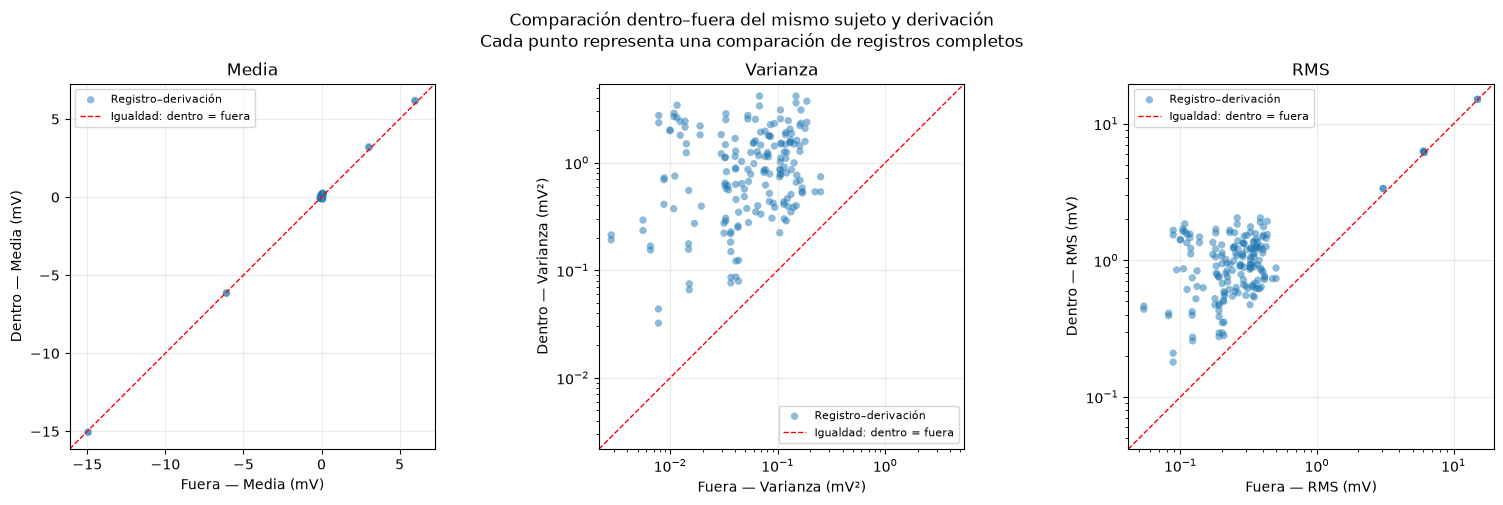

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

configuracion = [
    ("Media (mV)", "Media", False),
    ("Varianza (mV²)", "Varianza", True),
    ("RMS (mV)", "RMS", True),
]

for ax, (metrica, titulo, usar_log) in zip(ejes, configuracion):
    x = comparaciones_pareadas[f"{metrica} fuera"].to_numpy(dtype=float)
    y = comparaciones_pareadas[f"{metrica} dentro"].to_numpy(dtype=float)

    validos = np.isfinite(x) & np.isfinite(y)

    if usar_log:
        validos &= (x > 0) & (y > 0)

    x, y = x[validos], y[validos]

    if len(x) == 0:
        ax.set_title(titulo)
        ax.text(
            0.5, 0.5, "Sin valores disponibles",
            ha="center", transform=ax.transAxes,
        )
        continue

    ax.scatter(
        x, y,
        s=28,
        alpha=0.5,
        edgecolors="none",
        label="Registro–derivación",
    )

    valores = np.concatenate([x, y])

    if usar_log:
        minimo = valores.min() / 1.3
        maximo = valores.max() * 1.3
        ax.set_xscale("log")
        ax.set_yscale("log")
    else:
        minimo, maximo = valores.min(), valores.max()
        margen = max((maximo - minimo) * 0.05, 0.01)
        minimo -= margen
        maximo += margen

    # Igualdad y mismos límites en ambos ejes.
    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        "r--",
        linewidth=1,
        label="Igualdad: dentro = fuera",
    )

    ax.set_xlim(minimo, maximo)
    ax.set_ylim(minimo, maximo)
    ax.set_aspect("equal", adjustable="box")

    ax.set(
        title=titulo,
        xlabel=f"Fuera — {metrica}",
        ylabel=f"Dentro — {metrica}",
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Comparación dentro–fuera del mismo sujeto y derivación\n"
    "Cada punto representa una comparación de registros completos"
)

plt.tight_layout()
# plt.show()

La comparación pareada muestra medias similares dentro y fuera
del resonador, con puntos próximos a la recta de igualdad.
En cambio, todas las comparaciones presentan mayor varianza
y RMS en la adquisición interna.

El cociente de varianzas presenta una mediana de 13,88 y el
cociente de RMS una mediana de 3,45. Estos resultados indican
mayores fluctuaciones y mayor amplitud cuadrática media dentro
del resonador, sin un desplazamiento generalizado del nivel medio.

En algunas derivaciones con niveles medios elevados, el RMS
permanece próximo a la igualdad, dado que esta medida incluye
la contribución de la media: RMS² = varianza + media².
Por ello, la varianza resulta más directa para describir
las fluctuaciones alrededor del nivel medio.

Los resultados son descriptivos y corresponden a adquisiciones
no simultáneas de distinta duración. No permiten atribuir todo
el incremento exclusivamente al MHD. Las comparaciones comparten
sujetos y referencias, por lo que no son observaciones independientes.

In [15]:
def comparar_registros(
    nombre_fuera,
    nombre_dentro,
    derivacion="II",
    duracion_max_s=30.0,
):
    """Compara registros del mismo grupo, sin filtrar ni alinear latidos."""

    tabla = registros_validos.set_index("Registro")

    for nombre in (nombre_fuera, nombre_dentro):
        if nombre not in tabla.index:
            raise ValueError(
                f"{nombre} no pertenece al conjunto de registros conservados."
            )

    fila_fuera = tabla.loc[nombre_fuera]
    fila_dentro = tabla.loc[nombre_dentro]

    if bool(fila_fuera["Dentro del resonador"]):
        raise ValueError("El primer registro debe ser una referencia Out.")

    if not bool(fila_dentro["Dentro del resonador"]):
        raise ValueError("El segundo registro debe estar dentro del resonador.")

    if fila_fuera["Sujeto"] != fila_dentro["Sujeto"]:
        raise ValueError("Los registros deben pertenecer al mismo grupo.")

    if fila_fuera["Derivaciones"] != fila_dentro["Derivaciones"]:
        raise ValueError("Los registros tienen configuraciones diferentes.")

    fuera = wfdb.rdrecord(str(carpeta_data / nombre_fuera))
    dentro = wfdb.rdrecord(str(carpeta_data / nombre_dentro))

    if fuera.fs != dentro.fs:
        raise ValueError("Las frecuencias de muestreo no coinciden.")

    if (
        derivacion not in fuera.sig_name
        or derivacion not in dentro.sig_name
    ):
        raise ValueError(
            f"La derivación {derivacion} no está disponible en ambos registros."
        )

    canal_fuera = fuera.sig_name.index(derivacion)
    canal_dentro = dentro.sig_name.index(derivacion)

    if (
        fuera.units[canal_fuera] != "mV"
        or dentro.units[canal_dentro] != "mV"
    ):
        raise ValueError("Ambas señales deben estar expresadas en mV.")

    fs = float(fuera.fs)

    if not np.isfinite(duracion_max_s) or duracion_max_s < VENTANA_S:
        raise ValueError(
            f"La duración solicitada debe ser al menos {VENTANA_S} s."
        )

    n = min(
        len(fuera.p_signal),
        len(dentro.p_signal),
        int(round(duracion_max_s * fs)),
    )

    datos = {
        "Fuera": np.asarray(
            fuera.p_signal[:n, canal_fuera], dtype=float
        ),
        "Dentro": np.asarray(
            dentro.p_signal[:n, canal_dentro], dtype=float
        ),
    }

    # Validar y calcular antes de crear la figura.
    resultados = {}
    filas_resumen = []

    for condicion, x in datos.items():
        estadisticas = estadisticas_temporales(x)
        f, psd, cantidad_segmentos = calcular_psd(x, fs)
        retardos, autocorr = calcular_autocorrelacion(x, fs)

        resultados[condicion] = {
            "Señal": x,
            "Frecuencia": f,
            "PSD": psd,
            "Retardos": retardos,
            "Autocorrelación": autocorr,
        }

        filas_resumen.append({
            "Condición": condicion,
            "Duración analizada (s)": n / fs,
            **estadisticas,
            "Segmentos Welch": cantidad_segmentos,
        })

        if np.isnan(autocorr).all():
            print(
                f"Aviso: {condicion} presenta una señal constante; "
                "su autocorrelación normalizada no está definida."
            )

    colores = {"Fuera": "tab:blue", "Dentro": "tab:orange"}

    fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
    tiempo = np.arange(n) / fs
    n_vista = min(n, int(round(5 * fs)))

    for condicion, resultado in resultados.items():
        color = colores[condicion]

        ejes[0, 0].plot(
            tiempo[:n_vista],
            resultado["Señal"][:n_vista],
            color=color,
            label=condicion,
            alpha=0.8,
            linewidth=1,
        )

        ejes[0, 1].plot(
            resultado["Retardos"],
            resultado["Autocorrelación"],
            color=color,
            label=condicion,
        )

        f = resultado["Frecuencia"]
        psd = resultado["PSD"]

        # Los ceros se omiten únicamente en la representación logarítmica.
        for eje, limite in ((ejes[1, 0], 100), (ejes[1, 1], 20)):
            mascara = (f <= limite) & (psd > 0)

            eje.semilogy(
                f[mascara],
                psd[mascara],
                color=color,
                label=condicion,
            )
            eje.set_xlim(0, min(limite, fs / 2))

    ejes[0, 0].set(
        title="ECG original: primeros 5 s, sin alineación por latidos",
        xlabel="Tiempo desde el inicio de cada registro (s)",
        ylabel="Amplitud (mV)",
    )

    ejes[0, 1].set(
        title="Autocorrelación normalizada del tramo completo",
        xlabel="Retardo (s)",
        ylabel="Autocorrelación",
    )

    ejes[1, 0].set(
        title="PSD de Welch: vista de 0–100 Hz",
        xlabel="Frecuencia (Hz)",
        ylabel="PSD (mV²/Hz)",
    )

    ejes[1, 1].set(
        title="PSD de Welch: detalle de 0–20 Hz",
        xlabel="Frecuencia (Hz)",
        ylabel="PSD (mV²/Hz)",
    )

    for eje in ejes.flat:
        eje.grid(alpha=0.25)
        eje.legend()

    fig.suptitle(
        f"{nombre_fuera} vs. {nombre_dentro} — derivación {derivacion}\n"
        f"Tramos iniciales de {n / fs:.2f} s; adquisiciones no simultáneas"
    )

    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

    return pd.DataFrame(filas_resumen)

Comparación dentro–fuera: serie de 3 T


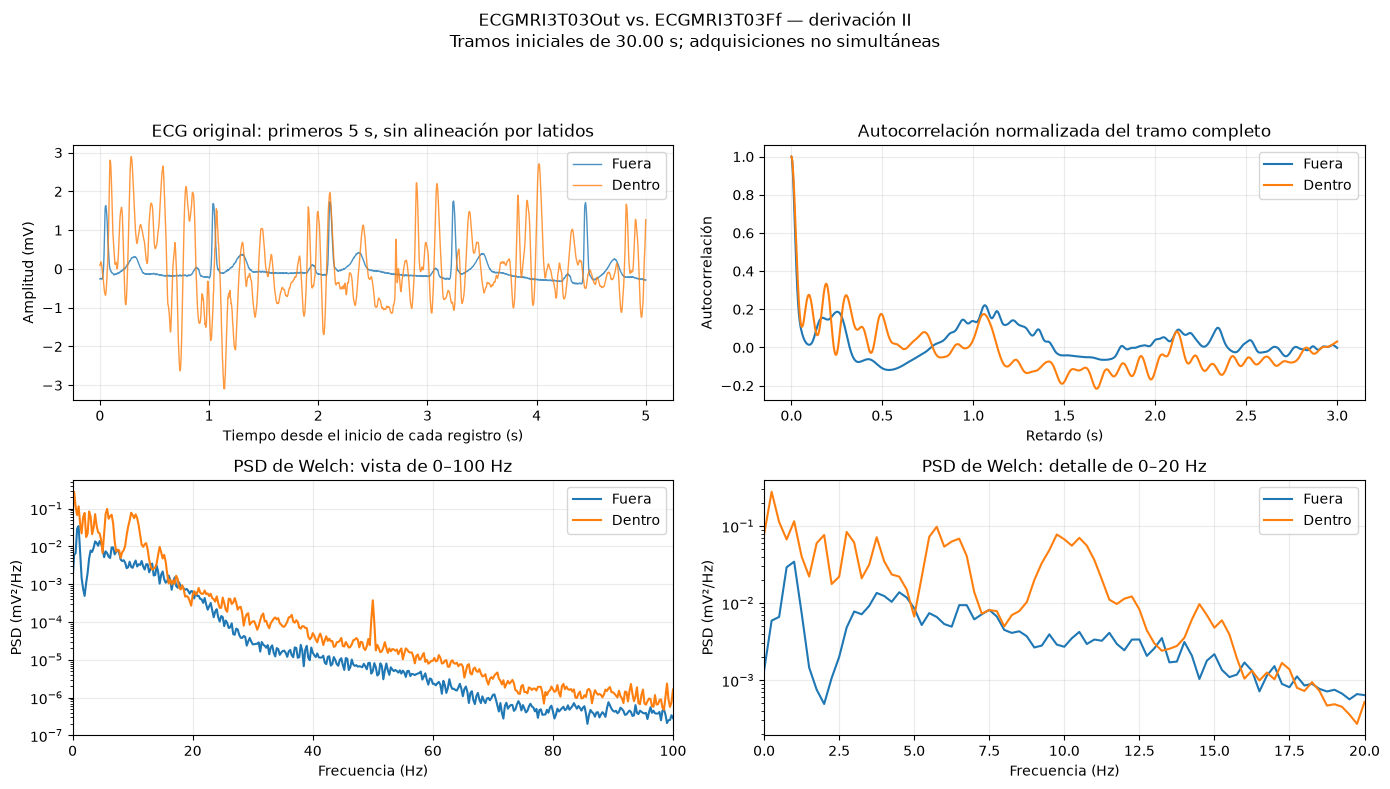

,Condición,Duración analizada (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,Fuera,30.0,-0.0057,0.1012,0.3181,14
1,Dentro,30.0,0.0269,0.6390,0.7998,14


Comparación dentro–fuera: serie de 7 T


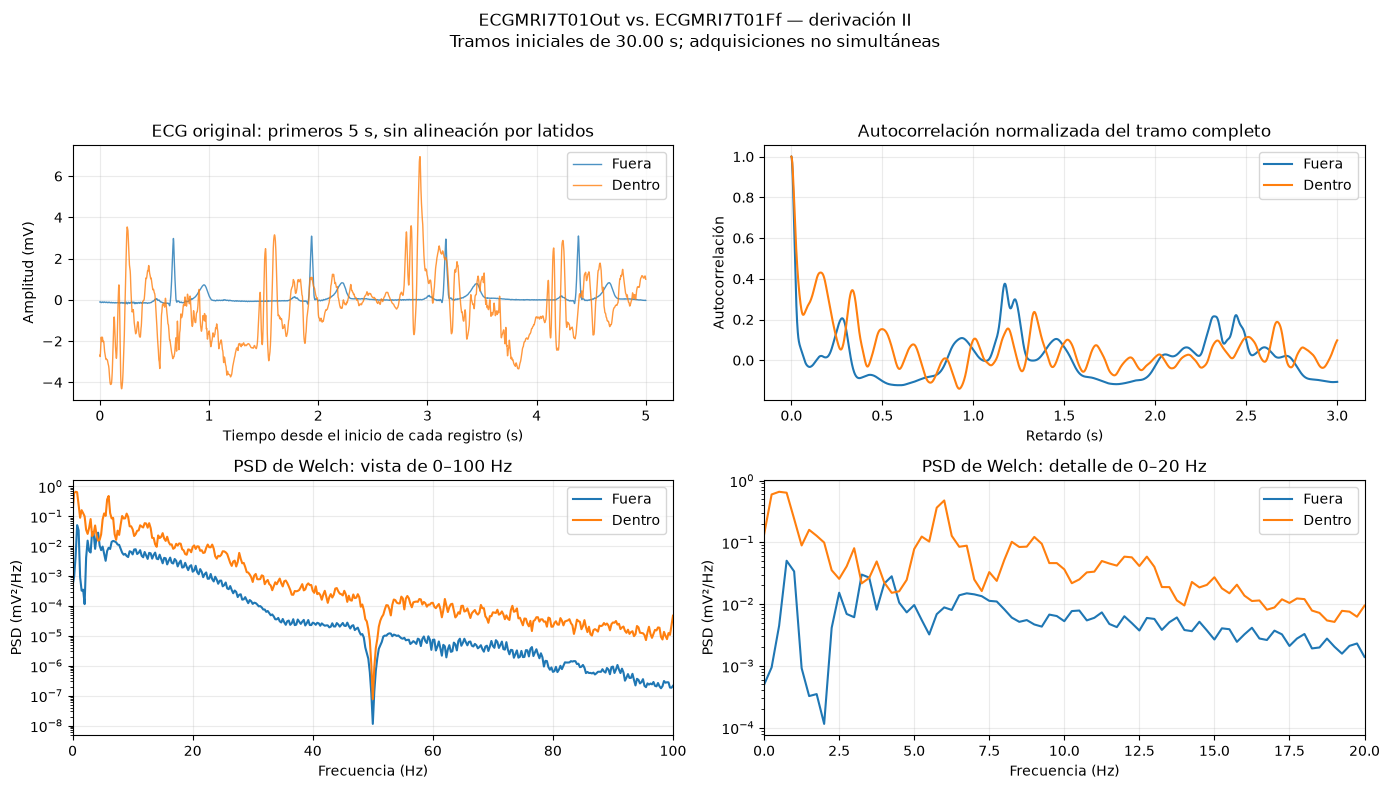

,Condición,Duración analizada (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,Fuera,30.0,0.0467,0.1574,0.3995,14
1,Dentro,30.0,-0.0721,1.7909,1.3402,14


In [16]:
# La derivación II se utiliza como ejemplo de visualización.
# La caracterización general de la celda 2 incluye todas las derivaciones.

print("Comparación dentro–fuera: serie de 3 T")

comparacion_3t = comparar_registros(
    nombre_fuera="ECGMRI3T03Out",
    nombre_dentro="ECGMRI3T03Ff",
    derivacion="II",
)

display(comparacion_3t.round(4))


print("Comparación dentro–fuera: serie de 7 T")

comparacion_7t = comparar_registros(
    nombre_fuera="ECGMRI7T01Out",
    nombre_dentro="ECGMRI7T01Ff",
    derivacion="II",
)

display(comparacion_7t.round(4))

### Conclusión de la caracterización temporal y frecuencial

En los dos ejemplos analizados —3T03 y 7T01, derivación II—,
los registros adquiridos dentro del resonador presentan oscilaciones
de mayor amplitud y una morfología cardíaca menos claramente
reconocible que sus referencias externas.

Las autocorrelaciones conservan máximos compatibles con la repetición
de los ciclos cardíacos, pero muestran diferencias entre condiciones,
especialmente a retardos cortos. Por lo tanto, la presencia de
periodicidad no garantiza la preservación de la morfología del ECG.

En ambos pares, la PSD muestra una mayor potencia del registro
interno en amplias regiones del espectro, con diferencias destacadas
en bajas frecuencias. Estas diferencias se superponen con el contenido
frecuencial del ECG, lo que evidencia la dificultad de atenuarlas
mediante filtros convencionales sin modificar también componentes
cardíacas. El análisis espectral por sí solo no permite separar
la contribución del MHD de otras fuentes de interferencia.

También se observan comportamientos diferentes alrededor de 50 Hz:
un pico estrecho en el registro interno de 3T03 y una atenuación
marcada en ambos registros de 7T01. Esto indica que el tratamiento
de la interferencia de red debe considerar las características
de cada registro y su posible acondicionamiento previo.

Estas observaciones justifican comparar distintas estrategias
de filtrado y evaluar tanto su efecto sobre la detección de QRS
como sobre la morfología del ECG. Los resultados corresponden
a dos ejemplos y no permiten concluir que las diferencias sean
exclusivamente causadas por el MHD ni que aumenten con la intensidad
del campo, dado que se comparan sujetos distintos y adquisiciones
no simultáneas.

### Exploración del contenido espectral alrededor de 50 Hz

Para identificar picos o atenuaciones alrededor de 50 Hz, se calcula
un contraste espectral por registro y derivación:

$ C_{50} = 10 \log_{10}{(\frac{PSD media en (49–51 Hz)}{PSD media en bandas vecinas})} $ 

Como referencia local se utilizan las bandas 47–49 Hz y 51–53 Hz.
Los intervalos se implementan sin compartir bins entre bandas.

Un contraste positivo indica mayor densidad de potencia alrededor
de 50 Hz respecto de su entorno; un contraste negativo indica una
depresión relativa. Un valor próximo a cero indica niveles similares.

Las bandas son una elección exploratoria del trabajo. El indicador
no confirma por sí solo interferencia de red ni permite decidir
automáticamente la aplicación de un filtro notch.

Los resultados se representan mediante un mapa de calor por registro
y derivación, y mediante boxplots separados por condición de adquisición
y número de derivaciones. Los boxplots incluyen puntos individuales.

Cada punto representa una combinación registro–derivación.
Las derivaciones de un mismo registro no son observaciones independientes;
estas figuras se utilizan con fines descriptivos.

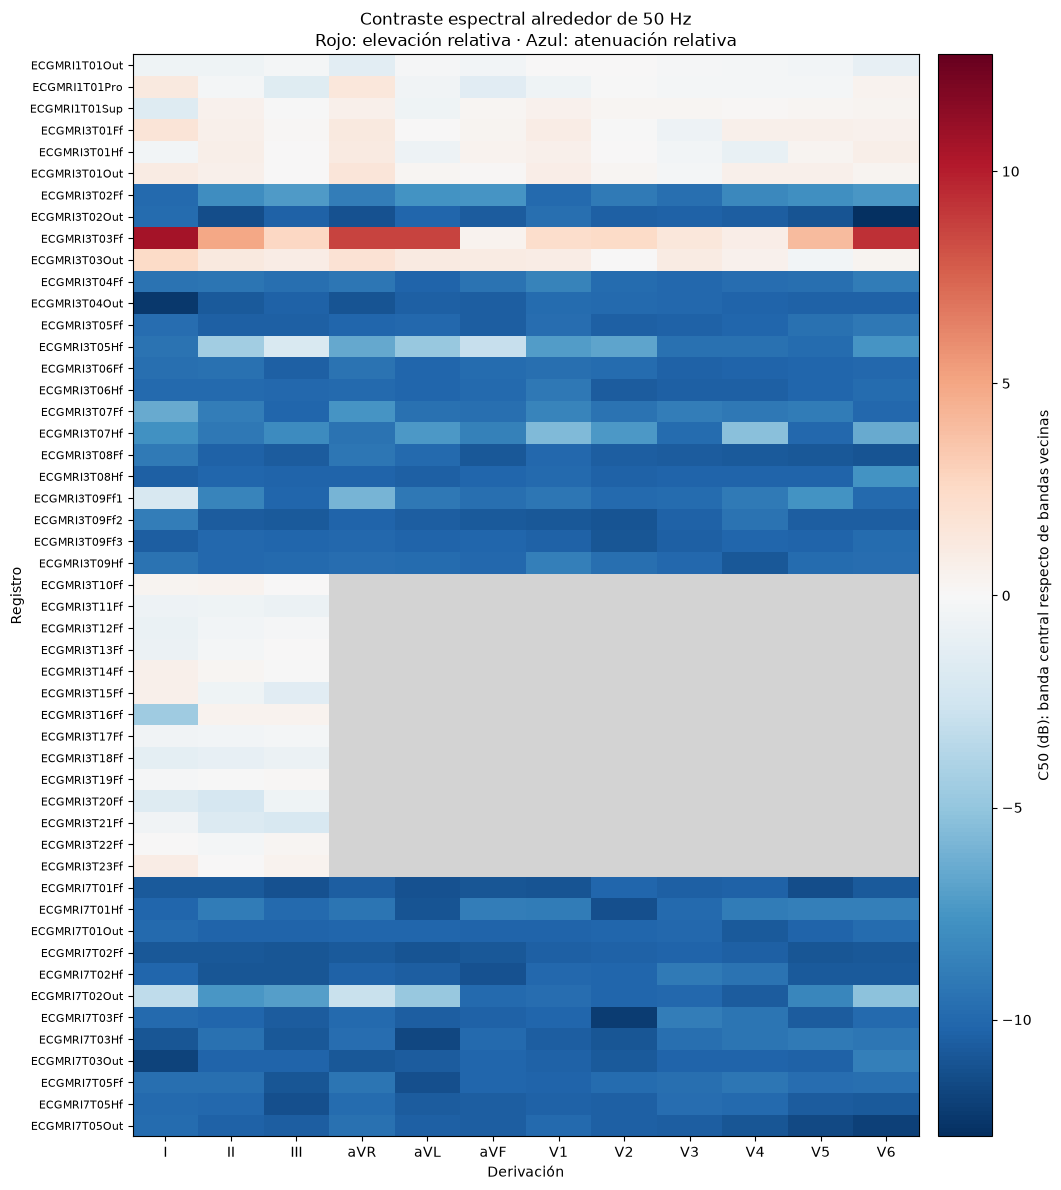

In [17]:
filas_50hz = []

for _, fila in caracteristicas.iterrows():
    nombre = fila["Registro"]
    derivacion = fila["Derivación"]

    espectro = espectros[(nombre, derivacion)]
    f = espectro["Frecuencia (Hz)"]
    psd = espectro["PSD (mV²/Hz)"]

    # Intervalos sin compartir bins:
    # central: [49, 51)
    # vecinas: [47, 49) y [51, 53)
    central = (f >= 49) & (f < 51)
    vecinas = (
        ((f >= 47) & (f < 49))
        | ((f >= 51) & (f < 53))
    )

    if not central.any() or not vecinas.any():
        raise ValueError(
            f"{nombre}, {derivacion}: faltan bins en las bandas."
        )

    media_central = np.mean(psd[central])
    media_vecinas = np.mean(psd[vecinas])

    # No se agrega una constante artificial a potencias nulas.
    if media_central > 0 and media_vecinas > 0:
        contraste = 10 * np.log10(media_central / media_vecinas)
    else:
        contraste = np.nan

    filas_50hz.append({
        "Registro": nombre,
        "Derivación": derivacion,
        "Condición": (
            "Dentro" if fila["Dentro del resonador"] else "Fuera"
        ),
        "PSD media 49–51 Hz": media_central,
        "PSD media vecinas": media_vecinas,
        "C50 (dB)": contraste,
    })

analisis_50hz = pd.DataFrame(filas_50hz)

# Incorporar la configuración de adquisición desde el inventario.
analisis_50hz = analisis_50hz.merge(
    registros_validos[["Registro", "Derivaciones"]],
    on="Registro",
    how="left",
    validate="many_to_one",
)

orden_derivaciones = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6",
]

presentes = analisis_50hz["Derivación"].unique()
orden_derivaciones = [
    d for d in orden_derivaciones if d in presentes
] + sorted(set(presentes) - set(orden_derivaciones))

orden_registros = sorted(analisis_50hz["Registro"].unique())

mapa_50hz = (
    analisis_50hz.pivot(
        index="Registro",
        columns="Derivación",
        values="C50 (dB)",
    )
    .reindex(index=orden_registros, columns=orden_derivaciones)
)

valores = mapa_50hz.to_numpy(dtype=float)
finitos = valores[np.isfinite(valores)]

if len(finitos) == 0:
    raise ValueError("No hay contrastes finitos para representar.")

# Escala simétrica: cero siempre representa igualdad con el entorno.
limite = max(float(np.max(np.abs(finitos))), 1.0)
norma = TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite)

colores = plt.get_cmap("RdBu_r").copy()
colores.set_bad("lightgray")

fig, ax = plt.subplots(
    figsize=(11, max(7, 0.24 * len(mapa_50hz)))
)

imagen = ax.imshow(
    np.ma.masked_invalid(valores),
    aspect="auto",
    cmap=colores,
    norm=norma,
    interpolation="nearest",
)

ax.set_xticks(np.arange(len(mapa_50hz.columns)))
ax.set_xticklabels(mapa_50hz.columns)

ax.set_yticks(np.arange(len(mapa_50hz.index)))
ax.set_yticklabels(mapa_50hz.index, fontsize=8)

ax.set(
    title="Contraste espectral alrededor de 50 Hz\n"
          "Rojo: elevación relativa · Azul: atenuación relativa",
    xlabel="Derivación",
    ylabel="Registro",
)

barra = fig.colorbar(imagen, ax=ax, pad=0.02)
barra.set_label("C50 (dB): banda central respecto de bandas vecinas")

plt.tight_layout()
plt.show()

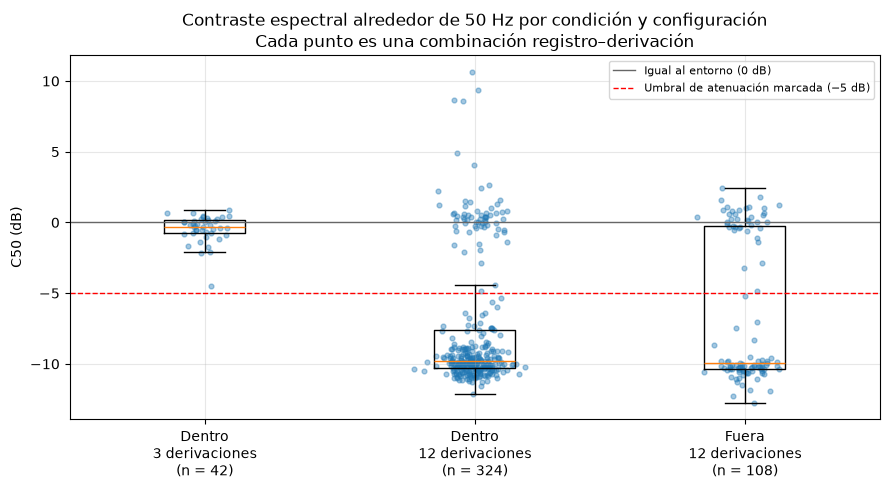

In [18]:
# Boxplots del contraste C50 por condición y configuración
grupos_c50 = (
    analisis_50hz
    .groupby(["Condición", "Derivaciones"])["C50 (dB)"]
    .apply(lambda serie: serie.dropna().to_numpy())
)

etiquetas = [
    f"{condicion}\n{derivaciones} derivaciones\n(n = {len(valores)})"
    for (condicion, derivaciones), valores in grupos_c50.items()
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(list(grupos_c50), showfliers=False)

# Puntos individuales, con un desplazamiento horizontal aleatorio
# para que no se superpongan
generador = np.random.default_rng(0)
for posicion, valores in enumerate(grupos_c50, start=1):
    ax.scatter(
        generador.normal(posicion, 0.06, len(valores)), valores,
        s=12, alpha=0.4, color="tab:blue",
    )

ax.axhline(0, color="0.4", lw=1, label="Igual al entorno (0 dB)")
# Umbral que se usa más adelante para separar los subgrupos
ax.axhline(-5, color="r", ls="--", lw=1,
           label="Umbral de atenuación marcada (−5 dB)")

ax.set_xticks(range(1, len(etiquetas) + 1))
ax.set_xticklabels(etiquetas)
ax.set(
    ylabel="C50 (dB)",
    title="Contraste espectral alrededor de 50 Hz por condición y configuración\n"
          "Cada punto es una combinación registro–derivación",
)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Resultado de la exploración alrededor de 50 Hz

El contraste espectral muestra un comportamiento heterogéneo entre
registros. En buena parte de las adquisiciones de 12 derivaciones
predominan valores negativos, tanto dentro como fuera del resonador,
indicando una depresión de la PSD alrededor de 50 Hz respecto de
las bandas vecinas. Este patrón es compatible con un posible
filtrado previo, aunque no permite confirmar su presencia ni su origen.

El registro ECGMRI3T03Ff se distingue por presentar valores positivos
en casi todas sus derivaciones, consistentes con el pico próximo
a 50 Hz observado en la inspección de su PSD.

En los registros de tres derivaciones, los contrastes son generalmente
cercanos a cero, indicando un nivel espectral similar al entorno.
Esto no implica ausencia de interferencia de red.

Los resultados no respaldan aplicar automáticamente un filtro notch
a todos los registros. La decisión deberá considerar la inspección
espectral y la magnitud de la componente en cada caso.

In [19]:
# Subgrupos según contraste espectral alrededor de 50 Hz

UMBRAL_C50_DB = -5.0

clasificacion_50hz = analisis_50hz.copy()

# Comprobar que todas las combinaciones puedan clasificarse.
if not np.isfinite(clasificacion_50hz["C50 (dB)"]).all():
    raise ValueError(
        "Hay valores C50 no definidos. Revisarlos antes de crear los grupos."
    )

clasificacion_50hz["Grupo 50 Hz"] = np.where(
    clasificacion_50hz["C50 (dB)"] < UMBRAL_C50_DB,
    "Atenuación marcada",
    "Resto",
)

# Tablas para utilizar en los análisis posteriores.
subgrupos_50hz = {
    "atenuacion_marcada": clasificacion_50hz.loc[
        clasificacion_50hz["Grupo 50 Hz"] == "Atenuación marcada"
    ].copy(),

    "resto": clasificacion_50hz.loc[
        clasificacion_50hz["Grupo 50 Hz"] == "Resto"
    ].copy(),
}

# Listas de pares (registro, derivación) para cargar las señales.
pares_por_grupo_50hz = {
    grupo: list(zip(tabla["Registro"], tabla["Derivación"]))
    for grupo, tabla in subgrupos_50hz.items()
}

# Resumen.
resumen_subgrupos_50hz = pd.DataFrame([
    {
        "Grupo": grupo,
        "Combinaciones registro–derivación": len(tabla),
        "Registros distintos": tabla["Registro"].nunique(),
    }
    for grupo, tabla in subgrupos_50hz.items()
])

display(resumen_subgrupos_50hz)

# Distribución por condición y configuración de adquisición.
display(pd.crosstab(
    index=[
        clasificacion_50hz["Condición"],
        clasificacion_50hz["Derivaciones"],
    ],
    columns=clasificacion_50hz["Grupo 50 Hz"],
))

,Grupo,Combinaciones registro–derivación,Registros distintos
0,atenuacion_marcada,328,28
1,resto,146,25


Grupo 50 Hz             Atenuación marcada  Resto
Condición Derivaciones                           
Dentro    3                              0     42
          12                           259     65
Fuera     12                            69     39

Se dividieron las combinaciones registro–derivación en dos grupos:
atenuación marcada (C50 < −5 dB) y resto (C50 ≥ −5 dB).

El umbral de −5 dB es un criterio operativo exploratorio del trabajo:
corresponde a una PSD media central inferior a aproximadamente el
31,6 % de la PSD media de las bandas vecinas. No confirma la existencia
de un filtro previo.

Ambos grupos se conservan para analizarlos por separado cuando
corresponda. El grupo restante puede incluir señales con elevación,
nivel similar o atenuación menos marcada alrededor de 50 Hz.

La clasificación se realiza por derivación; un mismo registro puede
contener derivaciones pertenecientes a ambos grupos.

## 3. Preprocesamiento mediante filtros convencionales

En esta sección se acondicionan las señales con filtros digitales convencionales, antes de abordar el efecto MHD. Los objetivos son:

- eliminar la deriva de la línea de base (componentes de muy baja frecuencia asociadas a la respiración y al movimiento de los electrodos);
- atenuar el ruido de alta frecuencia;
- atenuar la interferencia de red (50 Hz) donde la sección anterior detectó un pico.

El Holter CardioMem 3000, usado en los registros de 12 derivaciones, tiene un ancho de banda analógico de 0,05 a 100 Hz (Krug et al., 2013). Por lo tanto, las señales publicadas no están limitadas a una banda de monitoreo.

No se espera que esta etapa elimine el MHD. Su contenido se superpone con el de la onda T y el segmento ST (Krug y Rose, 2011), y Abi-Abdallah et al. (2007) observaron que por debajo de 5–6 Hz sigue siendo dominante. El objetivo es acondicionar la señal para las etapas siguientes y cuantificar cuánto de la diferencia dentro–fuera persiste después de un filtrado convencional.

### Elección de la banda de paso

Para fijar los cortes se analizan dos datos:

- la frecuencia cardíaca mínima del conjunto, porque el corte inferior tiene que quedar por debajo del ritmo cardíaco del registro más lento;
- la **potencia acumulada** de las señales originales: para cada frecuencia, qué porcentaje de la potencia total de la señal está por debajo de esa frecuencia (a partir de las PSD de Welch de la sección 2). Se grafica la curva típica (mediana) de cada grupo. Leyendo la curva en un corte candidato se ve directamente cuánta potencia quedaría de cada lado.

FC media mínima del conjunto: 46.5 lpm = 0.78 Hz


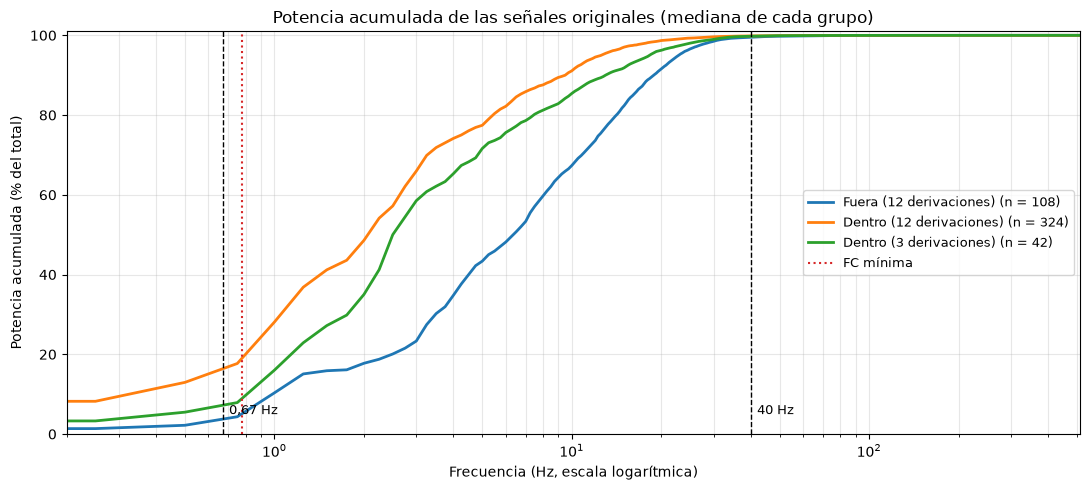

,"% de potencia por debajo de 0,67 Hz",% de potencia por debajo de 40 Hz
Grupo,,
Fuera (12 derivaciones),2.2,99.5
Dentro (12 derivaciones),13.0,99.9
Dentro (3 derivaciones),5.5,99.8


In [20]:
# Datos para elegir la banda de paso

# (a) Frecuencia cardíaca: el corte inferior tiene que quedar por debajo
# del ritmo cardíaco del registro más lento.
fc_min_lpm = registros_validos["FC media (lpm)"].min()
print(f"FC media mínima del conjunto: {fc_min_lpm:.1f} lpm = {fc_min_lpm / 60:.2f} Hz")

# (b) Potencia acumulada: para cada señal, qué porcentaje de su potencia total
# está por debajo de cada frecuencia. Se usan las PSD de Welch de la sección 2.
# Después se toma la mediana de cada grupo (curva "típica" del grupo).
CORTES_CANDIDATOS_HZ = (0.67, 40.0)

grupos_acumulada = {
    "Fuera (12 derivaciones)": [],
    "Dentro (12 derivaciones)": [],
    "Dentro (3 derivaciones)": [],
}
tabla_registros = registros_validos.set_index("Registro")

for (nombre, derivacion), espectro in espectros.items():
    psd = espectro["PSD (mV²/Hz)"]
    acumulada = 100 * np.cumsum(psd) / np.sum(psd)
    fila = tabla_registros.loc[nombre]
    condicion = "Dentro" if fila["Dentro del resonador"] else "Fuera"
    grupos_acumulada[f"{condicion} ({fila['Derivaciones']} derivaciones)"].append(acumulada)

f_acum = next(iter(espectros.values()))["Frecuencia (Hz)"]   # misma grilla para todos

fig, ax = plt.subplots(figsize=(11, 5))
filas_cortes = []

for grupo, curvas in grupos_acumulada.items():
    mediana = np.median(np.vstack(curvas), axis=0)
    ax.plot(f_acum, mediana, lw=2, label=f"{grupo} (n = {len(curvas)})")
    filas_cortes.append({
        "Grupo": grupo,
        # Último bin por debajo de cada corte (bins cada 0,25 Hz)
        **{f"% de potencia por debajo de {c:g} Hz".replace(".", ","):
               mediana[np.searchsorted(f_acum, c) - 1]
           for c in CORTES_CANDIDATOS_HZ},
    })

for corte in CORTES_CANDIDATOS_HZ:
    ax.axvline(corte, color="k", ls="--", lw=1)
    ax.text(corte * 1.05, 5, f"{corte:g} Hz".replace(".", ","), fontsize=9)
ax.axvline(fc_min_lpm / 60, color="tab:red", ls=":", lw=1.5, label="FC mínima")

ax.set(xscale="log", xlim=(0.2, 512), ylim=(0, 101),
       xlabel="Frecuencia (Hz, escala logarítmica)",
       ylabel="Potencia acumulada (% del total)",
       title="Potencia acumulada de las señales originales (mediana de cada grupo)")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=9, loc="center right")
plt.tight_layout()
plt.show()

display(pd.DataFrame(filas_cortes).set_index("Grupo").round(1))

**Corte inferior: 0,67 Hz:** La frecuencia cardíaca media mínima del conjunto es 46,5 lpm (0,78 Hz, línea roja). Un corte en 0,67 Hz (40 lpm) queda por debajo del ritmo más lento. En la curva de las referencias externas, por debajo de 0,67 Hz está solo el 2,2 % de la potencia: la deriva existe pero es chica. Dentro del resonador ese porcentaje sube a 13 % en los registros de 12 derivaciones y a 5,5 % en los de 3 derivaciones, es decir, la deriva pesa más dentro del resonador.

**Corte superior: 40 Hz:** En las tres curvas, a 40 Hz ya se acumuló más del 99,5 % de la potencia: por encima de 40 Hz queda menos del 0,5 %. Es coherente con la bibliografía: la banda que maximiza la energía del QRS está aproximadamente entre 5 y 15 Hz (Pan y Tompkins, 1985), las ondas P y T tienen densidad espectral significativa solo hasta ~10 Hz y la mayor parte de la potencia del QRS se ubica entre 3 y 20 Hz (Abi-Abdallah et al., 2007). Además, el corte en 40 Hz deja 50 Hz fuera de la banda de paso. Como limitación, puede reducir levemente la amplitud de los picos del QRS; al aplicarse el mismo filtro dentro y fuera del resonador, la comparación entre condiciones no se ve afectada.

**Observación:** Las curvas de los registros dentro del resonador suben antes que la de las referencias externas: por ejemplo, alrededor de 5 Hz ya acumulan el 72–77 % de su potencia, contra el 43 % fuera. Dentro del resonador la potencia está corrida hacia frecuencias bajas, la misma zona que ocupan la onda T y el ST. Esto anticipa que el pasabanda no va a poder separar esa componente.

**Fase cero:** Uno de los objetivos del trabajo es evaluar la morfología del ST y de la onda T, por lo que los filtros no deben introducir distorsión de fase. La necesidad de esta condición se verifica más abajo con el retardo de grupo.

### Diseños comparados

Se diseña el mismo pasabanda de dos formas:

- **FIR por ventana de Kaiser** (`firwin`): La ventana de Kaiser permite fijar la atenuación mínima en la banda de rechazo y el ancho de la transición; `kaiserord` calcula el orden necesario (Harris, 1978). Se pide una atenuación de 40 dB y una transición de 0,5 Hz. Una transición tan angosta es necesaria porque entre el corte de 0,67 Hz y la fundamental de 0,78 Hz hay solo 0,1 Hz de margen. Por ser simétrico, el FIR tiene fase lineal.
- **IIR Butterworth** (`butter`), de orden 4, implementado en secciones de segundo orden por estabilidad numérica. Tiene la respuesta más plana en la banda de paso entre los IIR clásicos, pero su fase no es lineal.

In [21]:

# Diseño de los pasabanda FIR e IIR
FS = 1024.0                     
BANDA_PASO_HZ = (0.67, 40.0) 

# FIR: ventana de Kaiser
ATENUACION_FIR_DB = 40.0 # atenuación mínima en la banda de rechazo
TRANSICION_FIR_HZ = 0.5 # ancho de la banda de transición

# IIR: Butterworth
ORDEN_BUTTER = 4

# --- FIR ---
# kaiserord recibe el ancho de transición normalizado por la frecuencia de Nyquist
n_coef_fir, beta_kaiser = signal.kaiserord(
    ATENUACION_FIR_DB, TRANSICION_FIR_HZ / (FS / 2)
)
n_coef_fir |= 1 # longitud impar: retardo entero de (N − 1)/2 muestras

coef_fir = signal.firwin(
    n_coef_fir,
    BANDA_PASO_HZ,
    window=("kaiser", beta_kaiser),
    pass_zero=False,
    fs=FS,
)
retardo_fir = (n_coef_fir - 1) // 2

# --- IIR ---
# Secciones de segundo orden (sos): con fs = 1024 Hz, el corte de 0,67 Hz está
# muy cerca de 0 en frecuencia normalizada y la forma directa (b, a) pierde
# precisión numérica.
sos_butter = signal.butter(
    ORDEN_BUTTER, BANDA_PASO_HZ, btype="bandpass", fs=FS, output="sos"
)

# Respuestas en frecuencia
N_PUNTOS = 2**18
f_resp, h_fir = signal.freqz(coef_fir, worN=N_PUNTOS, fs=FS)
_, h_butter = signal.sosfreqz(sos_butter, worN=N_PUNTOS, fs=FS)


def a_db(h):
    return 20 * np.log10(np.maximum(np.abs(h), 1e-12))


# Magnitudes efectivas tal como se van a aplicar:
# el FIR una sola vez (compensando el retardo);
# el Butterworth hacia adelante y hacia atrás, que eleva la magnitud al cuadrado.
mag_fir_db = a_db(h_fir)
mag_butter_db = 2 * a_db(h_butter)


def valor_en(mag_db, frecuencia):
    return mag_db[np.argmin(np.abs(f_resp - frecuencia))]


frecuencias_control = {
    "0 Hz (continua)": 0.0,
    "0,3 Hz (deriva)": 0.3,
    f"{fc_min_lpm / 60:.2f} Hz (FC mínima)".replace(".", ","): fc_min_lpm / 60,
    "35 Hz": 35.0,
    "50 Hz (red)": 50.0,
}

tabla_diseno = pd.DataFrame(
    {
        "FIR Kaiser": [valor_en(mag_fir_db, f) for f in frecuencias_control.values()],
        f"Butterworth orden {ORDEN_BUTTER} (ida y vuelta)":
            [valor_en(mag_butter_db, f) for f in frecuencias_control.values()],
    },
    index=[f"Ganancia en {k} (dB)" for k in frecuencias_control],
)

print(f"FIR: {n_coef_fir} coeficientes, respuesta al impulso de {n_coef_fir / FS:.2f} s, "
      f"retardo de {retardo_fir / FS:.2f} s")
print(f"Butterworth: {sos_butter.shape[0]} secciones de 2.º orden ({sos_butter.size} coeficientes)")
display(tabla_diseno.round(2))

FIR: 4573 coeficientes, respuesta al impulso de 4.47 s, retardo de 2.23 s
Butterworth: 4 secciones de 2.º orden (24 coeficientes)


,FIR Kaiser,Butterworth orden 4 (ida y vuelta)
Ganancia en 0 Hz (continua) (dB),-42.95,-480.00
"Ganancia en 0,3 Hz (deriva) (dB)",-47.26,-56.60
"Ganancia en 0,78 Hz (FC mínima) (dB)",-2.11,-2.26
Ganancia en 35 Hz (dB),-0.00,-2.45
Ganancia en 50 Hz (red) (dB),-74.87,-17.39


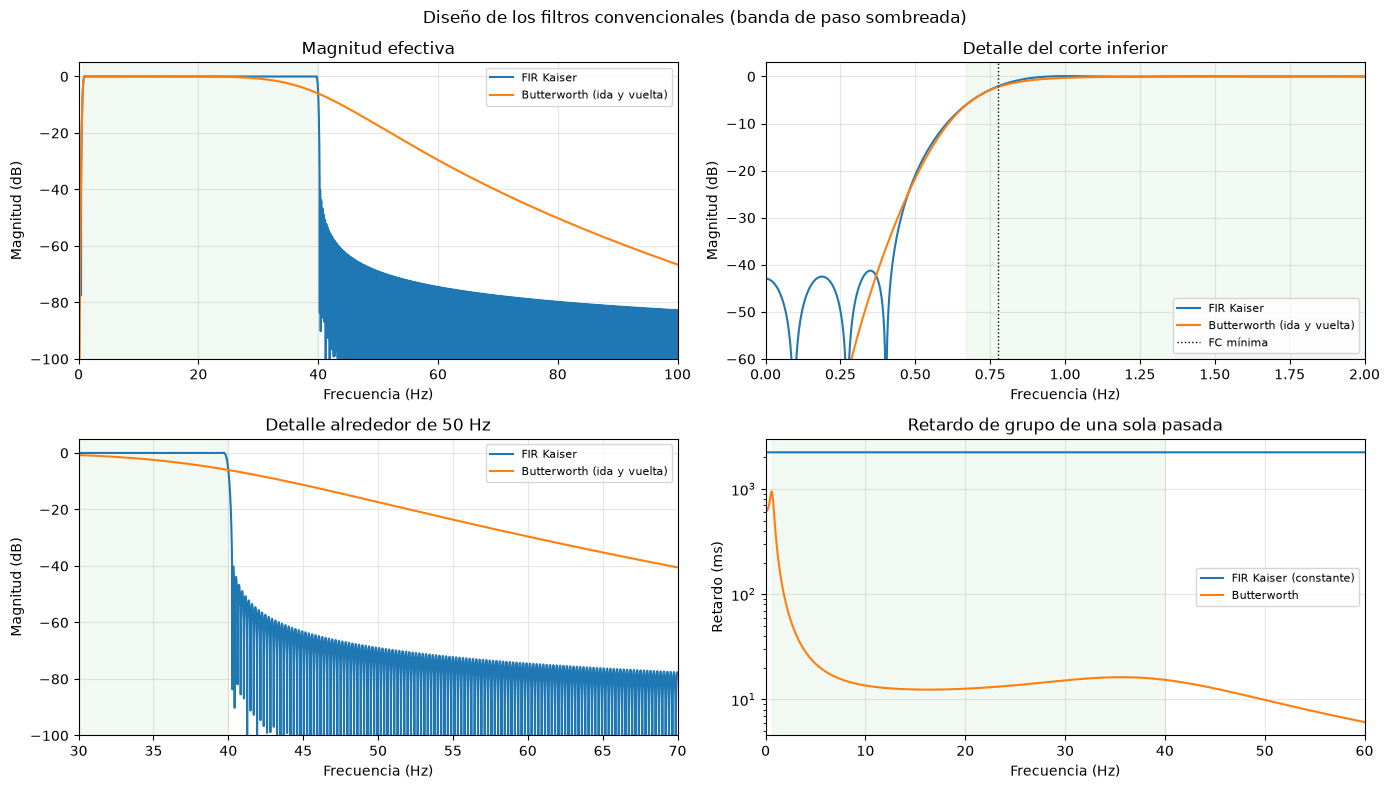

Retardo de grupo del Butterworth en 0,67–40 Hz: 12 a 863 ms
Retardo de grupo del FIR: 2232 ms en todas las frecuencias


In [22]:
# Respuestas en frecuencia y retardo de grupo
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))

for ax, (xlim, ylim, titulo) in zip(
    [ejes[0, 0], ejes[0, 1], ejes[1, 0]],
    [((0, 100), (-100, 5), "Magnitud efectiva"),
     ((0, 2), (-60, 3), "Detalle del corte inferior"),
     ((30, 70), (-100, 5), "Detalle alrededor de 50 Hz")],
):
    ax.plot(f_resp, mag_fir_db, label="FIR Kaiser")
    ax.plot(f_resp, mag_butter_db, label="Butterworth (ida y vuelta)")
    ax.set(xlim=xlim, ylim=ylim, title=titulo,
           xlabel="Frecuencia (Hz)", ylabel="Magnitud (dB)")

ejes[0, 1].axvline(fc_min_lpm / 60, color="k", ls=":", lw=1, label="FC mínima")

# Retardo de grupo de UNA pasada de cada filtro
f_gd = np.linspace(0.1, 60, 2000)
_, gd_fir = signal.group_delay((coef_fir, 1.0), w=f_gd, fs=FS)

_, h_gd = signal.sosfreqz(sos_butter, worN=f_gd, fs=FS)
fase = np.unwrap(np.angle(h_gd))
gd_butter = -np.gradient(fase, 2 * np.pi * f_gd / FS)

ax = ejes[1, 1]
ax.plot(f_gd, gd_fir / FS * 1000, label="FIR Kaiser (constante)")
ax.plot(f_gd, gd_butter / FS * 1000, label="Butterworth")
ax.set(xlim=(0, 60), yscale="log", title="Retardo de grupo de una sola pasada",
       xlabel="Frecuencia (Hz)", ylabel="Retardo (ms)")

for ax in ejes.flat:
    ax.axvspan(*BANDA_PASO_HZ, color="tab:green", alpha=0.06)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Diseño de los filtros convencionales (banda de paso sombreada)")
plt.tight_layout()
plt.show()

# Variación del retardo del Butterworth dentro de la banda de paso
en_banda = (f_gd >= BANDA_PASO_HZ[0]) & (f_gd <= BANDA_PASO_HZ[1])
print(f"Retardo de grupo del Butterworth en 0,67–40 Hz: "
      f"{gd_butter[en_banda].min() / FS * 1000:.0f} a {gd_butter[en_banda].max() / FS * 1000:.0f} ms")
print(f"Retardo de grupo del FIR: {retardo_fir / FS * 1000:.0f} ms en todas las frecuencias")

### Resultado del diseño

- **Costo:** El FIR necesita 4573 coeficientes (respuesta al impulso de 4,47 s); el Butterworth, 24 (4 secciones de segundo orden).
- **Banda de paso:** El FIR es plano hasta 40 Hz (0,00 dB en 35 Hz). El Butterworth empieza a atenuar antes del corte (−2,45 dB en 35 Hz) y cae en forma gradual.
- **Corte inferior:** Ambos atenúan la deriva de forma similar (−47 dB y −57 dB en 0,3 Hz) y la fundamental del ritmo más lento casi igual (−2,1 y −2,3 dB en 0,78 Hz). La diferencia aparece en 0 Hz: el Butterworth anula completamente la continua, pero el FIR la atenúa solo 43 dB. Esto puede dejar un residuo si la señal tiene un nivel de continua alto-
- **50 Hz:** El FIR atenúa 50 Hz en 75 dB; el Butterworth, solo 17 dB.
- **Fase:** El retardo de grupo del FIR es constante (2232 ms) en todas las frecuencias. El del Butterworth varía entre 12 y 863 ms dentro de la banda de paso, con los valores más altos en las frecuencias más bajas, donde está la energía de la onda T y del ST. Aplicado una sola vez, desplazaría esas componentes respecto del QRS y deformaría la morfología.

En consecuencia, se aplican con fase cero:

- **FIR**: se compensa el retardo constante desplazando la salida (N − 1)/2 muestras.
- **IIR**: se aplica hacia adelante y hacia atrás (`sosfiltfilt`), lo que anula la fase y eleva la magnitud al cuadrado. Las magnitudes de la tabla y de la figura ya incluyen este efecto. Por eso el corte efectivo de ambos filtros queda en −6 dB.

### Nivel de continua

Como el FIR no anula la continua, se revisa el valor medio de cada derivación y el residuo que dejaría a la salida.

In [23]:
# Aplicación de los pasabanda con fase cero
def filtrar_fir(x):
    """Pasabanda FIR: convolución y compensación del retardo de (N − 1)/2 muestras.

    Antes de filtrar, la señal se extiende en ambos extremos con su reflejo
    impar (igual que hace filtfilt), para reducir el transitorio de los bordes.
    """
    x = np.asarray(x, dtype=float)
    if len(x) <= retardo_fir:
        raise ValueError("La señal es más corta que el retardo del FIR.")

    inicio = 2 * x[0] - x[retardo_fir:0:-1]
    final = 2 * x[-1] - x[-2:-retardo_fir - 2:-1]
    extendida = np.concatenate([inicio, x, final])

    # mode="same" con longitud impar devuelve la salida centrada,
    # es decir, ya desplazada (N − 1)/2 muestras
    salida = signal.fftconvolve(extendida, coef_fir, mode="same")
    return salida[retardo_fir:retardo_fir + len(x)]


def filtrar_iir(x):
    """Pasabanda Butterworth hacia adelante y hacia atrás (fase cero)."""
    return signal.sosfiltfilt(sos_butter, np.asarray(x, dtype=float))

In [24]:
# Nivel de continua de los registros y residuo esperado tras el filtrado
medias = caracteristicas.merge(
    registros_validos[["Registro", "Derivaciones"]], on="Registro", validate="many_to_one"
)
medias["|Media| (mV)"] = medias["Media (mV)"].abs()

ganancia_continua = {
    "FIR": 10 ** (valor_en(mag_fir_db, 0.0) / 20),
    "IIR": 10 ** (valor_en(mag_butter_db, 0.0) / 20),
}

resumen_continua = medias.groupby("Derivaciones")["|Media| (mV)"].agg(
    Mediana="median", Máximo="max"
)
# Residuo de continua que quedaría a la salida si no se resta la media
for metodo, ganancia in ganancia_continua.items():
    resumen_continua[f"Residuo máximo con {metodo} (mV)"] = resumen_continua["Máximo"] * ganancia

print("Valor absoluto de la media por derivación (mV):")
display(resumen_continua.round(4))

# Comprobación sobre la derivación con mayor nivel de continua
peor = medias.loc[medias["|Media| (mV)"].idxmax()]
registro = wfdb.rdrecord(str(carpeta_data / peor["Registro"]))
x = registro.p_signal[:, registro.sig_name.index(peor["Derivación"])]
borde = retardo_fir

print(f"\n{peor['Registro']} — {peor['Derivación']}: media original = {np.mean(x):.2f} mV")
for etiqueta, y in [
    ("FIR sin restar la media", filtrar_fir(x)),
    ("FIR restando la media", filtrar_fir(x - np.mean(x))),
    ("IIR sin restar la media", filtrar_iir(x)),
]:
    print(f"   {etiqueta:26s} → media de la salida = {np.mean(y[borde:-borde]):+.4f} mV")

Valor absoluto de la media por derivación (mV):


,Mediana,Máximo,Residuo máximo con FIR (mV),Residuo máximo con IIR (mV)
Derivaciones,,,,
3,2.6391,28.4132,0.2024,0.0
12,0.0032,15.0686,0.1073,0.0



ECGMRI3T17Ff — II: media original = -28.41 mV
   FIR sin restar la media    → media de la salida = +0.2021 mV
   FIR restando la media      → media de la salida = -0.0003 mV
   IIR sin restar la media    → media de la salida = -0.0003 mV


Los registros de 3 derivaciones (monitor del resonador) tienen un nivel de continua típico de 2,6 mV, y algunas derivaciones de ambos equipos llegan a 15–28 mV, entre 10 y 20 veces la amplitud del QRS. Con 43 dB de atenuación en 0 Hz, el FIR dejaría hasta 0,2 mV de continua a la salida. En la derivación II de ECGMRI3T17Ff (media de −28,4 mV), la media de la salida del FIR es de +0,20 mV sin restar la media y de −0,0003 mV restándola, igual que con el Butterworth.

Se toma la decisión de que antes de filtrar se resta la media de cada derivación. Es una operación que no modifica el resto del espectro y hace equivalentes ambos diseños en 0 Hz.

### Filtro notch

Se diseña un notch IIR de segundo orden en 50 Hz (`iirnotch`) con Q = 30. Su ancho de banda, f₀/Q ≈ 1,7 Hz, coincide aproximadamente con la banda central de 49–51 Hz usada para el contraste C50 de la sección 2. Se identifican las derivaciones con un pico relativo marcado en 50 Hz con el criterio **C50 > +3 dB** (PSD central de al menos el doble que la de las bandas vecinas), y se compara el efecto del notch combinado con cada pasabanda en la derivación con mayor C50.
Esta separación es distinta de la realizada en la sección 2. Aquella identifica las derivaciones con atenuación marcada alrededor de 50 Hz (C50 < −5 dB), que no requieren notch. El grupo restante, en cambio, incluye señales con pico, con nivel similar al entorno y con atenuación leve, y solo las primeras tienen una componente de red para eliminar. Por eso, dentro de ese grupo se distingue a las derivaciones con un pico marcado (C50 > +3 dB). 

Ancho de banda del notch: 1.67 Hz

Derivaciones con C50 > +3 dB: 6
   ECGMRI3T03Ff — I  (C50 = +10.6 dB)
   ECGMRI3T03Ff — II  (C50 = +4.9 dB)
   ECGMRI3T03Ff — V5  (C50 = +4.1 dB)
   ECGMRI3T03Ff — V6  (C50 = +9.3 dB)
   ECGMRI3T03Ff — aVL  (C50 = +8.6 dB)
   ECGMRI3T03Ff — aVR  (C50 = +8.6 dB)


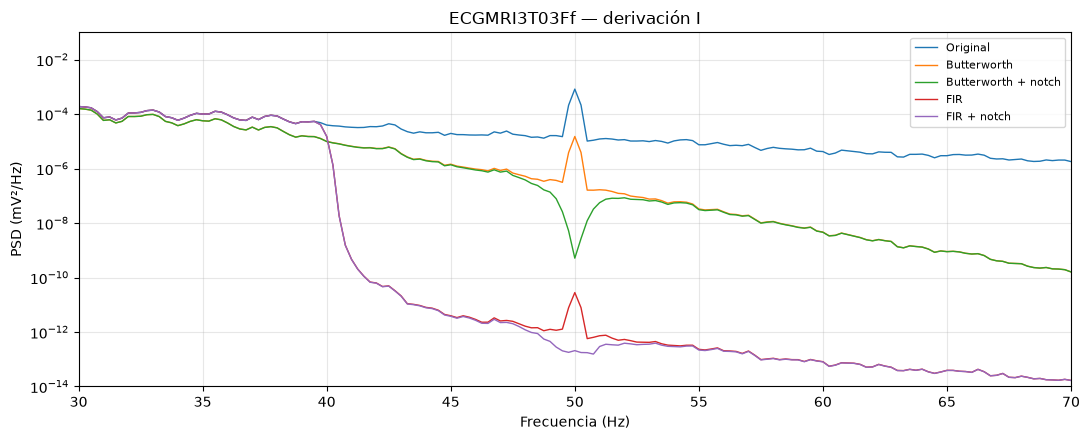

,Versión,PSD media 49–51 Hz (dB re 1 mV²/Hz),Cambio respecto del original (dB)
0,Original,-37.8,0.0
1,Butterworth,-55.2,-17.4
2,Butterworth + notch,-74.3,-36.5
3,FIR,-112.2,-74.3
4,FIR + notch,-126.4,-88.6


In [25]:
# Diseño del notch y evaluación en el registro con pico en 50 Hz
FRECUENCIA_RED_HZ = 50.0
Q_NOTCH = 30.0 # ancho de banda = f0 / Q
UMBRAL_NOTCH_C50_DB = 3.0 # pico: PSD central ≥ 2 veces la de las bandas vecinas

b_notch, a_notch = signal.iirnotch(FRECUENCIA_RED_HZ, Q_NOTCH, fs=FS)
print(f"Ancho de banda del notch: {FRECUENCIA_RED_HZ / Q_NOTCH:.2f} Hz")

# Derivaciones con pico relativo en 50 Hz, según el C50 de la sección 2
c50 = analisis_50hz.set_index(["Registro", "Derivación"])["C50 (dB)"]
derivaciones_pico_50hz = set(c50[c50 > UMBRAL_NOTCH_C50_DB].index)

print(f"\nDerivaciones con C50 > {UMBRAL_NOTCH_C50_DB:+.0f} dB: {len(derivaciones_pico_50hz)}")
for nombre, derivacion in sorted(derivaciones_pico_50hz):
    print(f"   {nombre} — {derivacion}  (C50 = {c50[(nombre, derivacion)]:+.1f} dB)")

# Evaluación en la derivación con mayor C50
nombre_notch, derivacion_notch = max(derivaciones_pico_50hz, key=lambda k: c50[k])
registro = wfdb.rdrecord(str(carpeta_data / nombre_notch))
x = registro.p_signal[:, registro.sig_name.index(derivacion_notch)]
x = x - np.mean(x)


def notch(y):
    return signal.filtfilt(b_notch, a_notch, y)


versiones = {
    "Original": x,
    "Butterworth": filtrar_iir(x),
    "Butterworth + notch": notch(filtrar_iir(x)),
    "FIR": filtrar_fir(x),
    "FIR + notch": notch(filtrar_fir(x)),
}

fig, ax = plt.subplots(figsize=(11, 4.5))
filas_notch = []
for etiqueta, y in versiones.items():
    f, psd, _ = calcular_psd(y, FS)
    ax.semilogy(f, psd, lw=1, label=etiqueta)
    filas_notch.append({
        "Versión": etiqueta,
        "PSD media 49–51 Hz (dB re 1 mV²/Hz)":
            10 * np.log10(np.mean(psd[(f >= 49) & (f < 51)])),
    })

ax.set(xlim=(30, 70), ylim=(1e-14, 1e-1),
       title=f"{nombre_notch} — derivación {derivacion_notch}",
       xlabel="Frecuencia (Hz)", ylabel="PSD (mV²/Hz)")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

tabla_notch = pd.DataFrame(filas_notch)
tabla_notch["Cambio respecto del original (dB)"] = (
    tabla_notch.iloc[:, 1] - tabla_notch.iloc[0, 1]
)
display(tabla_notch.round(1))

Solo 6 derivaciones, todas de ECGMRI3T03Ff, cumplieron el criterio C50 > +3 dB. En su derivación I:

- el Butterworth reduce la PSD en 49–51 Hz en 17,4 dB, y el notch agrega otros 19 dB (−36,5 dB en total);
- el FIR solo la reduce 74,3 dB, es decir, 38 dB más que el Butterworth con notch. Agregarle el notch lleva la reducción a 88,6 dB, sobre una componente que ya estaba muy por debajo del resto del espectro.

**Decisión:** el notch solo forma parte de la cadena IIR y se aplica únicamente a las derivaciones con C50 > +3 dB. En la cadena FIR no se aplica, porque el pasabanda ya deja 50 Hz en su banda de rechazo. Las derivaciones con atenuación alrededor de 50 Hz no tienen una componente para eliminar.

### Preprocesamiento completo

Con estas decisiones, cada derivación se procesa así:

1. Remoción de la media.
2. Pasabanda de 0,67–40 Hz con fase cero (FIR o IIR).
3. Solo en la cadena IIR: notch de 50 Hz en las derivaciones con C50 > +3 dB.

In [26]:
# Preprocesamiento completo
def preprocesar(x, nombre, derivacion, metodo):
    """Preprocesamiento de una derivación.

    1. Se resta la media.
    2. Pasabanda FIR o IIR (metodo: "FIR" o "IIR"), con fase cero.
    3. Notch de 50 Hz, solo en la cadena IIR y solo en las derivaciones
       con C50 > +3 dB.
    """
    x = np.asarray(x, dtype=float)
    x = x - np.mean(x)

    if metodo == "FIR":
        return filtrar_fir(x)
    if metodo == "IIR":
        y = filtrar_iir(x)
        if (nombre, derivacion) in derivaciones_pico_50hz:
            y = signal.filtfilt(b_notch, a_notch, y)
        return y
    raise ValueError(f"Método desconocido: {metodo}")


def cargar_preprocesado(nombre, metodo):
    """Lee un registro y devuelve (fs, derivaciones, matriz muestras × derivaciones).

    Las señales filtradas no se guardan en memoria para todos los registros
    (ocuparían varios GB); se recalculan cuando se necesitan.
    """
    registro = wfdb.rdrecord(str(carpeta_data / nombre))
    matriz = np.column_stack([
        preprocesar(registro.p_signal[:, i], nombre, derivacion, metodo)
        for i, derivacion in enumerate(registro.sig_name)
    ])
    return float(registro.fs), list(registro.sig_name), matriz

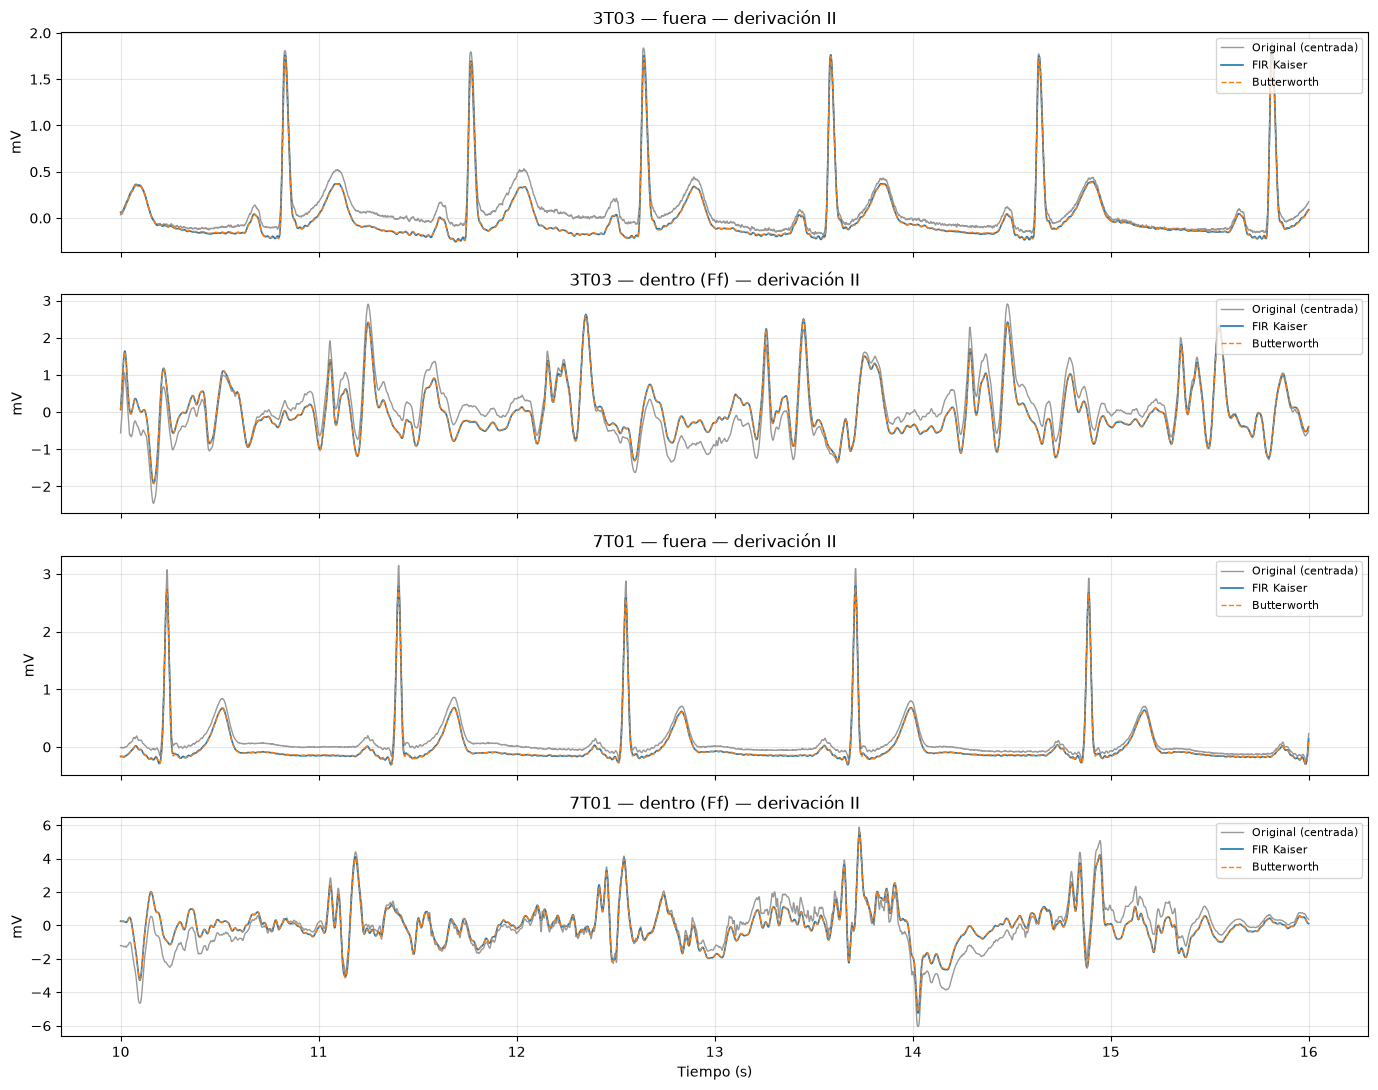

In [27]:
# Ejemplos: señal original y filtrada (3T03 y 7T01, derivación II)
DERIVACION_EJEMPLO = "II"
INICIO_S, DURACION_S = 10.0, 6.0     # tramo visualizado, lejos de los bordes

ejemplos = [
    ("ECGMRI3T03Out", "3T03 — fuera"),
    ("ECGMRI3T03Ff", "3T03 — dentro (Ff)"),
    ("ECGMRI7T01Out", "7T01 — fuera"),
    ("ECGMRI7T01Ff", "7T01 — dentro (Ff)"),
]

fig, ejes = plt.subplots(len(ejemplos), 1, figsize=(14, 11), sharex=True)

for ax, (nombre, titulo) in zip(ejes, ejemplos):
    registro = wfdb.rdrecord(str(carpeta_data / nombre))
    fs = float(registro.fs)
    canal = registro.sig_name.index(DERIVACION_EJEMPLO)
    x = registro.p_signal[:, canal]

    i0, i1 = int(INICIO_S * fs), int((INICIO_S + DURACION_S) * fs)
    t = np.arange(i0, i1) / fs

    # La señal original se centra (sin filtrar) solo para poder superponerla
    ax.plot(t, x[i0:i1] - np.median(x[i0:i1]), color="0.6", lw=1,
            label="Original (centrada)")
    ax.plot(t, preprocesar(x, nombre, DERIVACION_EJEMPLO, "FIR")[i0:i1],
            lw=1.2, label="FIR Kaiser")
    ax.plot(t, preprocesar(x, nombre, DERIVACION_EJEMPLO, "IIR")[i0:i1],
            "--", lw=1, label="Butterworth")

    ax.set(title=f"{titulo} — derivación {DERIVACION_EJEMPLO}", ylabel="mV")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper right")

ejes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

### Resultado de la aplicación

En las referencias externas (3T03 y 7T01 fuera), ambos filtros eliminan la deriva de la línea de base y conservan la forma del P-QRS-T. La diferencia entre FIR y Butterworth es casi imperceptible y aparece sobre todo en los picos del QRS, donde el Butterworth atenúa levemente por su caída gradual cerca de 40 Hz.

En los registros dentro del resonador, el filtrado elimina la deriva, pero la forma de onda sigue dominada por oscilaciones de baja frecuencia sincronizadas con cada latido, de amplitud comparable o mayor que la del QRS. Estas oscilaciones están dentro de la banda de paso y no pueden separarse del ECG con un filtro selectivo en frecuencia.

Para cuantificarlo sobre todo el conjunto, se calculan para cada combinación registro–derivación la varianza antes y después de filtrar, la diferencia entre las salidas de ambos diseños y la potencia de la señal filtrada en dos bandas: 0,67–10 Hz, donde se ubican la onda T, el ST y el MHD, y 10–40 Hz. Se excluyen los primeros y últimos 2,5 s de cada señal, donde están los transitorios del FIR.

In [28]:
# Efecto del preprocesamiento sobre todos los registros
BORDE_S = np.ceil(retardo_fir / FS * 2) / 2      # 2,5 s

BANDA_BAJA_HZ = (0.67, 10.0)     # donde se concentra el MHD (Krug y Rose, 2011)
BANDA_ALTA_HZ = (10.0, 40.0)


def potencia_en_banda(f, psd, banda):
    """Integral de la PSD en la banda [f1, f2), en mV²."""
    seleccion = (f >= banda[0]) & (f < banda[1])
    return np.sum(psd[seleccion]) * (f[1] - f[0])


filas_filtrado = []

for _, fila in registros_validos.iterrows():
    nombre = fila["Registro"]
    registro = wfdb.rdrecord(str(carpeta_data / nombre))
    fs = float(registro.fs)
    borde = int(BORDE_S * fs)

    for canal, derivacion in enumerate(registro.sig_name):
        x = registro.p_signal[:, canal]
        senales = {
            "Original": x,
            "FIR": preprocesar(x, nombre, derivacion, "FIR"),
            "IIR": preprocesar(x, nombre, derivacion, "IIR"),
        }
        senales = {k: v[borde:-borde] for k, v in senales.items()}

        resultado = {
            "Registro": nombre,
            "Sujeto": fila["Sujeto"],
            "Derivaciones": fila["Derivaciones"],
            "Derivación": derivacion,
            "Dentro del resonador": fila["Dentro del resonador"],
        }
        for metodo, y in senales.items():
            resultado[f"Varianza {metodo} (mV²)"] = np.var(y)

        # Diferencia entre ambos diseños, relativa a la amplitud de la señal filtrada
        resultado["Diferencia FIR–IIR relativa (%)"] = (
            100 * np.sqrt(np.mean((senales["FIR"] - senales["IIR"]) ** 2))
            / np.sqrt(np.mean(senales["FIR"] ** 2))
        )

        # Potencia por bandas de la señal filtrada con FIR
        f, psd, _ = calcular_psd(senales["FIR"], fs)
        resultado["Potencia 0,67–10 Hz (mV²)"] = potencia_en_banda(f, psd, BANDA_BAJA_HZ)
        resultado["Potencia 10–40 Hz (mV²)"] = potencia_en_banda(f, psd, BANDA_ALTA_HZ)

        filas_filtrado.append(resultado)

efecto_filtrado = pd.DataFrame(filas_filtrado)

print(f"Combinaciones registro–derivación: {len(efecto_filtrado)}")
print("\nDiferencia FIR–IIR relativa (%):")
display(efecto_filtrado["Diferencia FIR–IIR relativa (%)"]
        .describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2))

Combinaciones registro–derivación: 474

Diferencia FIR–IIR relativa (%):


count    474.00
mean       2.59
std        1.13
min        0.58
25%        1.90
50%        2.36
75%        2.96
95%        4.85
max        9.46
Name: Diferencia FIR–IIR relativa (%), dtype: float64

Comparaciones pareadas: 180


,Cociente dentro/fuera,Mediana,Q25,Q75,Comparaciones con cociente > 1 (%)
0,Varianza — original,13.85,6.36,26.33,100.0
1,Varianza — FIR,10.77,4.78,23.66,100.0
2,Varianza — IIR,10.71,4.82,23.65,100.0
3,"Potencia 0,67–10 Hz — FIR",14.90,7.70,34.65,100.0
4,Potencia 10–40 Hz — FIR,2.65,1.36,6.94,95.0


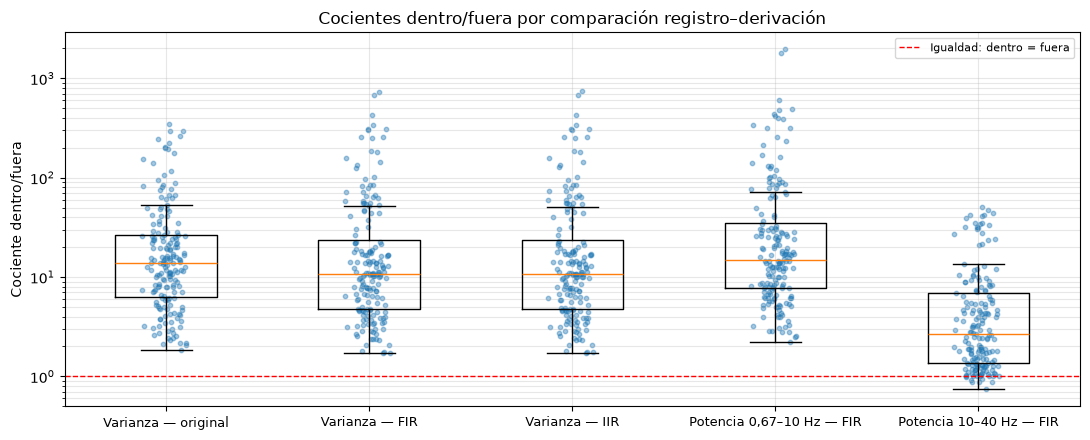

In [29]:
# Comparación pareada dentro–fuera, antes y después de filtrar
# Se repite la comparación de la sección 2 (mismo sujeto y derivación),
# ahora sobre el tramo sin bordes y para cada versión de la señal.

claves = ["Sujeto", "Derivación", "Derivaciones"]
columnas_valor = [
    "Varianza Original (mV²)", "Varianza FIR (mV²)", "Varianza IIR (mV²)",
    "Potencia 0,67–10 Hz (mV²)", "Potencia 10–40 Hz (mV²)",
]

pares_filtrado = (
    efecto_filtrado[efecto_filtrado["Dentro del resonador"]]
    [claves + ["Registro"] + columnas_valor]
    .merge(
        efecto_filtrado[~efecto_filtrado["Dentro del resonador"]]
        [claves + ["Registro"] + columnas_valor],
        on=claves, how="inner", suffixes=(" dentro", " fuera"),
        validate="many_to_one",
    )
)

cocientes = pd.DataFrame({
    "Varianza — original": "Varianza Original (mV²)",
    "Varianza — FIR": "Varianza FIR (mV²)",
    "Varianza — IIR": "Varianza IIR (mV²)",
    "Potencia 0,67–10 Hz — FIR": "Potencia 0,67–10 Hz (mV²)",
    "Potencia 10–40 Hz — FIR": "Potencia 10–40 Hz (mV²)",
}.items(), columns=["Cociente", "Columna"])

resumen_cocientes = []
valores_cocientes = {}
for _, (etiqueta, columna) in cocientes.iterrows():
    r = pares_filtrado[f"{columna} dentro"] / pares_filtrado[f"{columna} fuera"]
    valores_cocientes[etiqueta] = r
    resumen_cocientes.append({
        "Cociente dentro/fuera": etiqueta,
        "Mediana": r.median(),
        "Q25": r.quantile(0.25),
        "Q75": r.quantile(0.75),
        "Comparaciones con cociente > 1 (%)": 100 * (r > 1).mean(),
    })

print(f"Comparaciones pareadas: {len(pares_filtrado)}")
display(pd.DataFrame(resumen_cocientes).round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot(list(valores_cocientes.values()), showfliers=False)
for i, r in enumerate(valores_cocientes.values(), start=1):
    ax.scatter(np.random.default_rng(0).normal(i, 0.05, len(r)), r,
               s=10, alpha=0.4, color="tab:blue")
ax.axhline(1, color="r", ls="--", lw=1, label="Igualdad: dentro = fuera")
ax.set_xticks(range(1, len(valores_cocientes) + 1))
ax.set_xticklabels(valores_cocientes.keys(), fontsize=9)
ax.set(yscale="log", ylabel="Cociente dentro/fuera",
       title="Cocientes dentro/fuera por comparación registro–derivación")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

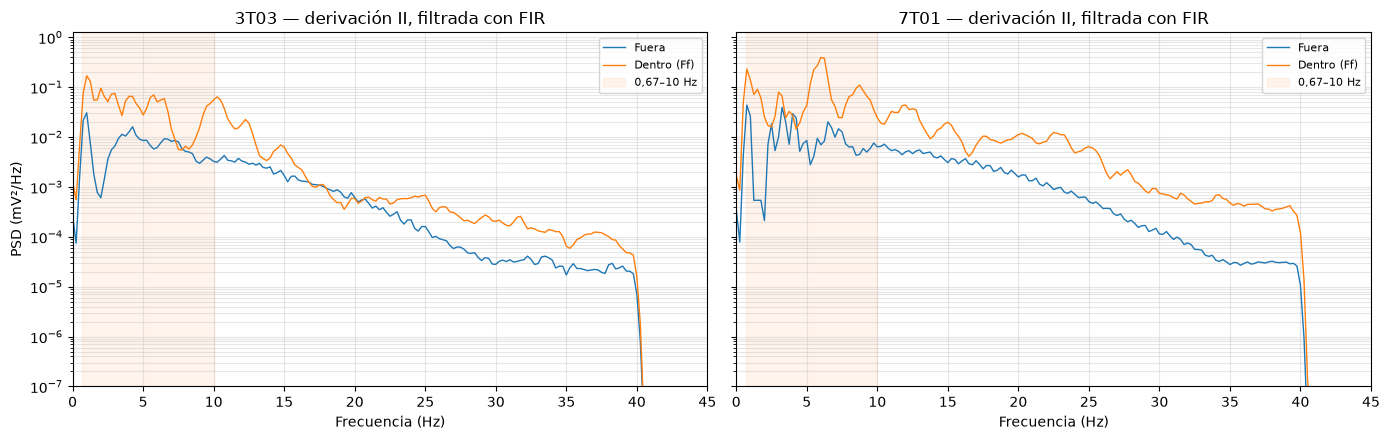

In [30]:

# PSD después de filtrar: ejemplos 3T03 y 7T01, derivación II
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

for ax, sujeto in zip(ejes, ["3T03", "7T01"]):
    for nombre, etiqueta in [(f"ECGMRI{sujeto}Out", "Fuera"),
                             (f"ECGMRI{sujeto}Ff", "Dentro (Ff)")]:
        registro = wfdb.rdrecord(str(carpeta_data / nombre))
        fs = float(registro.fs)
        borde = int(BORDE_S * fs)
        x = registro.p_signal[:, registro.sig_name.index(DERIVACION_EJEMPLO)]
        y = preprocesar(x, nombre, DERIVACION_EJEMPLO, "FIR")[borde:-borde]
        f, psd, _ = calcular_psd(y, fs)
        ax.semilogy(f, psd, lw=1, label=etiqueta)

    ax.axvspan(*BANDA_BAJA_HZ, color="tab:orange", alpha=0.08,
               label="0,67–10 Hz")
    ax.set(xlim=(0, 45), ylim=(1e-7, None),
           title=f"{sujeto} — derivación {DERIVACION_EJEMPLO}, filtrada con FIR",
           xlabel="Frecuencia (Hz)")
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8)

ejes[0].set_ylabel("PSD (mV²/Hz)")
plt.tight_layout()
plt.show()

### Conclusión del preprocesamiento convencional

**Comparación de diseños:** Sobre las 474 combinaciones registro–derivación, la diferencia entre las salidas del FIR y del Butterworth tiene una mediana de 2,4 % de la amplitud RMS, atribuible principalmente a la caída gradual del Butterworth cerca de 40 Hz. Ambos diseños son prácticamente equivalentes para estas señales. **Se adopta el FIR de Kaiser como preprocesamiento para las secciones siguientes** por su banda de paso plana, su fase lineal y su rechazo de 50 Hz sin necesidad de notch. 

**El filtrado convencional no elimina el MHD:** En las 180 comparaciones pareadas dentro–fuera (mismo sujeto y derivación), la mediana del cociente de varianzas pasa de 13,9 en la señal original a 10,8 después del FIR (10,7 con el Butterworth), y en el 100 % de las comparaciones la varianza sigue siendo mayor dentro del resonador. La reducción del cociente se explica en parte por la eliminación de la deriva, que según el reparto de potencia es mayor dentro del resonador.

**El exceso de potencia se concentra en bajas frecuencias.** En la señal filtrada, el cociente de potencia dentro/fuera tiene una mediana de 14,9 en 0,67–10 Hz y de 2,7 en 10–40 Hz. Esto es coherente con lo descrito por Krug y Rose (2011) y por Abi-Abdallah et al. (2007): la distorsión MHD se ubica en la misma banda que la onda T y el segmento ST, y un filtro que la eliminara eliminaría también esas componentes del ECG. El cociente mayor que 1 en 10–40 Hz (95 % de las comparaciones) indica que dentro del resonador también hay contenido adicional en frecuencias más altas, cuyo origen no puede determinarse con este análisis.

Como en la sección anterior, los resultados son descriptivos: provienen de adquisiciones no simultáneas y de distinta duración, y las comparaciones comparten sujetos y referencias. 

## 4. Filtro de Wiener en frecuencia

La sección 3 mostró que el filtrado convencional no elimina el MHD: después del FIR, la varianza sigue siendo mayor dentro del resonador en todas las comparaciones, y el exceso de potencia se concentra en 0,67–10 Hz, la misma banda que ocupan la onda T y el segmento ST. Un filtro definido por una banda de paso no puede separar dos componentes que comparten frecuencias. Por eso el paso siguiente es un **filtro óptimo**.

### El filtro de Wiener

El filtro de Wiener plantea el filtrado como un problema de estimación. A partir de la observación u[n] (el ECG adquirido dentro del resonador) busca la salida y[n] que mejor aproxima a la señal deseada d[n] (el ECG sin MHD), minimizando el error cuadrático medio E{e²[n]}, con e[n] = d[n] − y[n]. En el dominio del tiempo, los coeficientes óptimos de un filtro FIR resultan de la ecuación de Wiener–Hopf, R_uu · b = r_ud.

Si la observación es la suma de la señal deseada y una interferencia v[n] no correlacionada con ella (u = d + v), la solución sin restricción de causalidad puede escribirse en frecuencia:

$$H(f) = \frac{S_{dd}(f)}{S_{dd}(f) + S_{vv}(f)}$$

En cada frecuencia, el filtro deja pasar la proporción de la potencia que corresponde a la señal: H ≈ 1 donde domina el ECG y H ≈ 0 donde domina la interferencia.

### Por qué en frecuencia

Krug et al. (2012) aplicaron Wiener a este mismo problema en el dominio del tiempo: resolvieron la ecuación de Wiener–Hopf con latidos adquiridos dentro del resonador, alineados en el pico R, usando como señal deseada el latido promedio del mismo sujeto fuera del resonador. Ese planteo requiere conocer la posición de cada pico R. En este punto del trabajo todavía no se detectaron los QRS, y el objetivo es justamente reducir el MHD **antes** de detectarlos. La versión en frecuencia solo necesita las densidades espectrales de potencia, que pueden estimarse sin ubicar los latidos.

### Estimación de las densidades espectrales

No se dispone del ECG sin MHD de la misma adquisición. Se usa como aproximación el registro del mismo sujeto y la misma derivación fuera del resonador:

- **S_dd(f)** ≈ PSD de la referencia externa;
- **S_vv(f)** ≈ max(S_uu(f) − S_dd(f), 0): la potencia que el registro dentro del resonador tiene en exceso respecto de la referencia.

Con estas estimaciones, H(f) = S_dd / max(S_uu, S_dd), que toma valores entre 0 y 1. Las PSD se calculan con la configuración de Welch de la sección 2, sobre las señales preprocesadas con el FIR de la sección 3 y sin los 2,5 s de cada borde.

El planteo se apoya en supuestos que hay que tener presentes al interpretar los resultados:

- que el ECG del sujeto dentro del resonador tiene el mismo espectro que fuera, aunque las adquisiciones no son simultáneas y pueden diferir en la frecuencia cardíaca y la posición;
- que el MHD no está correlacionado con el ECG, aunque lo genera el flujo de sangre de cada latido y, por lo tanto, está sincronizado con el ciclo cardíaco;
- que ambas componentes son estacionarias durante todo el registro.

### Alcance: registros con referencia externa

El método necesita, para cada registro dentro del resonador, un registro del mismo sujeto fuera del resonador. Solo 9 sujetos tienen ese registro. Los demás registros dentro del resonador (3T05–3T09, de 12 derivaciones, y 3T10–3T23, del monitor de 3 derivaciones) no tienen referencia y no pueden procesarse con este método.

**Decisión: a partir de esta sección se trabaja solo con los 9 sujetos que tienen registro dentro y fuera del resonador.** Así, este método y los que se evalúen después se comparan sobre los mismos registros, y las diferencias no se deben a un cambio en el conjunto de datos. Como contrapartida, las conclusiones de las secciones siguientes se basan en pocos sujetos por campo (1 en 1 T, 4 en 3 T y 4 en 7 T) y no son generalizables.

In [31]:
# Registros con referencia externa del mismo sujeto
registros_fuera = registros_validos[~registros_validos["Dentro del resonador"]]
registros_dentro = registros_validos[registros_validos["Dentro del resonador"]]

pares_wiener = registros_dentro.merge(
    registros_fuera[["Sujeto", "Registro", "FC media (lpm)", "Duración (s)"]],
    on="Sujeto", suffixes=("", " fuera"), validate="many_to_one",
)[["Sujeto", "Campo (T)", "Registro", "Registro fuera",
   "FC media (lpm)", "FC media (lpm) fuera", "Duración (s)", "Duración (s) fuera"]]

print(f"Sujetos con registro fuera del resonador: {pares_wiener['Sujeto'].nunique()}")
print(f"Registros dentro del resonador con referencia externa: {len(pares_wiener)}")
print(f"Registros dentro del resonador sin referencia externa: "
      f"{len(registros_dentro) - len(pares_wiener)}")
display(pares_wiener.round(1))

Sujetos con registro fuera del resonador: 9
Registros dentro del resonador con referencia externa: 15
Registros dentro del resonador sin referencia externa: 26


,Sujeto,Campo (T),Registro,Registro fuera,FC media (lpm),FC media (lpm) fuera,Duración (s),Duración (s) fuera
0,1T01,1,ECGMRI1T01Pro,ECGMRI1T01Out,87.6,90.1,39.1,29.3
1,1T01,1,ECGMRI1T01Sup,ECGMRI1T01Out,86.5,90.1,26.4,29.3
2,3T01,3,ECGMRI3T01Ff,ECGMRI3T01Out,66.4,65.7,326.2,156.2
3,3T01,3,ECGMRI3T01Hf,ECGMRI3T01Out,65.5,65.7,366.2,156.2
4,3T02,3,ECGMRI3T02Ff,ECGMRI3T02Out,66.4,66.4,24.4,24.4
5,3T03,3,ECGMRI3T03Ff,ECGMRI3T03Out,57.1,56.2,195.3,127.0
6,3T04,3,ECGMRI3T04Ff,ECGMRI3T04Out,87.0,89.6,117.2,117.2
7,7T01,7,ECGMRI7T01Ff,ECGMRI7T01Out,46.5,49.5,212.9,186.5
8,7T01,7,ECGMRI7T01Hf,ECGMRI7T01Out,47.4,49.5,286.1,186.5
9,7T02,7,ECGMRI7T02Ff,ECGMRI7T02Out,62.5,72.5,273.4,293.0


In [32]:
# Filtro de Wiener en frecuencia
def psd_sin_bordes(x, fs):
    """PSD de Welch (configuración de la sección 2) sin los bordes del FIR."""
    borde = int(BORDE_S * fs)
    f, psd, _ = calcular_psd(x[borde:-borde], fs)
    return f, psd


def ganancia_wiener(psd_dentro, psd_fuera):
    """H(f) = S_dd / (S_dd + S_vv), con S_dd ≈ PSD fuera y S_vv ≈ max(S_uu − S_dd, 0).

    Como S_dd + max(S_uu − S_dd, 0) = max(S_uu, S_dd), resulta
    H(f) = S_dd / max(S_uu, S_dd), que vale entre 0 y 1.
    """
    return psd_fuera / np.maximum(psd_dentro, psd_fuera)


def aplicar_wiener(x, fs, f_h, h):
    """Aplica H(f) multiplicando el espectro de toda la señal.

    H es real y no negativa, por lo que el filtro no modifica la fase
    (fase cero). H se interpola a la grilla de frecuencias de la FFT.
    """
    espectro = np.fft.rfft(x)
    f_fft = np.fft.rfftfreq(len(x), d=1 / fs)
    return np.fft.irfft(espectro * np.interp(f_fft, f_h, h), n=len(x))


def senal_fir(nombre, derivacion):
    """Lee una derivación y la preprocesa con el FIR de la sección 3."""
    registro = wfdb.rdrecord(str(carpeta_data / nombre))
    x = registro.p_signal[:, registro.sig_name.index(derivacion)]
    return float(registro.fs), preprocesar(x, nombre, derivacion, "FIR")


def wiener_derivacion(nombre_dentro, nombre_fuera, derivacion):
    """Diseña y aplica el Wiener para una derivación de un registro dentro del resonador.

    Devuelve un diccionario con la señal de entrada (FIR), la salida de Wiener,
    la referencia externa (FIR) y las PSD y la ganancia usadas.
    """
    fs, x_dentro = senal_fir(nombre_dentro, derivacion)
    _, x_fuera = senal_fir(nombre_fuera, derivacion)

    f, psd_dentro = psd_sin_bordes(x_dentro, fs)
    _, psd_fuera = psd_sin_bordes(x_fuera, fs)
    h = ganancia_wiener(psd_dentro, psd_fuera)

    return {
        "fs": fs, "f": f, "H": h,
        "PSD dentro": psd_dentro, "PSD fuera": psd_fuera,
        "Entrada": x_dentro,
        "Wiener": aplicar_wiener(x_dentro, fs, f, h),
        "Fuera": x_fuera,
    }

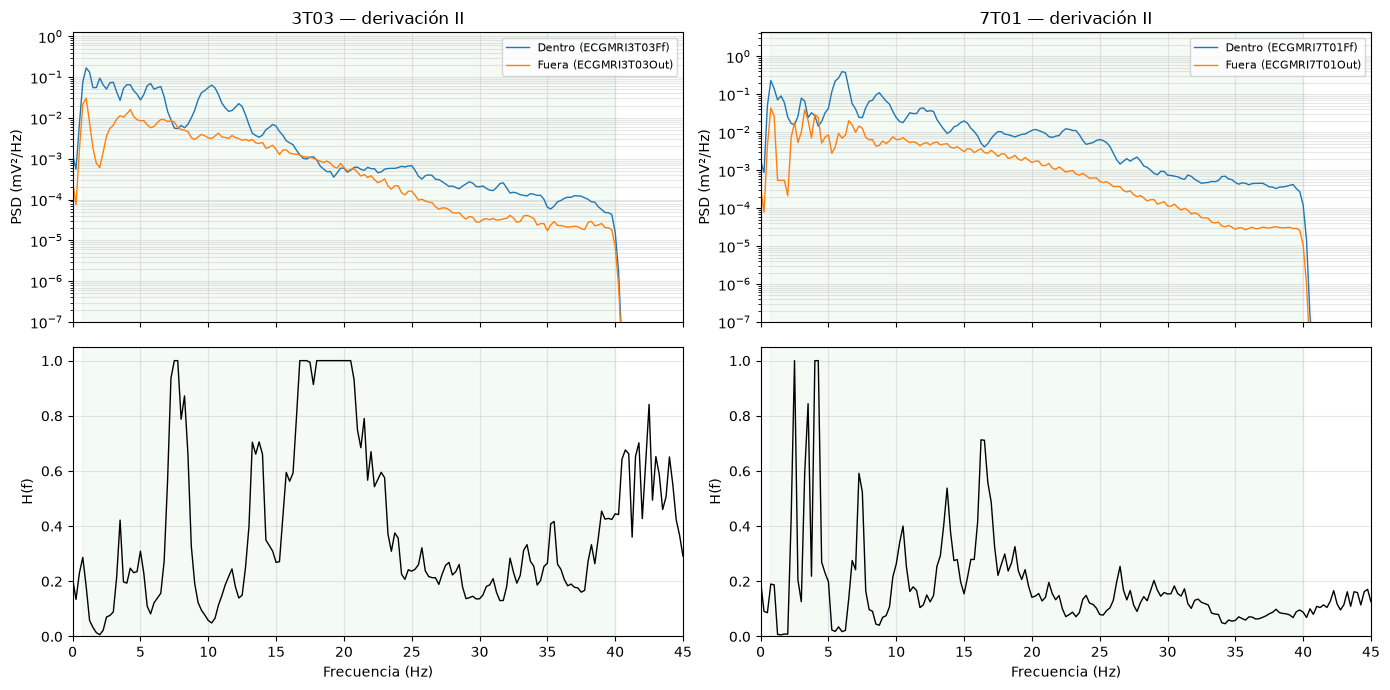

,Registro,"H media 0,67–10 Hz",H media 10–40 Hz
0,ECGMRI3T03Ff,0.29,0.40
1,ECGMRI7T01Ff,0.25,0.17


In [33]:
# Ejemplos: PSD dentro y fuera, y ganancia de Wiener (derivación II)
ejemplos_wiener = [("ECGMRI3T03Ff", "ECGMRI3T03Out"), ("ECGMRI7T01Ff", "ECGMRI7T01Out")]
BANDAS_H = {"0,67–10 Hz": (0.67, 10.0), "10–40 Hz": (10.0, 40.0)}

fig, ejes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
filas_h_ejemplo = []

for col, (nombre_dentro, nombre_fuera) in enumerate(ejemplos_wiener):
    w = wiener_derivacion(nombre_dentro, nombre_fuera, "II")

    ax = ejes[0, col]
    ax.semilogy(w["f"], w["PSD dentro"], lw=1, label=f"Dentro ({nombre_dentro})")
    ax.semilogy(w["f"], w["PSD fuera"], lw=1, label=f"Fuera ({nombre_fuera})")
    ax.set(title=f"{nombre_dentro[6:10]} — derivación II", ylabel="PSD (mV²/Hz)",
           ylim=(1e-7, None))
    ax.legend(fontsize=8)

    ax = ejes[1, col]
    ax.plot(w["f"], w["H"], color="k", lw=1)
    ax.set(ylabel="H(f)", xlabel="Frecuencia (Hz)", ylim=(0, 1.05))

    fila = {"Registro": nombre_dentro}
    for banda, (f1, f2) in BANDAS_H.items():
        fila[f"H media {banda}"] = w["H"][(w["f"] >= f1) & (w["f"] < f2)].mean()
    filas_h_ejemplo.append(fila)

for ax in ejes.flat:
    ax.set_xlim(0, 45)
    ax.axvspan(*BANDA_PASO_HZ, color="tab:green", alpha=0.05)
    ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

display(pd.DataFrame(filas_h_ejemplo).round(2))

En los dos ejemplos, la curva azul (dentro del resonador) está por encima de la naranja (fuera) en casi todas las frecuencias. Es decir, dentro del resonador hay más potencia en casi toda la banda, y el filtro interpreta ese exceso como interferencia.

Por eso la ganancia H(f) queda casi siempre muy por debajo de 1. H(f) indica qué fracción de la amplitud deja pasar el filtro en cada frecuencia: H = 1 deja pasar todo y H = 0,25 deja pasar solo un cuarto.

- **Entre 0,67 y 10 Hz**, donde están la onda T y el ST, la ganancia media es 0,29 en 3T03 y 0,25 en 7T01: el filtro deja pasar menos de un tercio de la amplitud en los dos casos.
- **Entre 10 y 40 Hz** hay una diferencia entre campos: en 3T03 la ganancia media es 0,40, pero en 7T01 baja a 0,17. A 7 T el exceso de potencia no se limita a las frecuencias bajas y aparece en toda la banda.

Como el ECG se repite en cada latido, su espectro no es una curva suave: tiene picos en múltiplos de la frecuencia cardíaca. Eso hace que la H(f) suba y baje tanto entre frecuencias cercanas. Por ejemplo, con 60 lpm (1 latido por segundo) hay picos en 1, 2, 3 Hz, etc. Dentro y fuera del resonador la frecuencia cardíaca no es la misma (en 7T01, 46,5 lpm dentro y 49,5 lpm fuera), así que los picos de una curva y de la otra caen en lugares un poco distintos. En las frecuencias donde la curva de afuera tiene un pico y la de adentro no, H sube de golpe; en las frecuencias donde pasa lo contrario, H baja de golpe.

Esto muestra que el primer supuesto del método (que el ECG tiene el mismo espectro dentro y fuera del resonador) no se cumple del todo: alcanza con que cambie la frecuencia cardíaca para que los espectros no coincidan.

Para ver si lo observado en estos dos ejemplos se repite en el resto, se aplica el filtro a todas las derivaciones de los 15 registros con referencia externa.

In [34]:
# Wiener en todos los registros con referencia externa
# Para cada derivación se resume la ganancia por bandas y se compara la
# varianza de la señal antes y después de Wiener con la de la referencia
# externa. Todas las medidas excluyen los bordes del FIR.

filas_wiener = []
for _, par in pares_wiener.iterrows():
    nombre_dentro, nombre_fuera = par["Registro"], par["Registro fuera"]
    derivaciones = wfdb.rdheader(str(carpeta_data / nombre_dentro)).sig_name

    for derivacion in derivaciones:
        w = wiener_derivacion(nombre_dentro, nombre_fuera, derivacion)
        borde = int(BORDE_S * w["fs"])
        varianza = {k: np.var(w[k][borde:-borde]) for k in ["Entrada", "Wiener", "Fuera"]}

        fila = {
            "Registro": nombre_dentro,
            "Campo (T)": par["Campo (T)"],
            "Derivación": derivacion,
            "Varianza entrada / fuera": varianza["Entrada"] / varianza["Fuera"],
            "Varianza Wiener / fuera": varianza["Wiener"] / varianza["Fuera"],
        }
        for banda, (f1, f2) in BANDAS_H.items():
            fila[f"H media {banda}"] = w["H"][(w["f"] >= f1) & (w["f"] < f2)].mean()
        filas_wiener.append(fila)

resultados_wiener = pd.DataFrame(filas_wiener)
print(f"Combinaciones registro–derivación: {len(resultados_wiener)}")
display(resultados_wiener.groupby("Campo (T)")
        .median(numeric_only=True).round(2)
        .assign(**{"n": resultados_wiener.groupby("Campo (T)").size()}))
print("Todas las combinaciones — mediana [Q25; Q75]:")
display(resultados_wiener.drop(columns="Campo (T)")
        .describe(percentiles=[0.25, 0.5, 0.75])
        .loc[["25%", "50%", "75%"]].round(2))

Combinaciones registro–derivación: 180


,Varianza entrada / fuera,Varianza Wiener / fuera,"H media 0,67–10 Hz",H media 10–40 Hz,n
Campo (T),,,,,
1,5.14,0.50,0.37,0.70,24
3,5.16,0.40,0.28,0.70,60
7,15.37,0.21,0.14,0.34,96


Todas las combinaciones — mediana [Q25; Q75]:


,Varianza entrada / fuera,Varianza Wiener / fuera,"H media 0,67–10 Hz",H media 10–40 Hz
25%,4.78,0.16,0.09,0.26
50%,10.77,0.30,0.22,0.56
75%,23.66,0.44,0.35,0.71


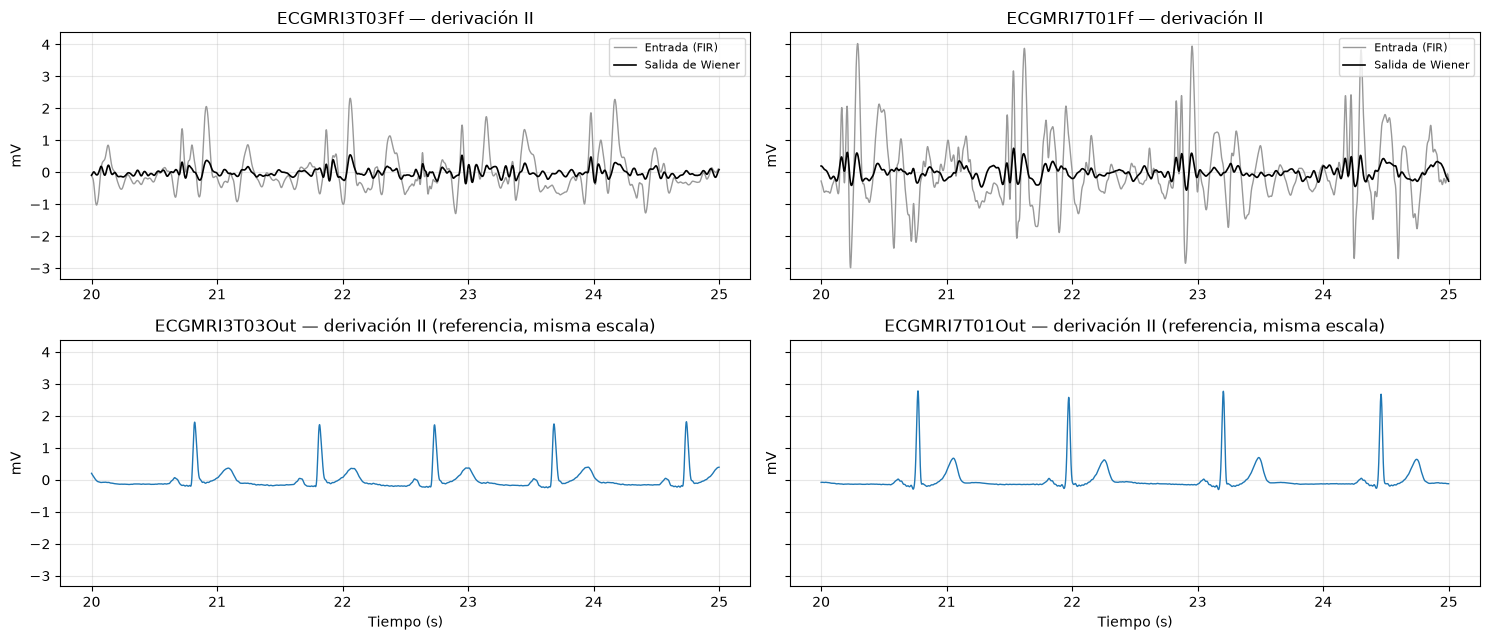

In [35]:

# Ejemplos en el tiempo: entrada (FIR), salida de Wiener y referencia externa
INICIO_W_S, DURACION_W_S = 20.0, 5.0

fig, ejes = plt.subplots(2, 2, figsize=(15, 6.5), sharey=True)   # misma escala en los 4 paneles

for col, (nombre_dentro, nombre_fuera) in enumerate(ejemplos_wiener):
    w = wiener_derivacion(nombre_dentro, nombre_fuera, "II")
    i0 = int(INICIO_W_S * w["fs"])
    i1 = int((INICIO_W_S + DURACION_W_S) * w["fs"])
    t = np.arange(i0, i1) / w["fs"]

    ax = ejes[0, col]
    ax.plot(t, w["Entrada"][i0:i1], color="0.6", lw=1, label="Entrada (FIR)")
    ax.plot(t, w["Wiener"][i0:i1], color="k", lw=1.2, label="Salida de Wiener")
    ax.set(title=f"{nombre_dentro} — derivación II", ylabel="mV")
    ax.legend(fontsize=8, loc="upper right")

    ax = ejes[1, col]
    ax.plot(t, w["Fuera"][i0:i1], color="tab:blue", lw=1)
    ax.set(title=f"{nombre_fuera} — derivación II (referencia, misma escala)",
           ylabel="mV", xlabel="Tiempo (s)")

for ax in ejes.flat:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Resultado del filtro de Wiener en frecuencia

**El filtro atenúa más de lo necesario.** Antes del filtro, la señal dentro del resonador tiene, en mediana, 10,8 veces la varianza de la referencia externa: le sobra potencia por el MHD. Lo esperable de un buen filtro sería acercar ese cociente a 1, es decir, dejar la señal con una potencia parecida a la de afuera. Después de Wiener, en cambio, el cociente queda en 0,30: la salida tiene menos de un tercio de la potencia de la referencia. El filtro no solo sacó el exceso, sino que también se llevó parte del ECG.

Esto pasa porque el filtro busca la salida con el menor error cuadrático medio posible. Cuando en una frecuencia la interferencia es mucho mayor que la señal, la opción de menor error es atenuar esa frecuencia casi por completo, aunque eso también elimine la parte del ECG que había en ella. Como dentro del resonador sobra potencia en casi todas las frecuencias, el filtro atenúa casi todo.

**El efecto aumenta con el campo magnético.** La ganancia media entre 0,67 y 10 Hz es 0,37 en 1 T, 0,28 en 3 T y 0,14 en 7 T. Entre 10 y 40 Hz es 0,70 en 1 T y 3 T y baja a 0,34 en 7 T. A mayor campo, mayor MHD, y el filtro atenúa más.

**En la figura de los ejemplos** se ve el mismo resultado sobre la señal: la salida de Wiener es mucho más chica que la referencia de afuera, en la misma escala, y ya no tiene la forma P-QRS-T. Se siguen viendo picos que se repiten con cada latido, pero no queda claro cuáles corresponden a los QRS.

Esto coincide con lo que reportaron Krug et al. (2012): Wiener tiene una utilidad limitada para este problema. Acá se observa en una versión que no necesita conocer la ubicación de los latidos.

Mirando la figura no se puede saber si la salida de Wiener facilita o dificulta la detección del QRS respecto de la señal con FIR. **Por eso, en la sección siguiente se aplica el detector a las dos versiones de la señal y se comparan los resultados con la referencia.**

## 5. Detección de complejos QRS

Esta sección busca determinar si la salida de Wiener facilita o dificulta la detección de los QRS respecto de la señal con FIR. Para eso se aplica un detector a las dos versiones y se comparan los resultados.

La detección tiene además un segundo objetivo. Krug et al. (2012) aplicaron Wiener en el dominio del tiempo, latido a latido, con los latidos alineados en el pico R. Para usar ese tipo de métodos primero hay que ubicar cada pico R. **Los R de la versión que detecte mejor se usarán en la sección siguiente.**

### Uso de las anotaciones de referencia

El dataset incluye la posición de cada pico R marcada a mano (archivos `.qrs`). En la práctica clínica esa información no existe, por lo que **las anotaciones se usan solo para evaluar** (comparar las detecciones contra ellas) **y nunca como entrada de ningún método**. Si se usaran para procesar la señal, los resultados quedarían inflados.

### Algoritmo de Pan–Tompkins

Se usa el detector de Pan y Tompkins, que transforma el ECG en una señal en la que cada QRS produce un pulso fácil de detectar:

1. **Pasabanda de 5–15 Hz**, la banda donde se concentra la energía del QRS.
2. **Derivada de 5 puntos**, que resalta las pendientes pronunciadas del QRS.
3. **Elevación al cuadrado**, que hace positivos todos los valores y acentúa las pendientes grandes.
4. **Integración con ventana móvil de 150 ms**, aproximadamente la duración de un QRS, que convierte cada complejo en un único pulso.
5. **Umbrales adaptativos.** Cada pico de la señal integrada se clasifica como QRS o como ruido según un umbral que se actualiza con los niveles estimados de la señal y del ruido. Se aplican también las reglas del algoritmo original:
   - un período refractario de 200 ms entre detecciones;
   - la discriminación de ondas T: un pico a menos de 360 ms del QRS anterior, con menos de la mitad de su pendiente, se descarta;
   - la búsqueda hacia atrás: si pasan más de 1,66 veces el intervalo RR promedio sin detecciones, se acepta el mayor pico intermedio que supere la mitad del umbral.

### Adaptaciones respecto del algoritmo original

Los valores de los pasos anteriores (banda de 5–15 Hz, ventana de 150 ms, período refractario de 200 ms, límite de 360 ms para las ondas T, factor de 1,66 para la búsqueda hacia atrás, actualización de los niveles con pesos 0,125 y 0,875, umbral a un cuarto entre el nivel de ruido y el de señal) son los del algoritmo original. La implementación difiere en los siguientes puntos:

1. **Pasabanda:** Los filtros del original tienen coeficientes calculados para una frecuencia de muestreo de 200 Hz; aplicados a estos registros, muestreados a 1024 Hz, darían otra banda. Se diseña un Butterworth de orden 2 en la misma banda de 5–15 Hz, como propone el esquema del ejercicio de la materia. De esta forma se conserva la banda del algoritmo sin remuestrear las señales.
2. **Fase cero:** El original es causal, pensado para tiempo real, e introduce un retardo entre la señal y las detecciones. En este trabajo los picos R detectados se usan después para alinear latidos, por lo que se necesitan en su posición real. Como el análisis es fuera de línea, el pasabanda, la derivada y la integración se aplican centrados, sin retardo, con el mismo criterio de fase cero de la sección 3. Como contrapartida, esta implementación no puede usarse en tiempo real tal como está.
3. **Umbrales:** El original usa dos juegos de umbrales, uno sobre la señal integrada y otro sobre la señal filtrada, para descartar picos de ruido que superan solo uno de ellos. Aquí se usa solo el de la señal integrada, para simplificar la implementación. Se espera que el efecto sea menor en este problema, porque la principal fuente de detecciones falsas es la deformación MHD, que tiene pendientes pronunciadas y aparece en las dos señales. 
4. **Intervalo RR promedio:** El original lleva dos promedios: el de los últimos 8 intervalos y el de los intervalos dentro de un rango considerado regular, pensado para ritmos irregulares. Aquí se usa solo el primero, para simplificar la implementación. Los registros son de voluntarios sanos con ritmo sinusal, donde la diferencia entre ambos promedios debería ser pequeña. 
5. **Inicialización:** El original indica una fase de aprendizaje de 2 s, pero no fija los valores iniciales de los niveles, por lo que toda implementación necesita elegirlos. Aquí el nivel de señal se inicializa en 0,25 veces el máximo y el nivel de ruido en 0,5 veces la media de la señal integrada en esos 2 s. Son valores arbitrarios; como los niveles se actualizan con cada pico, su influencia se limita a los primeros latidos.
6. **Ubicación del pico R:** El algoritmo indica dónde hay un QRS, pero no la posición exacta del pico R, que hace falta para alinear latidos. Se busca el máximo del valor absoluto de la señal filtrada en 5–15 Hz dentro de ±75 ms del pulso detectado, la mitad de la ventana de integración. Se usa el valor absoluto para que el detector funcione también en derivaciones con QRS negativo, como aVR.

Los parámetros no se ajustaron para mejorar la detección dentro del resonador: el objetivo es evaluar cómo cambia el desempeño de un detector estándar según el preprocesamiento de la señal. Si también se modificara el detector, no podría saberse si una mejora se debe al preprocesamiento o al ajuste.

El detector se aplica a todas las derivaciones de los 24 registros de los 9 sujetos con referencia externa. Dentro del resonador se usan las dos versiones de la señal (FIR y Wiener); fuera, solo la versión FIR, porque Wiener se define para los registros dentro del resonador. Los registros de afuera muestran cómo funciona el detector sin MHD. Como en las secciones anteriores, se excluyen los primeros y últimos 2,5 s de cada registro.

In [36]:
# Algoritmo de Pan–Tompkins
PT_BANDA_HZ = (5.0, 15.0)
PT_VENTANA_INTEGRACION_S = 0.150
PT_REFRACTARIO_S = 0.200
PT_LIMITE_ONDA_T_S = 0.360
PT_FACTOR_BUSQUEDA_ATRAS = 1.66
PT_VENTANA_PICO_R_S = 0.075


def pan_tompkins(x, fs):
    """Detecta complejos QRS. Devuelve (posiciones de los picos R, etapas intermedias)."""
    x = np.asarray(x, dtype=float)

    # 1. Pasabanda 5–15 Hz con fase cero
    sos_pt = signal.butter(2, PT_BANDA_HZ, btype="bandpass", fs=fs, output="sos")
    x_banda = signal.sosfiltfilt(sos_pt, x)

    # 2. Derivada de 5 puntos centrada: y(n) = fs/8 · [x(n+2) + 2x(n+1) − 2x(n−1) − x(n−2)]
    x_derivada = np.convolve(x_banda, np.array([1, 2, 0, -2, -1]) * fs / 8, mode="same")

    # 3. Cuadrado
    x_cuadrado = x_derivada ** 2

    # 4. Integración con ventana móvil centrada
    n_ventana = int(round(PT_VENTANA_INTEGRACION_S * fs))
    x_integrada = np.convolve(x_cuadrado, np.ones(n_ventana) / n_ventana, mode="same")

    # 5. Picos candidatos, separados al menos por el período refractario
    candidatos, _ = signal.find_peaks(x_integrada, distance=int(PT_REFRACTARIO_S * fs))

    # Inicialización de los niveles con los primeros 2 s
    inicio = x_integrada[: int(2 * fs)]
    spki = 0.25 * inicio.max() 
    npki = 0.5 * inicio.mean()    
    umbral = npki + 0.25 * (spki - npki)

    def pendiente_maxima(p):
        w = int(PT_VENTANA_PICO_R_S * fs)
        return np.max(np.abs(x_derivada[max(p - w, 0): p + w]))

    qrs = []
    for p in candidatos:
        es_qrs = x_integrada[p] > umbral
        # Discriminación de ondas T
        if es_qrs and qrs and (p - qrs[-1]) < PT_LIMITE_ONDA_T_S * fs:
            if pendiente_maxima(p) < 0.5 * pendiente_maxima(qrs[-1]):
                es_qrs = False

        if es_qrs:
            qrs.append(p)
            spki = 0.125 * x_integrada[p] + 0.875 * spki
        else:
            npki = 0.125 * x_integrada[p] + 0.875 * npki

        # Búsqueda hacia atrás de latidos perdidos
        if len(qrs) >= 2:
            rr_promedio = np.mean(np.diff(qrs[-9:]))
            if p - qrs[-1] > PT_FACTOR_BUSQUEDA_ATRAS * rr_promedio:
                perdidos = [q for q in candidatos
                            if qrs[-1] + PT_REFRACTARIO_S * fs < q < p
                            and x_integrada[q] > 0.5 * umbral]
                if perdidos:
                    q = max(perdidos, key=lambda q: x_integrada[q])
                    qrs.append(q)
                    qrs.sort()
                    spki = 0.25 * x_integrada[q] + 0.75 * spki

        umbral = npki + 0.25 * (spki - npki)

    qrs = np.array(sorted(set(qrs)), dtype=int)

    # 6. Ubicación del pico R: máximo de |señal en 5–15 Hz| alrededor de cada detección
    w = int(PT_VENTANA_PICO_R_S * fs)
    picos_r = np.array(
        [a + np.argmax(np.abs(x_banda[a:b]))
         for a, b in ((max(p - w, 0), min(p + w, len(x))) for p in qrs)],
        dtype=int,
    )

    etapas = {"Pasabanda 5–15 Hz": x_banda, "Integrada": x_integrada}
    return picos_r, etapas

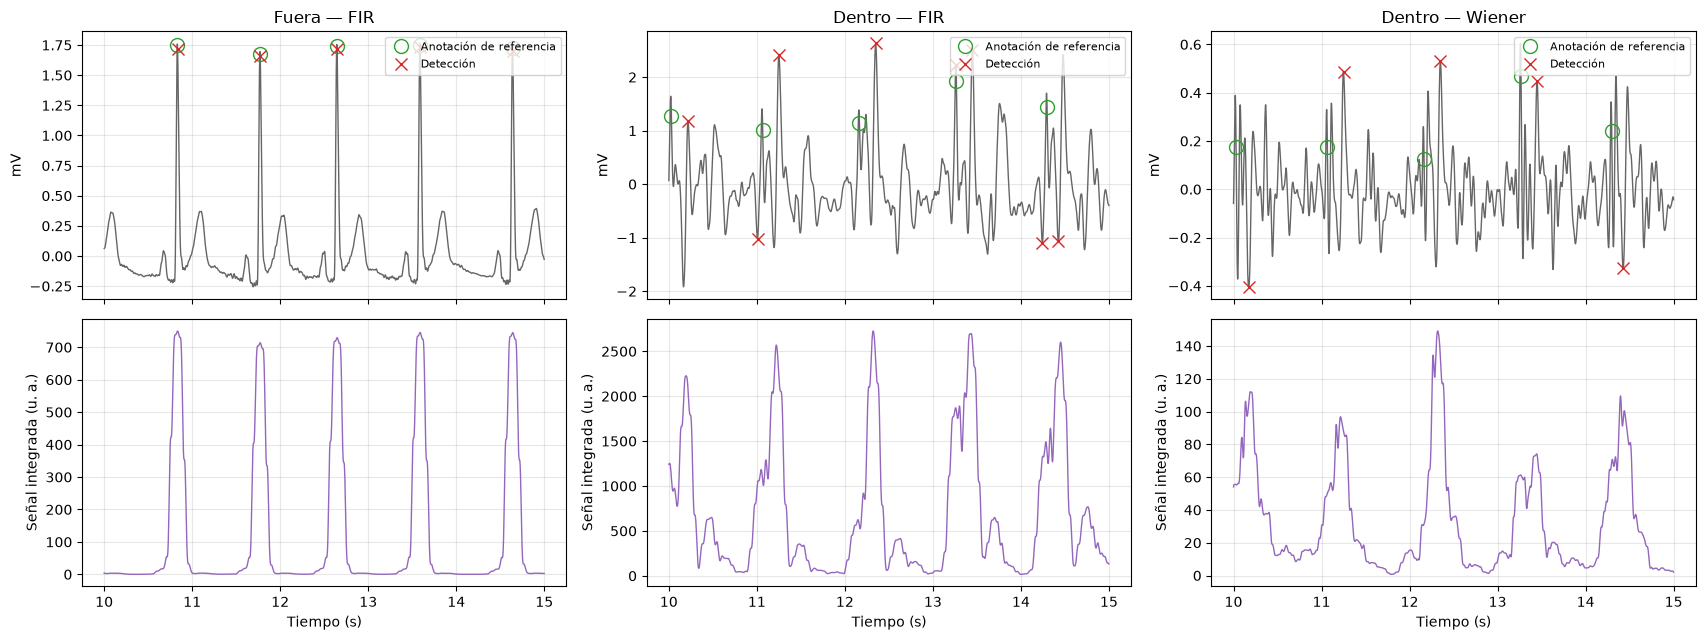

In [37]:
# Ejemplo de las etapas de Pan–Tompkins (3T03, derivación II)
INICIO_PT_S, DURACION_PT_S = 10.0, 5.0

w_ejemplo = wiener_derivacion("ECGMRI3T03Ff", "ECGMRI3T03Out", "II")
versiones_ejemplo = [
    ("ECGMRI3T03Out", "Fuera — FIR", w_ejemplo["Fuera"]),
    ("ECGMRI3T03Ff", "Dentro — FIR", w_ejemplo["Entrada"]),
    ("ECGMRI3T03Ff", "Dentro — Wiener", w_ejemplo["Wiener"]),
]
fs = w_ejemplo["fs"]
i0, i1 = int(INICIO_PT_S * fs), int((INICIO_PT_S + DURACION_PT_S) * fs)
t = np.arange(i0, i1) / fs

fig, ejes = plt.subplots(2, 3, figsize=(17, 6.5), sharex=True)

for col, (nombre, titulo, y) in enumerate(versiones_ejemplo):
    anotaciones = wfdb.rdann(str(carpeta_data / nombre), "qrs").sample
    picos_r, etapas = pan_tompkins(y, fs)
    ref = anotaciones[(anotaciones >= i0) & (anotaciones < i1)]
    det = picos_r[(picos_r >= i0) & (picos_r < i1)]

    ax = ejes[0, col]
    ax.plot(t, y[i0:i1], color="0.4", lw=1)
    ax.plot(ref / fs, y[ref], "o", mfc="none", mec="tab:green", ms=10,
            label="Anotación de referencia")
    ax.plot(det / fs, y[det], "x", color="tab:red", ms=8, label="Detección")
    ax.set(title=titulo, ylabel="mV")
    ax.legend(fontsize=8, loc="upper right")

    ax = ejes[1, col]
    ax.plot(t, etapas["Integrada"][i0:i1], color="tab:purple", lw=1)
    ax.set(ylabel="Señal integrada (u. a.)", xlabel="Tiempo (s)")

for ax in ejes.flat:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Fuera del resonador (izquierda), cada QRS produce un único pulso en la señal integrada y cada detección (cruz roja) coincide con una anotación (círculo verde).

Dentro del resonador, con FIR (centro), la deformación MHD que sigue a cada QRS también tiene pendientes pronunciadas y produce pulsos de tamaño parecido en la señal integrada. El detector marca algunos de esos pulsos como QRS: hay cruces sin círculo al lado (detecciones falsas) y círculos sin cruz (latidos que no detectó).

Con Wiener (derecha) la señal es mucho más chica, como se vio en la sección 4, y también tiene detecciones mal ubicadas. En este tramo no se ve una diferencia clara entre las dos versiones. Para compararlas hay que contar los aciertos y los errores en todos los registros.

In [38]:
# Detección en los registros de los 9 sujetos con referencia externa
# Dentro del resonador se detecta sobre la señal con FIR y sobre la salida de Wiener.
# Fuera del resonador solo hay versión FIR (Wiener necesita un registro dentro).
# Detecciones y anotaciones se guardan sin los bordes del FIR.

detecciones = {}   # (registro, derivación, versión) -> picos R detectados
referencias = {}   # registro -> anotaciones de referencia


def sin_bordes(muestras, n_muestras, fs):
    borde = int(BORDE_S * fs)
    return muestras[(muestras >= borde) & (muestras < n_muestras - borde)]


registros_deteccion = (
    pares_wiener[["Registro", "Registro fuera"]].values.tolist()
    + [[r, None] for r in pares_wiener["Registro fuera"].unique()]
)

for nombre, nombre_fuera in registros_deteccion:
    encabezado = wfdb.rdheader(str(carpeta_data / nombre))
    fs, n_muestras = float(encabezado.fs), encabezado.sig_len
    referencias[nombre] = sin_bordes(
        wfdb.rdann(str(carpeta_data / nombre), "qrs").sample, n_muestras, fs
    )

    for derivacion in encabezado.sig_name:
        if nombre_fuera is None:                       # registro fuera del resonador
            versiones = {"FIR": senal_fir(nombre, derivacion)[1]}
        else:                                          # registro dentro del resonador
            w = wiener_derivacion(nombre, nombre_fuera, derivacion)
            versiones = {"FIR": w["Entrada"], "Wiener": w["Wiener"]}

        for version, y in versiones.items():
            picos_r, _ = pan_tompkins(y, fs)
            detecciones[(nombre, derivacion, version)] = sin_bordes(picos_r, n_muestras, fs)

print(f"Registros: {len(referencias)} "
      f"({len(pares_wiener)} dentro y {pares_wiener['Registro fuera'].nunique()} fuera)")
print(f"Señales procesadas: {len(detecciones)}")
print(f"Latidos de referencia (sin bordes): {sum(len(r) for r in referencias.values())}")

Registros: 24 (15 dentro y 9 fuera)
Señales procesadas: 468
Latidos de referencia (sin bordes): 4570


### Tolerancia para comparar con la referencia

Para decidir si una detección corresponde a un latido anotado hace falta una tolerancia: la distancia máxima entre la detección y la anotación para considerarla un acierto. Para elegirla, para cada latido de referencia se mide la distancia a la detección más cercana, con signo (positiva si la detección está después de la anotación). Solo se consideran las detecciones a menos de 150 ms, porque a mayor distancia ya no pueden corresponder al mismo QRS.

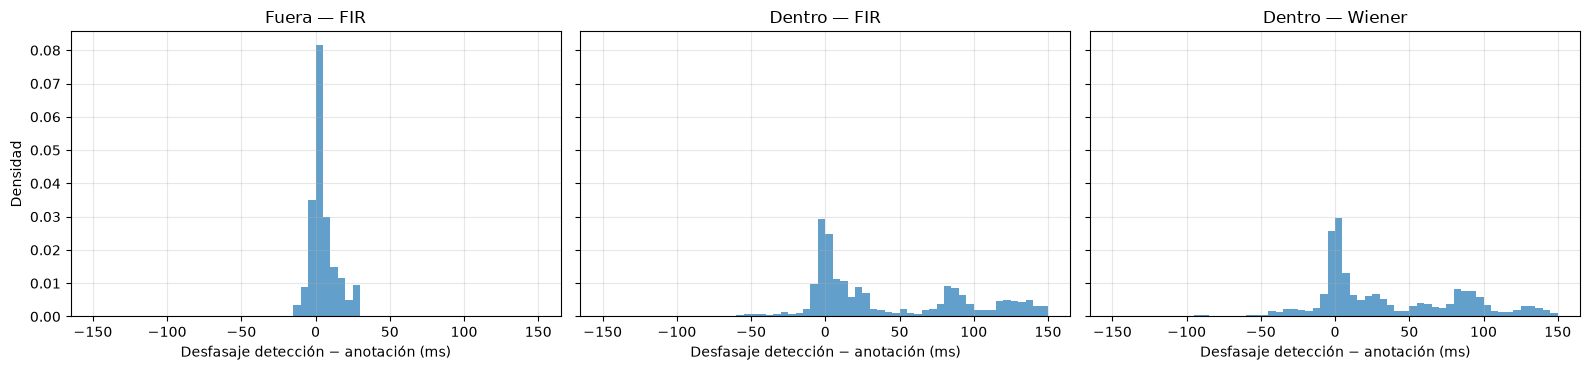

Porcentaje de desfasajes dentro de cada tolerancia:


,Fuera — FIR,Dentro — FIR,Dentro — Wiener
± 20 ms,92.68,47.66,45.13
± 30 ms,99.91,56.58,53.71
± 50 ms,99.96,61.14,62.58
± 75 ms,99.96,65.93,71.51
± 100 ms,99.99,82.01,88.65
± 150 ms,100.00,100.00,100.00


In [39]:
# Desfasaje entre cada anotación y la detección más cercana
BUSQUEDA_DESFASAJE_S = 0.150
dentro_por_registro = registros_validos.set_index("Registro")["Dentro del resonador"]

filas_desfasaje = []
for (nombre, derivacion, version), detectados in detecciones.items():
    if len(detectados) == 0:
        continue
    grupo = f"{'Dentro' if dentro_por_registro[nombre] else 'Fuera'} — {version}"
    for anotacion in referencias[nombre]:
        desfasaje = detectados[np.argmin(np.abs(detectados - anotacion))] - anotacion
        if abs(desfasaje) <= BUSQUEDA_DESFASAJE_S * FS:
            filas_desfasaje.append({"Grupo": grupo, "Desfasaje (ms)": 1000 * desfasaje / FS})

desfasajes = pd.DataFrame(filas_desfasaje)
grupos_desfasaje = ["Fuera — FIR", "Dentro — FIR", "Dentro — Wiener"]

fig, ejes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
bins = np.arange(-150, 151, 5)
for ax, grupo in zip(ejes, grupos_desfasaje):
    ax.hist(desfasajes.loc[desfasajes["Grupo"] == grupo, "Desfasaje (ms)"],
            bins=bins, density=True, color="tab:blue", alpha=0.7)
    ax.set(title=grupo, xlabel="Desfasaje detección − anotación (ms)")
    ax.grid(alpha=0.3)
ejes[0].set_ylabel("Densidad")
plt.tight_layout()
plt.show()

tolerancias_ms = [20, 30, 50, 75, 100, 150]
cobertura = pd.DataFrame({
    grupo: [100 * (desfasajes.loc[desfasajes["Grupo"] == grupo, "Desfasaje (ms)"].abs() <= t).mean()
            for t in tolerancias_ms]
    for grupo in grupos_desfasaje
}, index=[f"± {t} ms" for t in tolerancias_ms])
print("Porcentaje de desfasajes dentro de cada tolerancia:")
display(cobertura.round(2))

**Fuera del resonador**, casi todas las detecciones están muy cerca de la anotación: el 99,91 % a menos de 30 ms y el 99,96 % a menos de 50 ms. Ampliar la tolerancia más allá de 50 ms ya no suma aciertos.

**Dentro del resonador**, en las dos versiones hay un grupo de detecciones cerca de 0 ms y otro grupo **entre ~75 y 150 ms después de la anotación**. Esas detecciones no están sobre el pico R: el detector marcó la deformación MHD que viene después del QRS. Con una tolerancia amplia, por ejemplo ±150 ms, se contarían como aciertos aunque estén sobre otra parte del latido.

**Decisión: se usa una tolerancia de ±50 ms.** Cubre prácticamente todas las detecciones correctas fuera del resonador, con margen sobre los 30 ms, y no cuenta como aciertos las detecciones sobre la deformación MHD.

Con esa tolerancia, cada detección se clasifica comparándola con las anotaciones:

- **TP** (verdadero positivo): la detección coincide con un latido anotado.
- **FP** (falso positivo): la detección no coincide con ningún latido.
- **FN** (falso negativo): un latido anotado no tiene ninguna detección cerca.

A partir de esos conteos se calculan tres medidas:

- **Sensibilidad**, Se = TP / (TP + FN): de todos los latidos reales, qué porcentaje se detectó. Una Se baja indica que el detector pierde latidos.
- **Valor predictivo positivo**, VPP = TP / (TP + FP): de todas las detecciones, qué porcentaje corresponde a un latido real. Un VPP bajo indica que el detector marca cosas que no son latidos.
- **F1** = 2·TP / (2·TP + FP + FN): combina las dos en un solo número, que solo es alto si la Se y el VPP lo son a la vez.

Cada latido de referencia se empareja como máximo con una detección. Los conteos se suman sobre todas las señales de cada grupo.

In [40]:
# Sensibilidad y valor predictivo positivo
TOLERANCIA_S = 0.050


def emparejar(referencia, detectados, tolerancia):
    """Empareja cada latido de referencia con la detección no usada más cercana
    dentro de la tolerancia (en muestras). Devuelve la cantidad de aciertos (TP)."""
    usados = np.zeros(len(detectados), dtype=bool)
    aciertos = 0
    for anotacion in referencia:
        if len(detectados) == 0:
            break
        distancia = np.abs(detectados - anotacion).astype(float)
        distancia[usados] = np.inf
        j = int(np.argmin(distancia))
        if distancia[j] <= tolerancia:
            usados[j] = True
            aciertos += 1
    return aciertos


info_registros = registros_validos.set_index("Registro")
filas_deteccion = []
for (nombre, derivacion, version), detectados in detecciones.items():
    referencia = referencias[nombre]
    tp = emparejar(referencia, detectados, TOLERANCIA_S * FS)
    filas_deteccion.append({
        "Registro": nombre,
        "Derivación": derivacion,
        "Versión": version,
        "Campo (T)": info_registros.loc[nombre, "Campo (T)"],
        "Condición": "Dentro" if info_registros.loc[nombre, "Dentro del resonador"] else "Fuera",
        "TP": tp,
        "FP": len(detectados) - tp,     # detecciones sin latido de referencia
        "FN": len(referencia) - tp,     # latidos de referencia no detectados
    })

resultados_deteccion = pd.DataFrame(filas_deteccion)
resultados_deteccion["F1"] = (2 * resultados_deteccion["TP"]
                              / (2 * resultados_deteccion["TP"]
                                 + resultados_deteccion["FP"] + resultados_deteccion["FN"]))


def se_vpp(grupo):
    """Se, VPP y F1 agregados: se suman TP, FP y FN de todas las señales del grupo."""
    tp, fp, fn = grupo[["TP", "FP", "FN"]].sum()
    return pd.Series({
        "Se (%)": 100 * tp / (tp + fn),
        "VPP (%)": 100 * tp / (tp + fp) if tp + fp > 0 else np.nan,
        "F1": 2 * tp / (2 * tp + fp + fn),
    })


display(resultados_deteccion
        .groupby(["Condición", "Campo (T)", "Versión"])[["TP", "FP", "FN"]]
        .apply(se_vpp).round(2))

Se (%)  VPP (%)    F1
Condición Campo (T) Versión                       
Dentro    1         FIR       78.85    70.95  0.75
                    Wiener    91.25    81.79  0.86
          3         FIR       72.05    44.50  0.55
                    Wiener    74.84    51.58  0.61
          7         FIR       48.92    27.67  0.35
                    Wiener    51.56    31.62  0.39
Fuera     1         FIR      100.00   100.00  1.00
          3         FIR       99.88    99.31  1.00
          7         FIR       99.96    99.45  1.00

**Fuera del resonador**, la detección es prácticamente perfecta: Se ≥ 99,9 %, VPP ≥ 99,3 % y F1 = 1,00 en los tres campos.

**Dentro del resonador**, considerando todas las derivaciones juntas, la detección empeora mucho, y más cuanto mayor es el campo. Con FIR, el F1 es 0,75 en 1 T, 0,55 en 3 T y 0,35 en 7 T. El VPP es el más afectado (28 % en 7 T): muchas detecciones caen sobre la deformación MHD.

**Wiener mejora algo la detección en los tres campos**: el F1 pasa a 0,86 en 1 T, 0,61 en 3 T y 0,39 en 7 T, sobre todo porque sube el VPP. A pesar de que la sección 4 mostró que Wiener achica también el ECG, para el detector la salida de Wiener resulta un poco más fácil.

Este promedio mezcla todas las derivaciones, y en el ejemplo se vio que el detector se comporta distinto según la señal. Para entender de dónde vienen los errores, se analiza la detección por derivación.

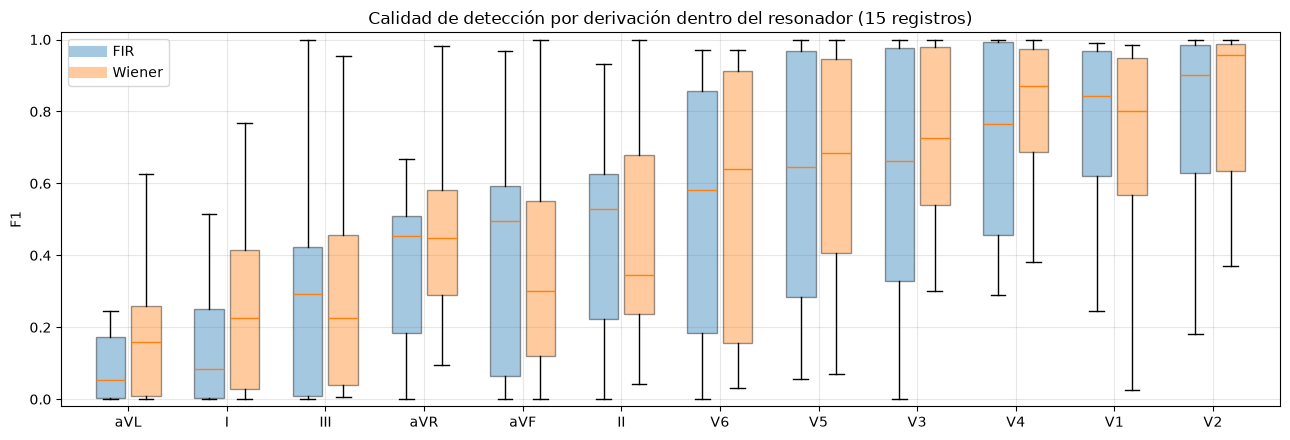

Versión,FIR,Wiener
Derivación,,
aVL,0.05,0.16
I,0.09,0.23
III,0.29,0.23
aVR,0.45,0.45
aVF,0.50,0.30
II,0.53,0.35
V6,0.58,0.64
V5,0.65,0.68
V3,0.66,0.73


In [41]:
# Detección por derivación dentro del resonador
dentro = resultados_deteccion[resultados_deteccion["Condición"] == "Dentro"]
orden = (dentro[dentro["Versión"] == "FIR"]
         .groupby("Derivación")["F1"].median().sort_values().index)

fig, ax = plt.subplots(figsize=(13, 4.5))
posiciones = np.arange(len(orden))
for desplazamiento, version, color in [(-0.18, "FIR", "tab:blue"), (0.18, "Wiener", "tab:orange")]:
    datos = [dentro.loc[(dentro["Versión"] == version) & (dentro["Derivación"] == d), "F1"]
             for d in orden]
    caja = ax.boxplot(datos, positions=posiciones + desplazamiento, widths=0.3,
                      showfliers=False, patch_artist=True)
    for parte in caja["boxes"]:
        parte.set(facecolor=color, alpha=0.4)
    ax.plot([], [], color=color, lw=8, alpha=0.4, label=version)

ax.set_xticks(posiciones)
ax.set_xticklabels(orden)
ax.set(ylabel="F1", ylim=(-0.02, 1.02),
       title="Calidad de detección por derivación dentro del resonador (15 registros)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

display(dentro.pivot_table(index="Derivación", columns="Versión", values="F1",
                           aggfunc="median").loc[orden].round(2))

**La derivación importa mucho más que la versión de la señal.** Las precordiales V1–V4 tienen un F1 mediano de 0,66–0,96, mientras que aVL, I y III no superan 0,30: en esas derivaciones el detector casi no funciona dentro del resonador. Wiener mejora la mediana en la mayoría de las derivaciones, aunque no en todas (empeora en aVF, II, III y V1).

Entonces conviene detectar en una sola derivación por registro, elegida para que el detector funcione bien. Como las anotaciones no pueden usarse para procesar, la elección tiene que hacerse sin mirar la referencia.

### Elección de la derivación sin usar la referencia

Se propone un criterio que solo usa las detecciones: elegir la derivación cuyos intervalos RR detectados son más regulares, es decir, la de menor coeficiente de variación de los RR (desvío estándar dividido por la media). La idea es que el ritmo cardíaco no cambia bruscamente de un latido al siguiente. Si el detector marca deformaciones MHD además de los QRS, aparecen intervalos muy cortos mezclados con intervalos normales y los RR se vuelven irregulares.

Para saber cuánto se pierde por no usar la referencia, el resultado se compara con el de la mejor derivación de cada registro según el F1. Esa segunda elección usa las anotaciones, así que no es un método aplicable: es una cota optimista, lo mejor que se podría lograr eligiendo bien la derivación.

**Criterio para decidir qué versión usar en la sección siguiente:** la que tenga el mayor F1 con la derivación elegida sin referencia, considerando los 15 registros dentro del resonador.

In [42]:
# Elección de una derivación por registro sin usar la referencia
def coeficiente_variacion_rr(detectados):
    rr = np.diff(detectados)
    return np.std(rr) / np.mean(rr) if len(rr) > 2 else np.inf


resultados_deteccion["CV de RR"] = [
    coeficiente_variacion_rr(detecciones[(r, d, v)])
    for r, d, v in resultados_deteccion[["Registro", "Derivación", "Versión"]].values
]

claves_eleccion = ["Registro", "Versión"]
elegida_cv = resultados_deteccion.loc[
    resultados_deteccion.groupby(claves_eleccion)["CV de RR"].idxmin()
]
elegida_mejor = resultados_deteccion.loc[
    resultados_deteccion.groupby(claves_eleccion)["F1"].idxmax()
]

elegidas = pd.concat([
    elegida_cv.assign(**{"Elección": "Sin referencia (RR más regulares)"}),
    elegida_mejor.assign(**{"Elección": "Con referencia (cota optimista)"}),
])
elegidas_dentro = elegidas[elegidas["Condición"] == "Dentro"]

print("Fuera del resonador, F1 con la derivación elegida por regularidad: "
      f"{se_vpp(elegida_cv[elegida_cv['Condición'] == 'Fuera'])['F1']:.3f}")

print("\nDentro del resonador, por campo:")
display(elegidas_dentro.groupby(["Campo (T)", "Elección", "Versión"])[["TP", "FP", "FN"]]
        .apply(se_vpp).unstack("Versión").round(2))

print("Dentro del resonador, los 15 registros juntos:")
display(elegidas_dentro.groupby(["Elección", "Versión"])[["TP", "FP", "FN"]]
        .apply(se_vpp).unstack("Versión").round(2))

print("Derivación elegida por regularidad de RR en cada registro dentro del resonador:")
display(elegida_cv[elegida_cv["Condición"] == "Dentro"]
        .pivot(index="Registro", columns="Versión", values="Derivación"))

Fuera del resonador, F1 con la derivación elegida por regularidad: 1.000

Dentro del resonador, por campo:


Se (%)         VPP (%)         \
Versión                                         FIR  Wiener     FIR Wiener   
Campo (T) Elección                                                           
1         Con referencia (cota optimista)    100.00  100.00   98.77  98.77   
          Sin referencia (RR más regulares)   98.75   98.75   97.53  97.53   
3         Con referencia (cota optimista)     99.82   99.82   99.02  98.85   
          Sin referencia (RR más regulares)   99.01   99.82   96.51  98.85   
7         Con referencia (cota optimista)     97.37   95.27   71.38  82.73   
          Sin referencia (RR más regulares)   62.43   85.38   42.59  74.11   

                                               F1         
Versión                                       FIR Wiener  
Campo (T) Elección                                        
1         Con referencia (cota optimista)    0.99   0.99  
          Sin referencia (RR más regulares)  0.98   0.98  
3         Con referencia (cota optimista)    0.99   0.99  
          Sin referencia (RR más regulares)  0.98   0.99  
7         Con referencia (cota optimista)    0.82   0.89  
          Sin referencia (RR más regulares)  0.51   0.79

Dentro del resonador, los 15 registros juntos:


Se (%)        VPP (%)           F1       
Versión                              FIR Wiener     FIR Wiener   FIR Wiener
Elección                                                                   
Con referencia (cota optimista)    98.28  96.95   79.70  88.18  0.88   0.92
Sin referencia (RR más regulares)  75.89  90.67   58.22  82.45  0.66   0.86

Derivación elegida por regularidad de RR en cada registro dentro del resonador:


Versión,FIR,Wiener
Registro,,
ECGMRI1T01Pro,V6,V6
ECGMRI1T01Sup,V3,V5
ECGMRI3T01Ff,V3,V2
ECGMRI3T01Hf,V4,V4
ECGMRI3T02Ff,aVR,V3
ECGMRI3T03Ff,V3,V3
ECGMRI3T04Ff,V2,V3
ECGMRI7T01Ff,V2,V2
ECGMRI7T01Hf,V1,V5


### Resultado de la elección de derivación

**Fuera del resonador**, la derivación elegida por regularidad detecta todos los latidos sin errores (F1 = 1,000).

**En 1 T y 3 T**, el criterio sin referencia funciona casi tan bien como la cota optimista, en las dos versiones: F1 de 0,98–0,99, contra 0,99 de la cota. Las derivaciones elegidas son casi siempre precordiales, coherente con el análisis por derivación.

**En 7 T el criterio funciona bien con Wiener y mal con FIR**: con Wiener, el F1 es 0,79 (cota: 0,89); con FIR, cae a 0,51 (cota: 0,82). Con FIR, en dos registros de 7 T el criterio eligió una derivación de miembros (aVL en 7T03Hf, II en 7T05Hf), donde el detector funciona mal. Esto muestra una limitación del criterio: si el detector marca una deformación que aparece en todos los latidos, siempre a la misma distancia del R, los RR quedan regulares aunque las detecciones no estén sobre el pico R. La regularidad no distingue un pico R de una deformación que se repite igual en cada latido.

**Considerando los 15 registros juntos**, con la derivación elegida sin referencia, Wiener tiene un F1 de 0,86 (Se 90,7 %, VPP 82,5 %) y FIR, de 0,66 (Se 75,9 %, VPP 58,2 %).

**Decisión: los picos R que se usan en la sección siguiente son los detectados sobre la salida de Wiener, en la derivación con los RR más regulares de cada registro.** Fuera del resonador se usan los detectados sobre la señal con FIR con el mismo criterio. Como las derivaciones de un registro se adquieren en simultáneo, los R detectados en la derivación elegida sirven para ubicar los latidos en todas las derivaciones de ese registro.

Este resultado no era el esperado después de la sección 4. Wiener reduce el MHD a costa de reducir también el ECG, y aun así facilita la detección. Una posible explicación es que la atenuación no es pareja: en 7 T, la ganancia media de Wiener es 0,14 en 0,67–10 Hz, donde domina el MHD, y 0,34 en 10–40 Hz. Al atenuar más la zona donde está la deformación, el QRS queda relativamente más marcado frente a ella en la banda de 5–15 Hz que usa el detector. Aun así, en 7 T más de 1 de cada 4 detecciones sigue siendo falsa (VPP de 74 %), y esos errores van a afectar a los métodos que usen estos R.

## 6. Correcciones latido a latido

La sección 5 dejó, para cada registro, la posición de los picos R detectados sin usar la referencia: sobre la salida de Wiener en frecuencia dentro del resonador y sobre la señal con FIR fuera, en la derivación con los RR más regulares. Con esas posiciones ya se pueden aplicar métodos que trabajan latido a latido, alineando los latidos en el pico R.

Esto permite aprovechar una propiedad del MHD que el Wiener en frecuencia no podía usar: como lo genera el flujo de sangre de cada latido, aparece sincronizado con el ciclo cardíaco. Se aplican dos métodos:

- **Resta de plantilla:** se estima la forma promedio del MHD y se la resta en cada latido.
- **Wiener en el tiempo**, como lo plantearon Krug et al. (2012): un filtro que transforma cada latido de adentro en uno lo más parecido posible al latido de afuera.

### Decisiones generales

- **Señal sobre la que se corrige: la señal con FIR**, no la salida de Wiener en frecuencia. La sección 4 mostró que Wiener en frecuencia reduce y deforma el ECG; sirvió para ubicar los R, pero no para recuperar la forma del latido. Como Wiener es de fase cero, los R detectados en su salida están en la misma posición que en la señal con FIR.
- **Todas las derivaciones con los mismos R.** Las derivaciones de un registro se adquieren en simultáneo, así que los R de la derivación elegida ubican los latidos en todas.
- **Picos detectados y picos de referencia.** Cada método se aplica dos veces: con los R detectados, que es el método real, y con los R de referencia, que es una cota que muestra lo que se lograría con un detector perfecto. La diferencia entre las dos indica cuánto afectan los errores de detección.
- **Entrenamiento y evaluación separados.** Los dos métodos estiman algo a partir de los latidos: la plantilla, o los coeficientes del filtro. Si se evaluaran con los mismos latidos que se usaron para estimarlos, el resultado quedaría inflado. Por eso se estiman con la primera mitad de los latidos de cada registro y se aplican y evalúan en la segunda mitad. Krug et al. (2012) siguieron el mismo criterio, con 10 latidos para estimar y otros 10 para evaluar.

### Ventana de cada latido

Para recortar los latidos hace falta una ventana alrededor de cada R que incluya la onda P y la onda T sin llegar al latido siguiente. Para elegirla se revisan los intervalos RR obtenidos con los picos detectados.

In [43]:
# Picos R para alinear los latidos
# Detectados: salida de Wiener (dentro) o señal con FIR (fuera), en la derivación
# elegida por regularidad de los RR. 
derivacion_elegida = elegida_cv.set_index(["Registro", "Versión"])["Derivación"]

picos_detectados = {}
for nombre in referencias:
    version = "Wiener" if dentro_por_registro[nombre] else "FIR"
    picos_detectados[nombre] = detecciones[(nombre, derivacion_elegida[(nombre, version)], version)]

conjuntos_r = {"Detectados": picos_detectados, "Referencia": referencias}

# Intervalos RR a partir de los picos detectados (sin usar la referencia)
filas_rr = []
for nombre, picos in picos_detectados.items():
    rr = np.diff(picos) / FS
    filas_rr.append({
        "Registro": nombre,
        "Condición": "Dentro" if dentro_por_registro[nombre] else "Fuera",
        "Picos detectados": len(picos),
        "RR mediana (s)": np.median(rr),
        "RR percentil 5 (s)": np.percentile(rr, 5),
    })

intervalos_rr = pd.DataFrame(filas_rr).sort_values(["Condición", "RR mediana (s)"])
display(intervalos_rr.round(3))

,Registro,Condición,Picos detectados,RR mediana (s),RR percentil 5 (s)
10,ECGMRI7T02Hf,Dentro,389,0.452,0.229
6,ECGMRI3T04Ff,Dentro,162,0.650,0.589
1,ECGMRI1T01Sup,Dentro,31,0.678,0.608
0,ECGMRI1T01Pro,Dentro,50,0.696,0.534
4,ECGMRI3T02Ff,Dentro,25,0.845,0.455
14,ECGMRI7T05Hf,Dentro,415,0.887,0.359
13,ECGMRI7T05Ff,Dentro,345,0.891,0.362
2,ECGMRI3T01Ff,Dentro,356,0.913,0.823
3,ECGMRI3T01Hf,Dentro,396,0.923,0.848
9,ECGMRI7T02Ff,Dentro,305,0.944,0.358


Fuera del resonador, donde la detección es prácticamente perfecta, la mediana de RR más corta es 0,64 s (ECGMRI3T04Out), y el percentil 5 más bajo es 0,58 s.

Dentro del resonador, la mayoría de los registros tiene medianas parecidas a las de afuera. Algunos, sin embargo, tienen intervalos que no son fisiológicos: en ECGMRI7T02Hf la mediana es 0,45 s, y en varios registros de 7 T el percentil 5 queda entre 0,23 y 0,50 s. No es que el corazón lata más rápido: son detecciones falsas que parten un intervalo real en dos. Ya se sabía que la detección en 7 T no es perfecta, y estos latidos falsos van a quedar incluidos en la segmentación con los R detectados.

**Decisión: ventana de 600 ms, desde 200 ms antes hasta 400 ms después del pico R.** Es más corta que la mediana de RR del registro más rápido fuera del resonador (0,64 s), así que en el latido típico la ventana no llega al latido siguiente. Los 200 ms previos cubren la onda P y los 400 ms posteriores llegan al final de la onda T, como se ve en los latidos de afuera de la figura siguiente.

Para ver cómo quedan los latidos segmentados, se superponen todos los latidos de dos registros de ejemplo, con los picos detectados.

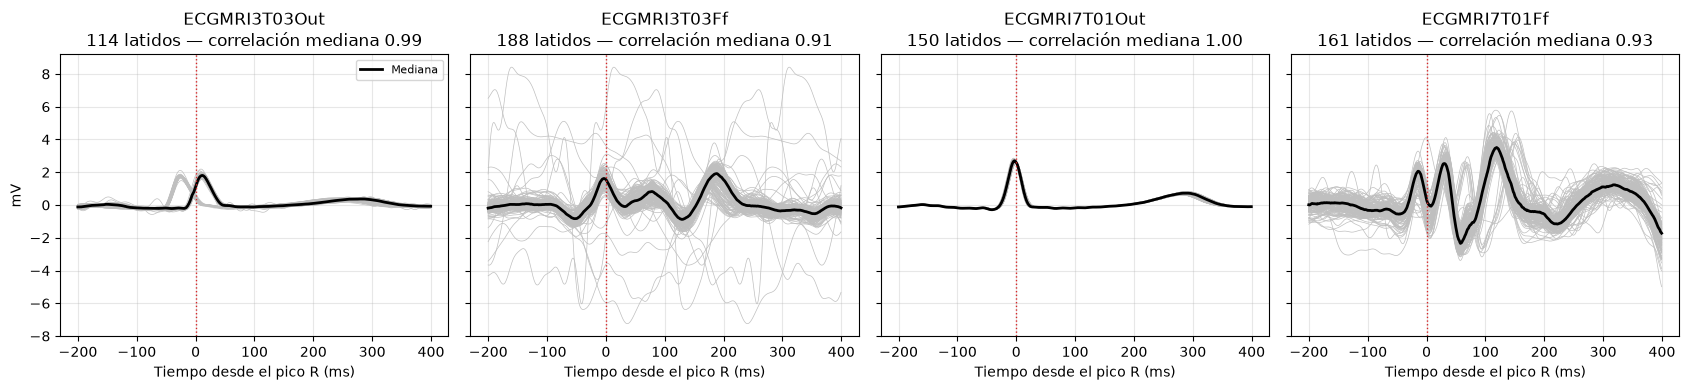

In [44]:
# Segmentación en latidos y división en entrenamiento y evaluación
ANTES_R_S = 0.20
DESPUES_R_S = 0.40
ANTES_R = int(round(ANTES_R_S * FS))
DESPUES_R = int(round(DESPUES_R_S * FS))
t_latido_ms = np.arange(-ANTES_R, DESPUES_R) / FS * 1000


def picos_validos(x, picos):
    """Picos cuya ventana entra completa en la señal."""
    picos = np.asarray(picos)
    return picos[(picos >= ANTES_R) & (picos + DESPUES_R <= len(x))]


def segmentar(x, picos):
    """Matriz latidos × muestras, recortada de −200 a +400 ms alrededor de cada pico."""
    picos = picos_validos(x, picos)
    return np.array([x[p - ANTES_R: p + DESPUES_R] for p in picos])


def dividir_latidos(picos):
    """Primera mitad de los picos para entrenar, segunda mitad para evaluar."""
    picos = np.asarray(picos)
    mitad = len(picos) // 2
    return picos[:mitad], picos[mitad:]


# Ejemplo: latidos superpuestos con los picos detectados (derivación II)
ejemplos_latidos = ["ECGMRI3T03Out", "ECGMRI3T03Ff", "ECGMRI7T01Out", "ECGMRI7T01Ff"]
fig, ejes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)

for ax, nombre in zip(ejes, ejemplos_latidos):
    _, x = senal_fir(nombre, "II")
    latidos = segmentar(x, picos_detectados[nombre])
    mediana = np.median(latidos, axis=0)
    correlacion = np.median([np.corrcoef(l, mediana)[0, 1] for l in latidos])

    ax.plot(t_latido_ms, latidos.T, color="0.75", lw=0.5)
    ax.plot(t_latido_ms, mediana, color="k", lw=2, label="Mediana")
    ax.axvline(0, color="tab:red", ls=":", lw=1)
    ax.set(title=f"{nombre}\n{len(latidos)} latidos — correlación mediana {correlacion:.2f}",
           xlabel="Tiempo desde el pico R (ms)")
    ax.grid(alpha=0.3)

ejes[0].set_ylabel("mV")
ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Fuera del resonador**, todos los latidos tienen prácticamente la misma forma: la correlación mediana de cada latido con la mediana del registro es 0,99 en 3T03 y 1,00 en 7T01.

**Dentro del resonador**, cada latido tiene, después del QRS, deformaciones grandes que no existen afuera: el MHD. Lo importante es que esas deformaciones se repiten con la misma forma y en el mismo momento en todos los latidos. Por eso la mediana dentro del resonador sigue teniendo una forma bien definida, y la correlación mediana sigue siendo alta (0,91 en 3T03 y 0,93 en 7T01). Esta regularidad es la que aprovechan los dos métodos de esta sección.

La correlación es menor que afuera por dos motivos que se ven en la figura: el MHD varía un poco de un latido a otro, y en 3T03 hay algunos latidos muy distintos del resto, que son detecciones falsas recortadas en lugares que no corresponden a un latido. Para que esos latidos no deformen la estimación, en la plantilla se usa la mediana de los latidos de adentro y no el promedio. La mediana no se ve afectada por unos pocos valores muy distintos.

### Resta de plantilla

El latido de adentro puede verse como la suma del ECG y del MHD; el latido de afuera tiene solo el ECG. La plantilla del MHD se estima como la diferencia entre los dos:

plantilla = mediana de los latidos de adentro (entrenamiento) − promedio de los latidos de afuera

Después se resta la plantilla en cada latido de evaluación, centrada en su pico R. El método supone que el ECG del sujeto es el mismo dentro y fuera del resonador y que el MHD es igual en todos los latidos. Ninguna de las dos cosas se cumple del todo.

In [45]:
# Corrección por resta de plantilla
def corregir_plantilla(x_dentro, picos_dentro, x_fuera, picos_fuera):
    """Estima la plantilla del MHD con la primera mitad de los latidos
    y la resta en cada latido de la segunda mitad.

    Devuelve (señal corregida, plantilla, picos de evaluación).
    """
    entrenamiento, evaluacion = dividir_latidos(picos_dentro)

    latido_dentro = np.median(segmentar(x_dentro, entrenamiento), axis=0)
    latido_fuera = np.mean(segmentar(x_fuera, picos_fuera), axis=0)
    plantilla = latido_dentro - latido_fuera

    y = x_dentro.copy()
    for p in picos_validos(x_dentro, evaluacion):
        y[p - ANTES_R: p + DESPUES_R] -= plantilla
    return y, plantilla, evaluacion

### Wiener en el tiempo

Se sigue el planteo de Krug et al. (2012), con la notación del apunte de la materia:

- **Entrada** u[n]: la señal con FIR dentro del resonador.
- **Señal deseada** d[n]: el latido promedio fuera del resonador, del mismo sujeto y derivación.
- **Salida** y[n] = Σ b_k · u[n − k]: un filtro FIR cuyos coeficientes b minimizan el error cuadrático medio E{(d − y)²}. Resultan de la ecuación de Wiener–Hopf, **R_uu · b = r_ud**.

Como en Krug et al. (2012), el filtro se aplica a un tramo de 500 ms que empieza 20 ms después del pico R, donde están el segmento ST, la onda T y la mayor parte del MHD. El QRS no se modifica. Se usa la misma cantidad de coeficientes que en ese trabajo, 201 (impar, para que el filtro quede centrado): cada salida se calcula con las muestras de entrada entre 98 ms antes y 98 ms después.

R_uu y r_ud se estiman con los tramos de los latidos de entrenamiento: R_uu es la autocorrelación de la entrada (201 × 201), y r_ud, la correlación entre la entrada y la señal deseada. Antes de resolver el sistema, se revisa si la matriz R_uu está bien condicionada, con un registro de ejemplo.

In [46]:
# Wiener en el tiempo: construcción de las ecuaciones de Wiener–Hopf
from numpy.lib.stride_tricks import sliding_window_view

INICIO_WT_S = 0.020          # el tramo empieza 20 ms después del R (Krug et al., 2012)
FIN_WT_S = 0.520             # y dura 500 ms
MITAD_FILTRO = 100           # filtro centrado de 2·100 + 1 = 201 coeficientes
INICIO_WT = int(round(INICIO_WT_S * FS))
FIN_WT = int(round(FIN_WT_S * FS))


def ecuaciones_wiener_hopf(x_dentro, picos_entrenamiento, latido_deseado):
    """Estima R_uu y r_ud con los latidos de entrenamiento.

    Cada fila de U contiene las 201 muestras de entrada centradas en un instante
    del tramo; D contiene el valor deseado en ese instante.
    """
    ventanas = sliding_window_view(x_dentro, 2 * MITAD_FILTRO + 1)
    filas_u, filas_d = [], []
    for p in picos_entrenamiento:
        a, b = p + INICIO_WT - MITAD_FILTRO, p + FIN_WT - MITAD_FILTRO
        if a >= 0 and b <= len(ventanas):
            filas_u.append(ventanas[a:b])
            filas_d.append(latido_deseado)
    U, D = np.vstack(filas_u), np.concatenate(filas_d)
    return U.T @ U / len(U), U.T @ D / len(U), U, D


def latido_promedio_tramo(x, picos):
    """Promedio de los tramos [R + 20 ms, R + 520 ms) de un registro."""
    return np.mean([x[p + INICIO_WT: p + FIN_WT] for p in picos
                    if p + FIN_WT <= len(x)], axis=0)


# Ejemplo: 3T03Ff, derivación II, con los picos detectados
w = wiener_derivacion("ECGMRI3T03Ff", "ECGMRI3T03Out", "II")
entrenamiento, _ = dividir_latidos(picos_detectados["ECGMRI3T03Ff"])
deseado = latido_promedio_tramo(w["Fuera"], picos_detectados["ECGMRI3T03Out"])
R_uu, r_ud, U, D = ecuaciones_wiener_hopf(w["Entrada"], entrenamiento, deseado)

print(f"Tamaño de R_uu: {R_uu.shape}, filas de entrenamiento: {len(U)}")
print(f"Número de condición de R_uu: {np.linalg.cond(R_uu):.1e}")

# Efecto de agregar λ·I a R_uu (λ relativo a la traza de R_uu / M)
filas_lambda = []
for lam_relativo in [0, 1e-6, 1e-4, 1e-2]:
    lam = lam_relativo * np.trace(R_uu) / len(R_uu)
    b = np.linalg.solve(R_uu + lam * np.eye(len(R_uu)), r_ud)
    filas_lambda.append({
        "λ relativo": lam_relativo,
        "Máximo |b|": np.max(np.abs(b)),
        "Error RMS en entrenamiento (mV)": np.sqrt(np.mean((U @ b - D) ** 2)),
    })
display(pd.DataFrame(filas_lambda))

Tamaño de R_uu: (201, 201), filas de entrenamiento: 48128
Número de condición de R_uu: 3.8e+18


,λ relativo,Máximo |b|,Error RMS en entrenamiento (mV)
0,0.000000,148308.108308,0.186320
1,0.000001,1.299710,0.185747
2,0.000100,0.063564,0.185878
3,0.010000,0.019008,0.185974


**R_uu es prácticamente singular:** su número de condición es del orden de 10¹⁸. Resolviendo el sistema tal cual, algunos coeficientes del filtro valen casi 30 000, cuando la señal es del orden de 1 mV.

El motivo es el preprocesamiento: la entrada pasó por un pasabanda de 0,67–40 Hz y está muestreada a 1024 Hz, así que casi no tiene contenido entre 40 y 512 Hz. Para esas frecuencias, R_uu no tiene información, y sus autovalores asociados son casi cero. El sistema tiene infinitas soluciones con el mismo error, y el cálculo numérico devuelve una con coeficientes enormes, que amplificaría cualquier ruido fuera de la banda.

La solución es la **regularización**: resolver (R_uu + λ·I) · b = r_ud, que equivale a minimizar el error más un término que penaliza coeficientes grandes. Se gana estabilidad a cambio de un pequeño sesgo. λ se expresa en forma relativa al tamaño de R_uu (como fracción de su traza dividida por la dimensión).

En la tabla, con λ relativo de 10⁻⁴ el coeficiente máximo baja de casi 30 000 a 0,06, y el error de entrenamiento casi no cambia (0,1848 contra 0,1859 mV, un 0,6 % más).

**Decisión: se usa λ relativo = 10⁻⁴.** Los coeficientes quedan acotados y el ajuste a los datos de entrenamiento prácticamente no empeora. La elección se hizo solo con los latidos de entrenamiento.

In [47]:
# Corrección por Wiener en el tiempo
LAMBDA_RELATIVO = 1e-4


def corregir_wiener_tiempo(x_dentro, picos_dentro, x_fuera, picos_fuera):
    """Estima el filtro con la primera mitad de los latidos y lo aplica
    al tramo [R + 20 ms, R + 520 ms) de cada latido de la segunda mitad.

    Devuelve (señal corregida, coeficientes, picos de evaluación).
    """
    entrenamiento, evaluacion = dividir_latidos(picos_dentro)
    deseado = latido_promedio_tramo(x_fuera, picos_fuera)
    R_uu, r_ud, _, _ = ecuaciones_wiener_hopf(x_dentro, entrenamiento, deseado)

    lam = LAMBDA_RELATIVO * np.trace(R_uu) / len(R_uu)
    b = np.linalg.solve(R_uu + lam * np.eye(len(R_uu)), r_ud)

    ventanas = sliding_window_view(x_dentro, 2 * MITAD_FILTRO + 1)
    y = x_dentro.copy()
    for p in evaluacion:
        a, c = p + INICIO_WT - MITAD_FILTRO, p + FIN_WT - MITAD_FILTRO
        if a >= 0 and c <= len(ventanas):
            y[p + INICIO_WT: p + FIN_WT] = ventanas[a:c] @ b
    return y, b, evaluacion

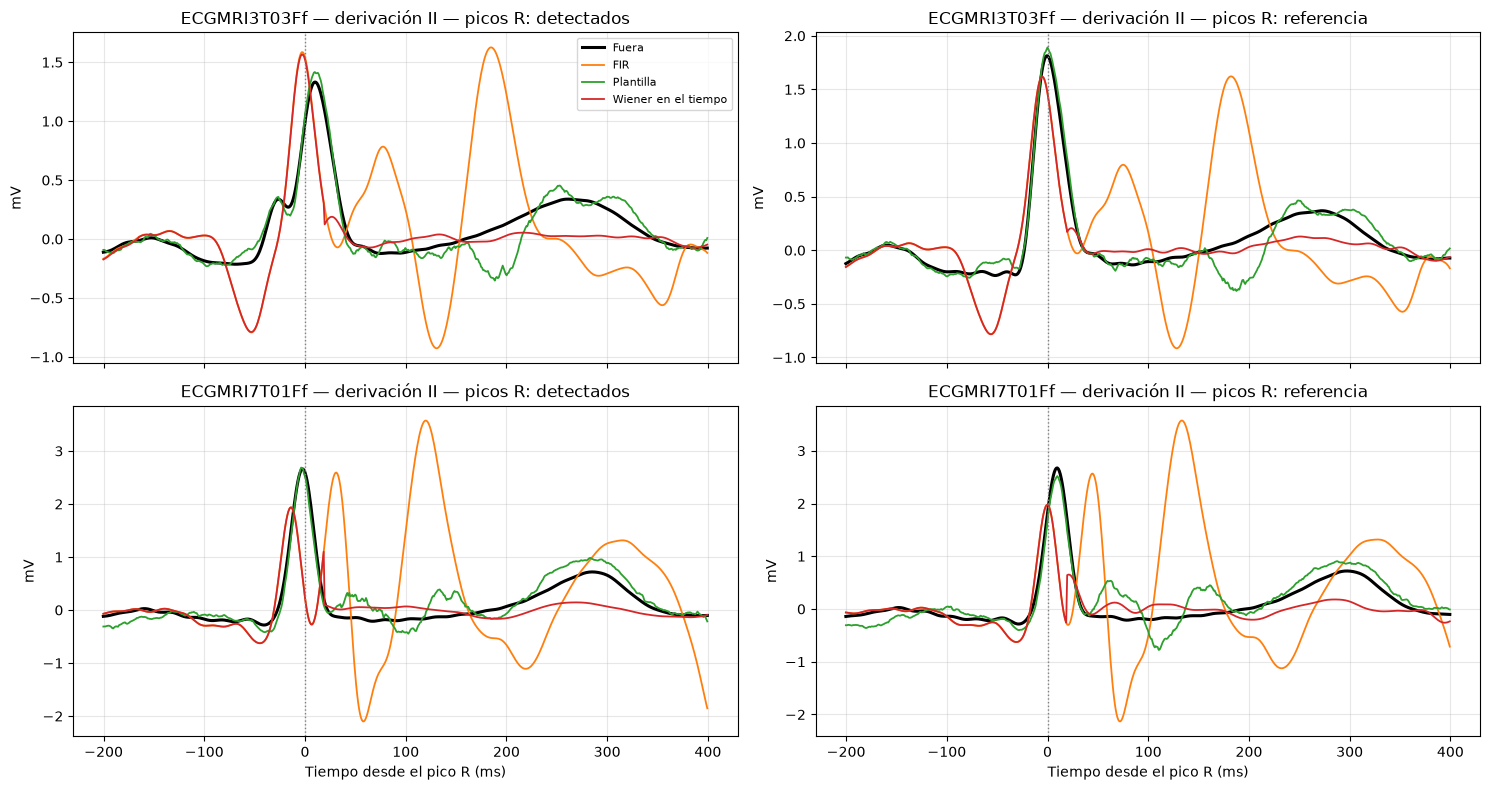

In [48]:
# Ejemplos: latido promedio de evaluación con cada corrección (derivación II)
COLORES_VERSION = {"Fuera": "k", "FIR": "tab:orange",
                   "Plantilla": "tab:green", "Wiener en el tiempo": "tab:red"}

fig, ejes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)

for fila, (nombre_dentro, nombre_fuera) in enumerate(ejemplos_wiener):
    w = wiener_derivacion(nombre_dentro, nombre_fuera, "II")
    for col, (conjunto, picos) in enumerate(conjuntos_r.items()):
        y_plantilla, _, evaluacion = corregir_plantilla(
            w["Entrada"], picos[nombre_dentro], w["Fuera"], picos[nombre_fuera])
        y_wiener_t, _, _ = corregir_wiener_tiempo(
            w["Entrada"], picos[nombre_dentro], w["Fuera"], picos[nombre_fuera])

        promedios = {
            "Fuera": segmentar(w["Fuera"], picos[nombre_fuera]).mean(axis=0),
            "FIR": segmentar(w["Entrada"], evaluacion).mean(axis=0),
            "Plantilla": segmentar(y_plantilla, evaluacion).mean(axis=0),
            "Wiener en el tiempo": segmentar(y_wiener_t, evaluacion).mean(axis=0),
        }

        ax = ejes[fila, col]
        for version, latido in promedios.items():
            ax.plot(t_latido_ms, latido, color=COLORES_VERSION[version],
                    lw=2.2 if version == "Fuera" else 1.3, label=version)
        ax.axvline(0, color="0.5", ls=":", lw=1)
        ax.set(title=f"{nombre_dentro} — derivación II — picos R: {conjunto.lower()}",
               ylabel="mV")
        ax.grid(alpha=0.3)

ejes[0, 0].legend(fontsize=8)
for ax in ejes[1]:
    ax.set_xlabel("Tiempo desde el pico R (ms)")
plt.tight_layout()
plt.show()

### Resultado de las correcciones en los ejemplos

La figura muestra el latido promedio de los latidos de **evaluación** (la segunda mitad, que no se usó para estimar nada), comparado con el latido de afuera (negro).

- **Sin corrección (FIR, naranja)**, después del QRS aparecen las ondas del MHD, más grandes que el propio QRS en 7T01.
- **Con la plantilla (verde)**, el latido se parece mucho al de afuera en los dos registros: se recuperan el QRS, el segmento ST y la onda T. Queda un residuo donde el MHD era más grande (alrededor de 180–200 ms en 3T03 y de 100–150 ms en 7T01): el MHD no es exactamente igual en todos los latidos, y la plantilla solo saca su forma típica.
- **Con Wiener en el tiempo (rojo)**, el tramo anterior a R + 20 ms no se modifica por diseño, así que quedan las deformaciones previas al R (por ejemplo, la onda negativa cerca de −60 ms en 3T03). Después de R + 20 ms el MHD desaparece, pero la salida queda casi plana: la onda T casi no se ve (en 7T01, unos 0,15 mV contra unos 0,7 mV afuera). Es el mismo comportamiento que tuvo el Wiener en frecuencia en la sección 4: cuando la entrada se parece poco a la señal deseada, la estimación de mínimo error es una señal atenuada. Coincide con la limitación que describieron Krug et al. (2012).
- **Picos detectados contra picos de referencia:** en estos dos registros, los resultados con los picos detectados y con la referencia son parecidos. En 3T03 la cota alinea un poco mejor el QRS.

Estos son dos ejemplos en una derivación. En la sección siguiente se evalúan las dos correcciones, con los dos conjuntos de picos, en los 15 registros y todas las derivaciones: qué tanto se parece el latido corregido al de afuera y si la detección de los QRS mejora sobre las señales corregidas.

## 7. Evaluación final de las correcciones

Se evalúan dos aspectos de las correcciones del MHD: cuánto se aproxima la
morfología del ECG interno a la referencia externa y cómo cambia la detección
de los complejos QRS. Se comparan cuatro versiones de la señal: FIR,
Wiener en frecuencia, Wiener en el tiempo y resta de plantilla.

Para Wiener en el tiempo y la resta de plantilla se evalúan dos condiciones.
La primera usa los picos R detectados y representa el funcionamiento del
método con un detector automático. La segunda usa los picos R anotados
y permite explorar cuánto cambia el resultado cuando la corrección
dispone de una alineación de referencia. Las correcciones latido a latido
se ajustan en la primera mitad de cada registro y se evalúan en un tramo
reservado de la segunda mitad, común a todas las versiones comparadas.


### 7.1. Evaluación de la morfología

Para cada registro interno y derivación se compara el latido promedio
de cada versión con el latido promedio de la referencia externa del
mismo sujeto y derivación. Todas las versiones internas se alinean con
los mismos R anotados durante la evaluación. De este modo, las diferencias
entre los promedios reflejan los cambios en la forma de onda, con un
criterio de alineación común.

Se calculan tres métricas:

- **Correlación de Pearson:** mide la similitud entre las formas de onda.
  Puede ser alta incluso si la amplitud de una señal queda reducida.
- **Error cuadrático medio (ECM, mV²):** mide la diferencia entre las
  amplitudes de ambos latidos, muestra a muestra.
- **Error absoluto del nivel ST (mV):** mide cuánto difiere el nivel ST
  de cada versión respecto del latido externo. Se registra también la
  diferencia con signo para distinguir elevación de depresión.

Siguiendo a Krug et al. (2012, sección 3.3), el error en el ST se
cuantifica como el promedio de las diferencias absolutas, muestra a
muestra, entre el latido evaluado y la referencia externa, en una
ventana de 20 ms que comienza 80 ms después del punto J.

En este trabajo se fija el punto J en el latido promedio externo y se
usa la misma ventana para todas las versiones alineadas del par
registro–derivación. Krug et al. reportaron errores máximos superiores
a 0,1 mV en algunas derivaciones. Sus resultados sirven como contexto
para nuestro análisis, que aplica la métrica a latidos promedio.

In [49]:
def metricas_morfologia(latido, referencia, j_ms):
    """Compara dos latidos promedio alineados en R."""
    latido = np.asarray(latido, dtype=float)
    referencia = np.asarray(referencia, dtype=float)

    if latido.shape != referencia.shape or latido.shape != t_latido_ms.shape:
        raise ValueError("Los dos latidos deben usar el mismo eje temporal.")

    diferencia = latido - referencia

    correlacion = np.nan
    if np.std(latido) > 0 and np.std(referencia) > 0:
        correlacion = np.corrcoef(latido, referencia)[0, 1]

    # Krug et al. (2012), sección 3.3: ventana de 20 ms desde J + 80 ms.
    inicio_st = j_ms + 80
    fin_st = j_ms + 100

    if not np.isfinite(j_ms) or inicio_st < t_latido_ms[0] or fin_st > t_latido_ms[-1]:
        raise ValueError("El punto J debe definir una ventana ST dentro del recorte.")

    ventana_st = (t_latido_ms >= inicio_st) & (t_latido_ms < fin_st)
    error_st = np.mean(np.abs(diferencia[ventana_st]))

    return {
        "Correlación": correlacion,
        "ECM (mV²)": np.mean(diferencia**2),
        "Error absoluto medio ST (mV)": error_st,
    }

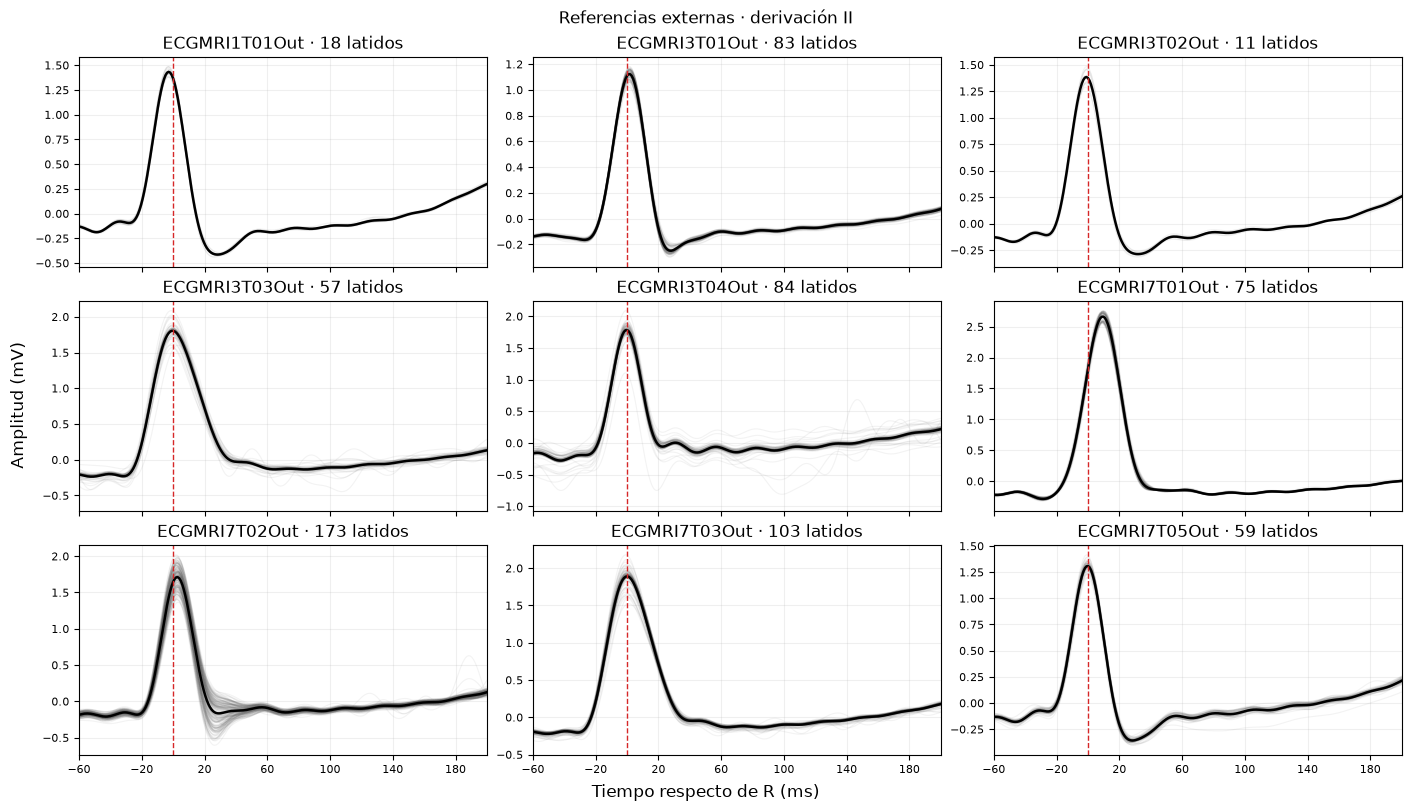

In [63]:
derivacion_revision = "II"
registros_externos = pares_wiener["Registro fuera"].drop_duplicates().tolist()

fig, ejes = plt.subplots(
    3, 3, figsize=(14, 8),
    sharex=True, constrained_layout=True,
)

for ax, registro_ext in zip(ejes.flat, registros_externos):
    _, x_ref = senal_fir(registro_ext, derivacion_revision)
    r_ref = conjuntos_r["Referencia"][registro_ext]
    _, r_eval_ref = dividir_latidos(r_ref)
    latidos_ref = segmentar(x_ref, r_eval_ref)

    ax.set_title(f"{registro_ext} · {len(latidos_ref)} latidos")

    if len(latidos_ref) == 0:
        ax.text(0.5, 0.5, "Sin latidos completos",
                ha="center", va="center", transform=ax.transAxes)
        continue

    ax.plot(t_latido_ms, latidos_ref.T, color="0.4", alpha=0.08, lw=0.8)
    ax.plot(t_latido_ms, latidos_ref.mean(axis=0), color="black", lw=1.8)
    ax.axvline(0, color="tab:red", ls="--", lw=1)
    ax.set_xlim(-60, 200)
    ax.set_xticks(np.arange(-60, 201, 40))
    ax.tick_params(axis="both", labelsize=8)
    ax.grid(alpha=0.2)

fig.supxlabel("Tiempo respecto de R (ms)")
fig.supylabel("Amplitud (mV)")
fig.suptitle(f"Referencias externas · derivación {derivacion_revision}")
plt.show()

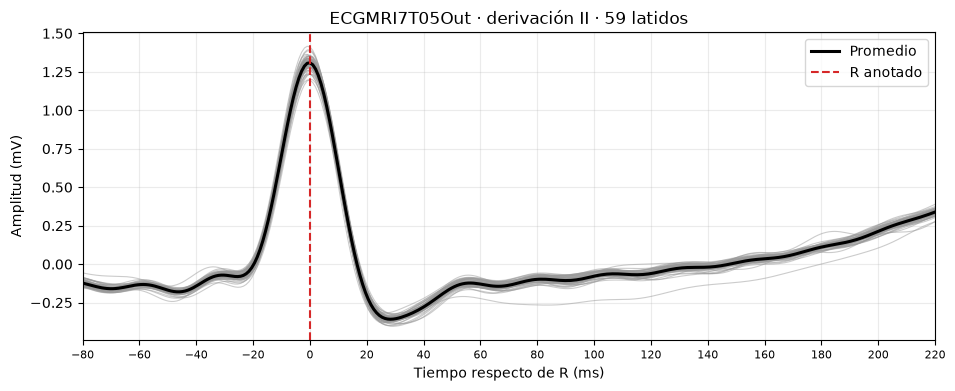

In [64]:
nombre_ext = "ECGMRI7T05Out"
derivacion = "II"

# Cargar la referencia externa filtrada con FIR
_, x_ext = senal_fir(nombre_ext, derivacion)

# Usar la segunda mitad de los R anotados
r_ext = conjuntos_r["Referencia"][nombre_ext]
_, r_eval = dividir_latidos(r_ext)

# Recortar con la ventana de la sección 6 y promediar
latidos_ext = segmentar(x_ext, r_eval)

if len(latidos_ext) == 0:
    raise ValueError("No quedaron latidos completos para graficar.")

latido_ext = latidos_ext.mean(axis=0)

fig, ax = plt.subplots(figsize=(11, 4))

# Latidos individuales alineados en R, con baja opacidad.
ax.plot(t_latido_ms, latidos_ext.T, color="0.6", alpha=0.5, linewidth=0.8)

# Promedio muestra a muestra, por encima de los latidos individuales.
ax.plot(t_latido_ms, latido_ext, color="black", linewidth=2.2, label="Promedio")
ax.axvline(0, color="tab:red", linestyle="--", label="R anotado")

ax.set(
    xlim=(-80, 220),
    xlabel="Tiempo respecto de R (ms)",
    ylabel="Amplitud (mV)",
    title=f"{nombre_ext} · derivación {derivacion} · {len(latidos_ext)} latidos",
)
ax.set_xticks(np.arange(-80, 221, 20))
ax.tick_params(axis="x", labelsize=8)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

In [ ]:
# Buscar la recuperación de S cerca del QRS.
# 100 ms es el límite de búsqueda elegido para este ejemplo.
zona = np.flatnonzero((t_latido_ms > 0) & (t_latido_ms <= 100))
tramo = latido_ext[zona]

# Los picos de la señal invertida son mínimos de la señal original.
minimos, _ = find_peaks(-tramo)
maximos, _ = find_peaks(tramo)

if minimos.size == 0:
    raise ValueError("No se encontró un mínimo local después de R.")

s = minimos[0]
maximos_post_s = maximos[maximos > s]

if maximos_post_s.size == 0:
    raise ValueError("No se encontró un máximo local después de S.")

s_ms = float(t_latido_ms[zona[s]])
j_ms = float(t_latido_ms[zona[maximos_post_s[0]]])

print(f"S: {s_ms:.2f} ms después de R")
print(f"J estimado: {j_ms:.2f} ms después de R")
print(f"Ventana ST: {j_ms + 80:.2f} a {j_ms + 100:.2f} ms después de R")

S: 28.32 ms después de R
J estimado: 56.64 ms después de R
Ventana ST: 136.64 a 156.64 ms después de R


El punto J se estimó en el latido promedio de la referencia externa mediante
una adaptación del criterio de pendiente de Yáñez de la Rivera et al.
(2018, sección 2.2.3, p. 220). A partir del pico R, se identificó el
primer mínimo local posterior como el mínimo de la onda S. El primer
máximo local después de ese mínimo se tomó como estimación del punto J.
En este trabajo, la búsqueda se limitó a los primeros 100 ms posteriores
a R.

Con el J estimado se definió la ventana de análisis del ST entre
J + 80 y J + 100 ms, según Krug et al. (2012, sección 3.3).

**Referencia**

Yáñez de la Rivera, R., Soto-Bajo, M., & Fraguela-Collar, A. (2018).
Electrocardiogram fiducial points detection and estimation methodology
for automatic diagnose. *The Open Bioinformatics Journal, 11*, 208–230.
https://doi.org/10.2174/1875036201811010208

In [73]:
derivacion_revision = "II"
registros_externos = pares_wiener["Registro fuera"].drop_duplicates()
zona_qrs = np.flatnonzero((t_latido_ms > 0) & (t_latido_ms <= 100))

filas_j = []

for registro_ext in registros_externos:
    _, x_ref = senal_fir(registro_ext, derivacion_revision)
    _, r_eval_ref = dividir_latidos(conjuntos_r["Referencia"][registro_ext])
    latidos_ref = segmentar(x_ref, r_eval_ref)

    s_ms = np.nan
    j_candidato_ms = np.nan

    if len(latidos_ref):
        tramo = latidos_ref.mean(axis=0)[zona_qrs]
        minimos, _ = find_peaks(-tramo)
        maximos, _ = find_peaks(tramo)

        if minimos.size:
            s = minimos[0]
            s_ms = float(t_latido_ms[zona_qrs[s]])
            maximos_post_s = maximos[maximos > s]

            if maximos_post_s.size:
                j = maximos_post_s[0]
                j_candidato_ms = float(t_latido_ms[zona_qrs[j]])

    filas_j.append({
        "Registro fuera": registro_ext,
        "Derivación": derivacion_revision,
        "Latidos": len(latidos_ref),
        "S − R (ms)": s_ms,
        "J − R candidato (ms)": j_candidato_ms,
        "Inicio ST (ms)": j_candidato_ms + 80,
        "Fin ST (ms)": j_candidato_ms + 100,
    })

tabla_j = pd.DataFrame(filas_j)
display(tabla_j.round(2))

,Registro fuera,Derivación,Latidos,S − R (ms),J − R candidato (ms),Inicio ST (ms),Fin ST (ms)
0,ECGMRI1T01Out,II,18,28.32,54.69,134.69,154.69
1,ECGMRI3T01Out,II,83,27.34,60.55,140.55,160.55
2,ECGMRI3T02Out,II,11,32.23,55.66,135.66,155.66
3,ECGMRI3T03Out,II,57,64.45,74.22,154.22,174.22
4,ECGMRI3T04Out,II,84,22.46,30.27,110.27,130.27
5,ECGMRI7T01Out,II,75,52.73,61.52,141.52,161.52
6,ECGMRI7T02Out,II,173,29.30,56.64,136.64,156.64
7,ECGMRI7T03Out,II,103,41.02,44.92,124.92,144.92
8,ECGMRI7T05Out,II,59,28.32,56.64,136.64,156.64


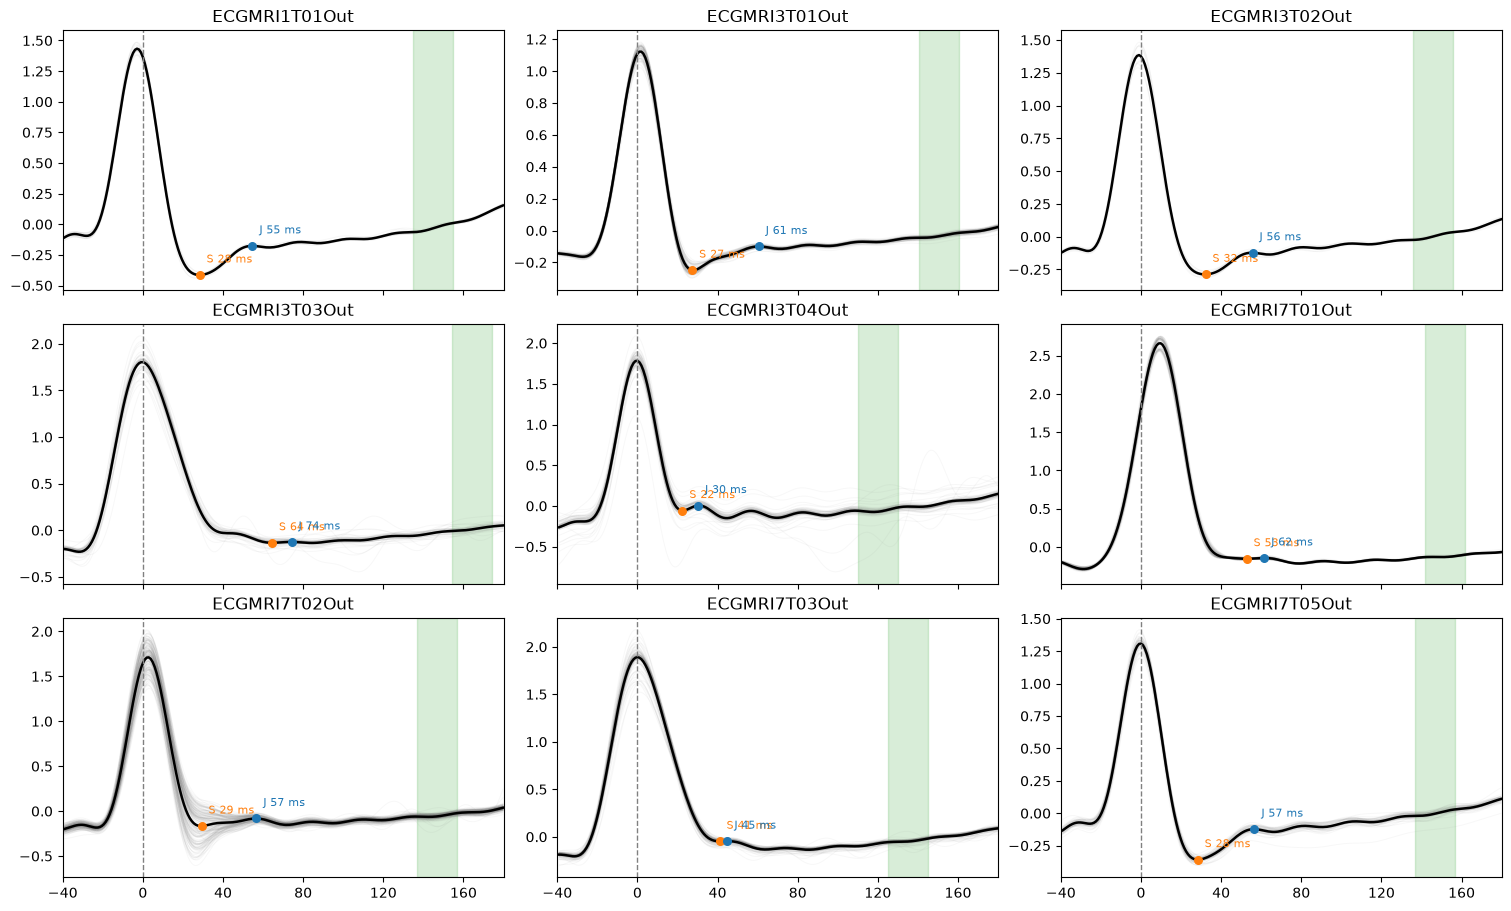

In [68]:
fig, ejes = plt.subplots(
    3, 3, figsize=(15, 9),
    sharex=True, constrained_layout=True,
)

vista = (t_latido_ms >= -40) & (t_latido_ms <= 180)

for ax, (_, fila) in zip(ejes.flat, tabla_j.iterrows()):
    registro_ext = fila["Registro fuera"]
    derivacion = fila["Derivación"]

    _, x_ref = senal_fir(registro_ext, derivacion)
    _, r_eval_ref = dividir_latidos(conjuntos_r["Referencia"][registro_ext])
    latidos_ref = segmentar(x_ref, r_eval_ref)

    ax.set_title(registro_ext)
    if len(latidos_ref) == 0:
        ax.text(0.5, 0.5, "Sin latidos completos", ha="center",
                transform=ax.transAxes)
        continue

    promedio = latidos_ref.mean(axis=0)
    ax.plot(t_latido_ms[vista], latidos_ref[:, vista].T,
            color="0.5", alpha=0.06, lw=0.7)
    ax.plot(t_latido_ms[vista], promedio[vista], color="black", lw=1.8)
    ax.axvline(0, color="0.5", ls="--", lw=1)

    s = fila["S − R (ms)"]
    j = fila["J − R candidato (ms)"]

    for etiqueta, tiempo, color in [("S", s, "tab:orange"), ("J", j, "tab:blue")]:
        if np.isfinite(tiempo):
            amplitud = np.interp(tiempo, t_latido_ms, promedio)
            ax.scatter(tiempo, amplitud, color=color, s=30, zorder=4)
            ax.annotate(f"{etiqueta} {tiempo:.0f} ms", (tiempo, amplitud),
                        xytext=(5, 9), textcoords="offset points",
                        color=color, fontsize=8)

    if np.isfinite(j):
        ax.axvspan(j + 80, j + 100, color="tab:green", alpha=0.18)

    ax.set_xlim(-40, 180)
    ax.set_xticks(np.arange(-40, 181, 40))
    ax.grid

In [76]:
referencias_aceptadas = {
    "ECGMRI1T01Out",
    "ECGMRI3T01Out",
    "ECGMRI3T02Out",
    "ECGMRI7T02Out",
    "ECGMRI7T05Out",
}

tabla_j_final = tabla_j.copy()
candidatos = tabla_j_final["J − R candidato (ms)"]

aceptados = (
    tabla_j_final["Registro fuera"].isin(referencias_aceptadas)
    & np.isfinite(candidatos)
)

if not aceptados.any():
    raise ValueError("No hay candidatos aceptados para calcular el promedio.")

j_promedio_ii = candidatos.loc[aceptados].mean()

tabla_j_final["J − R usado (ms)"] = candidatos.where(aceptados, j_promedio_ii)
tabla_j_final["Origen de J"] = np.where(
    aceptados,
    "Estimado en la señal y revisado",
    "Estimado con el promedio de II",
)
tabla_j_final["Inicio ST (ms)"] = tabla_j_final["J − R usado (ms)"] + 80
tabla_j_final["Fin ST (ms)"] = tabla_j_final["J − R usado (ms)"] + 100

display(tabla_j_final[[
    "Registro fuera", "J − R candidato (ms)", "J − R usado (ms)",
    "Origen de J", "Inicio ST (ms)", "Fin ST (ms)",
]].round(2))

,Registro fuera,J − R candidato (ms),J − R usado (ms),Origen de J,Inicio ST (ms),Fin ST (ms)
0,ECGMRI1T01Out,54.69,54.69,Estimado en la señal y revisado,134.69,154.69
1,ECGMRI3T01Out,60.55,60.55,Estimado en la señal y revisado,140.55,160.55
2,ECGMRI3T02Out,55.66,55.66,Estimado en la señal y revisado,135.66,155.66
3,ECGMRI3T03Out,74.22,56.84,Estimado con el promedio de II,136.84,156.84
4,ECGMRI3T04Out,30.27,56.84,Estimado con el promedio de II,136.84,156.84
5,ECGMRI7T01Out,61.52,56.84,Estimado con el promedio de II,136.84,156.84
6,ECGMRI7T02Out,56.64,56.64,Estimado en la señal y revisado,136.64,156.64
7,ECGMRI7T03Out,44.92,56.84,Estimado con el promedio de II,136.84,156.84
8,ECGMRI7T05Out,56.64,56.64,Estimado en la señal y revisado,136.64,156.64


#### Estimación del punto J en registros con delineación ambigua

Se calculó el intervalo entre el pico R anotado y el punto J candidato
sobre el latido promedio de la derivación II de cada registro externo.
Para revisar los candidatos, se consideraron señales de ambigüedad una
separación muy corta entre S y J o un intervalo R–J alejado de los
observados en los registros con una transición QRS–ST clara. Estos
indicios se interpretaron junto con la forma del latido promedio.

En cinco de los nueve registros, el candidato automático se ubicó en
una transición compatible con el final del QRS y el inicio del ST.
Los intervalos R–J de esos registros fueron 54,69; 60,55; 55,66; 56,64
y 56,64 ms, con un promedio de 56,84 ms. La diferencia motivó una revisión visual.
Los cuatro casos se consideraron ambiguos porque, al revisar el latido
promedio, no pudo confirmarse que el máximo local después de S
correspondiera a la transición entre el QRS y el ST.

Este criterio de revisión se apoya en Yáñez de la Rivera et al. (2018,
sección 2.2.3), quienes señalan que un método basado en cambios de
pendiente puede ubicar incorrectamente los puntos del QRS cuando la
onda S no se distingue con claridad. Los intervalos S–J informados
describen lo observado en estos registros.

Para los cuatro registros con delineación ambigua, se estimó el punto J
a 56,84 ms del pico R anotado. Se utilizó el promedio de los registros
con delineación más clara porque se obtuvo en la misma derivación y
bajo la misma condición de adquisición. Este valor es cercano a los
60 ms que Buelga Suárez et al. (2026, sección 2.5.4) adoptan como
referencia temporal entre el pico R y el final del QRS en su algoritmo.

Referencia — Buelga Suárez et al. (2026). *Performance evaluation of
smartwatches: Can they match clinical standards for ECG analysis?*
Biomedical Signal Processing and Control, 115, 109373.
https://doi.org/10.1016/j.bspc.2025.109373

In [81]:
j_por_registro = tabla_j_final.set_index("Registro fuera")
filas_morfologia_ii = []
senales_evaluacion_ii = {}

for _, par in pares_wiener.iterrows():
    nombre = par["Registro"]
    nombre_ext = par["Registro fuera"]
    j_ext = j_por_registro.loc[nombre_ext]

    w = wiener_derivacion(nombre, nombre_ext, "II")
    x_interno, x_externo = w["Entrada"], w["Fuera"]

    # Referencia externa de evaluación, igual que para estimar J.
    _, r_eval_ext = dividir_latidos(conjuntos_r["Referencia"][nombre_ext])
    latidos_ext = segmentar(x_externo, r_eval_ext)
    if len(latidos_ext) == 0:
        print(f"{nombre}: sin latidos externos completos para evaluar.")
        continue

    promedio_ext = latidos_ext.mean(axis=0)

    # Región interna común, posterior al entrenamiento de ambas ramas.
    mitades_internas = {
        fuente: dividir_latidos(picos[nombre])
        for fuente, picos in conjuntos_r.items()
    }
    fin_entrenamiento = max(
        entrenamiento[-1] + max(DESPUES_R, FIN_WT + MITAD_FILTRO)
        for entrenamiento, _ in mitades_internas.values()
    )
    inicio_comun = max(
        fin_entrenamiento,
        max(evaluacion[0] for _, evaluacion in mitades_internas.values()),
    )

    _, r_eval_interno = mitades_internas["Referencia"]
    r_eval_interno = r_eval_interno[r_eval_interno - ANTES_R >= inicio_comun]
    r_eval_interno = picos_validos(x_interno, r_eval_interno)
    if len(r_eval_interno) == 0:
        print(f"{nombre}: sin latidos completos en el tramo común de evaluación.")
        continue

    versiones = {
        "FIR": x_interno,
        "Wiener en frecuencia": w["Wiener"],
    }

    for fuente, picos in conjuntos_r.items():
        # Ambas correcciones reciben solo los R externos de entrenamiento.
        r_ent_ext, _ = dividir_latidos(picos[nombre_ext])

        y_plantilla, _, _ = corregir_plantilla(
            x_interno, picos[nombre], x_externo, r_ent_ext
        )
        y_wiener_t, _, _ = corregir_wiener_tiempo(
            x_interno, picos[nombre], x_externo, r_ent_ext
        )

        versiones[f"Plantilla ({fuente})"] = y_plantilla
        versiones[f"Wiener en el tiempo ({fuente})"] = y_wiener_t

    j_ms = j_ext["J − R usado (ms)"]
    ventana_st = (
        (t_latido_ms >= j_ext["Inicio ST (ms)"])
        & (t_latido_ms < j_ext["Fin ST (ms)"])
    )
    senales_evaluacion_ii[nombre] = (w["fs"], inicio_comun, versiones)
    for version, senal in versiones.items():
        promedio_interno = segmentar(senal, r_eval_interno).mean(axis=0)

        filas_morfologia_ii.append({
            "Registro": nombre,
            "Registro fuera": nombre_ext,
            "Campo (T)": par["Campo (T)"],
            "Versión": version,
            "Latidos internos": len(r_eval_interno),
            "Latidos externos": len(latidos_ext),
            "Origen de J": j_ext["Origen de J"],
            **metricas_morfologia(promedio_interno, promedio_ext, j_ms),
            "Diferencia media ST con signo (mV)": (
                promedio_interno[ventana_st] - promedio_ext[ventana_st]
            ).mean(),
        })

resultados_morfologia_ii = pd.DataFrame(filas_morfologia_ii)
display(resultados_morfologia_ii.round(4))

,Registro,Registro fuera,Campo (T),Versión,Latidos internos,Latidos externos,Origen de J,Correlación,ECM (mV²),Error absoluto medio ST (mV),Diferencia media ST con signo (mV)
0,ECGMRI1T01Pro,ECGMRI1T01Out,1,FIR,24,18,Estimado en la señal y revisado,0.3929,0.2203,0.9242,-0.9242
1,ECGMRI1T01Pro,ECGMRI1T01Out,1,Wiener en frecuencia,24,18,Estimado en la señal y revisado,0.7634,0.0378,0.0801,-0.0801
2,ECGMRI1T01Pro,ECGMRI1T01Out,1,Plantilla (Detectados),24,18,Estimado en la señal y revisado,0.6993,0.0473,0.2066,-0.2066
3,ECGMRI1T01Pro,ECGMRI1T01Out,1,Wiener en el tiempo (Detectados),24,18,Estimado en la señal y revisado,0.8321,0.0280,0.0248,0.0248
4,ECGMRI1T01Pro,ECGMRI1T01Out,1,Plantilla (Referencia),24,18,Estimado en la señal y revisado,0.8669,0.0220,0.1621,-0.1621
...,...,...,...,...,...,...,...,...,...,...,...
85,ECGMRI7T05Hf,ECGMRI7T05Out,7,Wiener en frecuencia,193,59,Estimado en la señal y revisado,0.3184,0.0673,0.0341,0.0096
86,ECGMRI7T05Hf,ECGMRI7T05Out,7,Plantilla (Detectados),193,59,Estimado en la señal y revisado,0.5761,0.1688,0.6817,-0.6817
87,ECGMRI7T05Hf,ECGMRI7T05Out,7,Wiener en el tiempo (Detectados),193,59,Estimado en la señal y revisado,0.4161,0.3282,0.0841,-0.0841
88,ECGMRI7T05Hf,ECGMRI7T05Out,7,Plantilla (Referencia),193,59,Estimado en la señal y revisado,0.4909,0.1729,0.5017,-0.5017


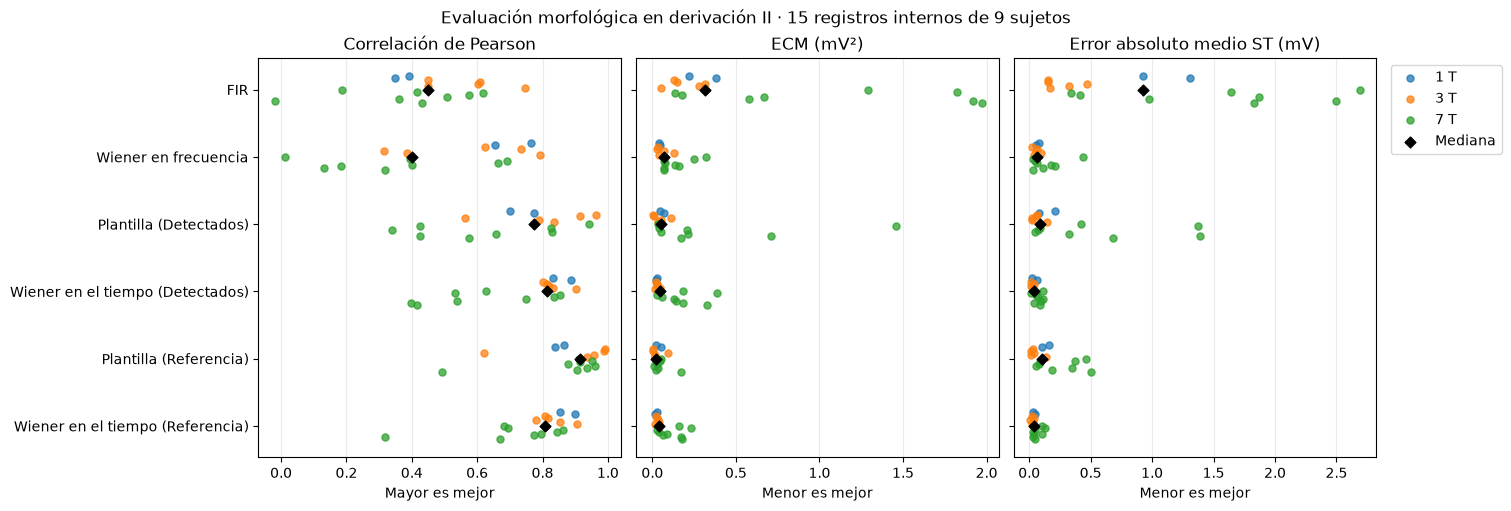

In [79]:
metricas = [
    ("Correlación", "Correlación de Pearson", "Mayor es mejor"),
    ("ECM (mV²)", "ECM (mV²)", "Menor es mejor"),
    ("Error absoluto medio ST (mV)", "Error absoluto medio ST (mV)",
     "Menor es mejor"),
]

versiones = [
    "FIR",
    "Wiener en frecuencia",
    "Plantilla (Detectados)",
    "Wiener en el tiempo (Detectados)",
    "Plantilla (Referencia)",
    "Wiener en el tiempo (Referencia)",
]

datos = resultados_morfologia_ii.copy()
datos["Posición"] = datos["Versión"].map(
    {version: i for i, version in enumerate(versiones)}
)

# Separación vertical para que se vean los puntos de cada versión.
# Cada registro conserva el mismo desplazamiento en los tres paneles.
registros = sorted(datos["Registro"].unique())
desplazamiento = dict(zip(registros, np.linspace(-0.20, 0.20, len(registros))))
datos["Posición del punto"] = (
    datos["Posición"] + datos["Registro"].map(desplazamiento)
)

colores = {1: "tab:blue", 3: "tab:orange", 7: "tab:green"}
fig, ejes = plt.subplots(1, 3, figsize=(15, 5), sharey=True,
                         constrained_layout=True)

for ax, (columna, titulo, criterio) in zip(ejes, metricas):
    for campo, grupo in datos.groupby("Campo (T)"):
        ax.scatter(
            grupo[columna], grupo["Posición del punto"],
            color=colores[campo], alpha=0.75, s=26, label=f"{campo:g} T",
        )

    medianas = datos.groupby("Versión")[columna].median().reindex(versiones)
    ax.scatter(
        medianas, np.arange(len(versiones)),
        color="black", marker="D", s=30, zorder=3, label="Mediana",
    )
    ax.set(title=titulo, xlabel=criterio)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

ejes[0].set_yticks(np.arange(len(versiones)), versiones)
ejes[0].invert_yaxis()
ejes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Evaluación morfológica en derivación II · 15 registros internos de 9 sujetos")
plt.show()

#### Resultados de la evaluación morfológica en derivación II

Se compararon seis versiones del procesamiento en 15 registros internos.
Para cada registro, todas las versiones se evaluaron sobre los mismos
latidos alineados con los R anotados y se compararon con el mismo latido
promedio externo. La figura muestra un punto por registro y versión.
El color identifica el campo de adquisición y el rombo negro indica
la mediana de cada versión.

La correlación y el ECM describen el latido completo. El error absoluto
medio ST describe únicamente la diferencia muestra a muestra en la
ventana de J + 80 a J + 100 ms. Por eso, la versión con mayor similitud
global puede diferir de la que mejor aproxima el ST.

En `ECGMRI1T01Pro`, el Wiener en el tiempo con R detectados redujo
el error ST de 0,9242 mV con FIR a 0,0248 mV. También aumentó la
correlación de 0,3929 a 0,8321 y redujo el ECM de 0,2203 a
0,0280 mV². En este registro, la mejora se observó tanto en el ST
como en las métricas del latido completo.

En `ECGMRI7T05Hf`, el Wiener en frecuencia obtuvo un error ST
de 0,0341 mV y una correlación de 0,3184. El Wiener en el tiempo
con R anotados obtuvo una correlación mayor, de 0,6713, con un
error ST de 0,0500 mV. En este caso, la comparación entre ambos
métodos cambia según se priorice el ST o la similitud de la forma
de onda completa.

La tabla detallada también conserva la diferencia media ST con
signo. Un valor negativo indica que el promedio interno quedó por
debajo del externo en esa ventana. En `ECGMRI7T05Hf`, con Wiener
en frecuencia, la diferencia con signo fue de +0,0096 mV y el
error absoluto medio fue de 0,0341 mV. La diferencia con signo
es menor porque las desviaciones positivas y negativas se
compensan parcialmente al promediarlas.

### 7.2. Detección de los complejos QRS después de la corrección

La detección se realizó en dos pasos. Primero se obtuvieron los picos R
que guiaron las correcciones latido a latido. Luego se volvió a ejecutar
Pan–Tompkins sobre FIR, Wiener en frecuencia y las salidas corregidas,
usando la derivación II en todas las versiones.

Para cada registro interno, se compararon las detecciones con los R
anotados en el mismo tramo de evaluación, posterior al entrenamiento
de ambas ramas. Se conservó la tolerancia de ±50 ms de la sección 5
y se calcularon sensibilidad (Se), valor predictivo positivo (VPP) y F1.

Las correcciones guiadas por R anotados muestran el resultado con
alineación de referencia. Para evaluar el funcionamiento automático
se consideran las correcciones guiadas por R detectados.

#### Métricas de detección de complejos QRS

Para evaluar la detección después de cada corrección, se compararon los
picos R detectados por Pan–Tompkins con los picos R anotados en el mismo
tramo del ECG. Se usó una tolerancia de ±50 ms y cada detección y cada
anotación se usaron como máximo en un emparejamiento.

- **Verdadero positivo (TP)** — un pico R anotado que se emparejó con una detección.
- **Falso positivo (FP)** — una detección que quedó sin una anotación correspondiente.
- **Falso negativo (FN)** — un pico R anotado que quedó sin una detección correspondiente.

| Métrica | Qué mide | Cálculo |
|---|---|---|
| **Sensibilidad (Se)** | Proporción de latidos anotados que el algoritmo detectó. | $TP/(TP+FN)$ |
| **Valor predictivo positivo (VPP)** | Proporción de detecciones que coincidieron con un latido anotado. | $TP/(TP+FP)$ |
| **F1** | Media armónica de la sensibilidad y el VPP. Resume ambos aspectos de la detección. | $2TP/(2TP+FP+FN)$ |

Para cada versión se sumaron los TP, FP y FN de los 15 registros internos
en derivación II antes de calcular las métricas. La sensibilidad y el VPP
se expresaron en porcentaje. En la figura, se multiplicó F1 por 100 para
mostrar las tres métricas en la misma escala.

Por ejemplo, Wiener en el tiempo con R detectados encontró aproximadamente
85 de cada 100 latidos anotados (Se = 84,6 %). De cada 100 detecciones
que produjo, unas 62 coincidieron con una anotación (VPP = 62,3 %).
El F1 fue de 0,718 y aparece como 71,8 en la figura.

In [82]:
filas_deteccion_final = []
picos_prueba_ii = {}

for nombre, (fs, inicio, versiones) in senales_evaluacion_ii.items():
    fin = len(versiones["FIR"])
    r_ref = conjuntos_r["Referencia"][nombre]
    r_ref = r_ref[(r_ref >= inicio) & (r_ref < fin)]
    picos_prueba_ii[nombre] = {"Referencia": r_ref}

    for version, senal in versiones.items():
        r_det, _ = pan_tompkins(senal, fs)
        r_det = np.unique(r_det[(r_det >= inicio) & (r_det < fin)])
        picos_prueba_ii[nombre][version] = r_det

        tp = emparejar(r_ref, r_det, TOLERANCIA_S * fs)
        filas_deteccion_final.append({
            "Registro": nombre,
            "Campo (T)": info_registros.loc[nombre, "Campo (T)"],
            "Versión": version,
            "TP": tp,
            "FP": len(r_det) - tp,
            "FN": len(r_ref) - tp,
        })

resultados_deteccion_final_ii = pd.DataFrame(filas_deteccion_final)

resumen_deteccion_final_ii = (
    resultados_deteccion_final_ii
    .groupby("Versión", sort=False)[["TP", "FP", "FN"]]
    .apply(se_vpp)
)

display(resumen_deteccion_final_ii.round(3))

,Se (%),VPP (%),F1
Versión,,,
FIR,64.087,32.962,0.435
Wiener en frecuencia,57.585,33.405,0.423
Plantilla (Detectados),61.920,36.819,0.462
Wiener en el tiempo (Detectados),84.644,62.335,0.718
Plantilla (Referencia),75.480,40.633,0.528
Wiener en el tiempo (Referencia),92.879,57.781,0.712


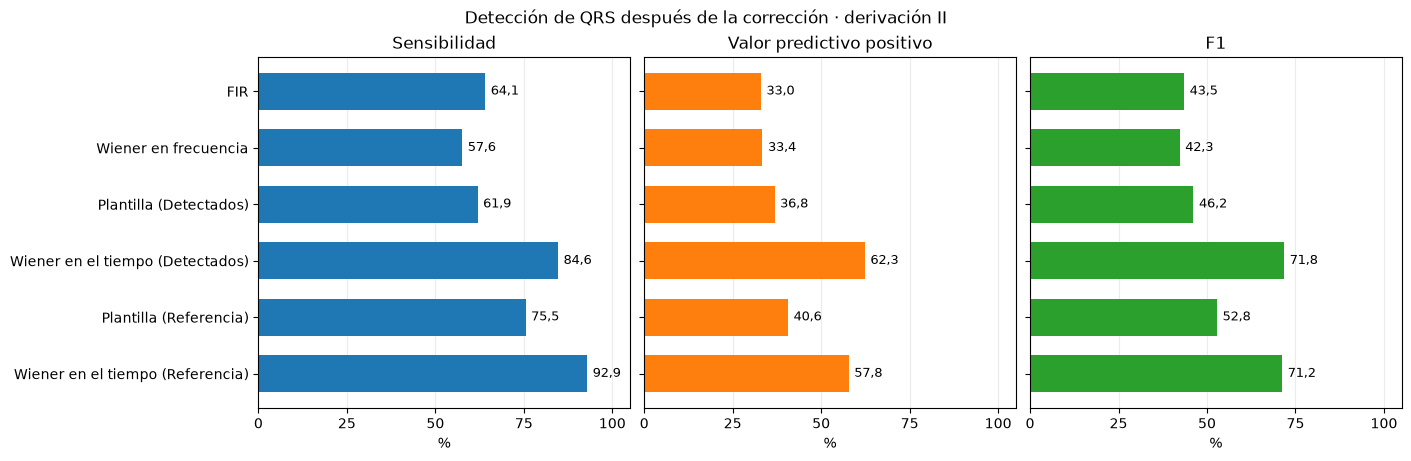

In [83]:
datos_grafico = resumen_deteccion_final_ii.copy()
datos_grafico["F1 (%)"] = 100 * datos_grafico["F1"]

paneles = [
    ("Se (%)", "Sensibilidad", "tab:blue"),
    ("VPP (%)", "Valor predictivo positivo", "tab:orange"),
    ("F1 (%)", "F1", "tab:green"),
]

posiciones = np.arange(len(datos_grafico))
fig, ejes = plt.subplots(
    1, 3, figsize=(14, 4.5), sharey=True, constrained_layout=True
)

for ax, (columna, titulo, color) in zip(ejes, paneles):
    barras = ax.barh(
        posiciones, datos_grafico[columna], color=color, height=0.65
    )
    ax.bar_label(
        barras,
        labels=[f"{valor:.1f}".replace(".", ",") for valor in datos_grafico[columna]],
        padding=4,
        fontsize=9,
    )
    ax.set(title=titulo, xlabel="%", xlim=(0, 105))
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.25)

ejes[0].set_yticks(posiciones, datos_grafico.index)
ejes[0].invert_yaxis()
fig.suptitle("Detección de QRS después de la corrección · derivación II")
plt.show()

#### Conclusión de la evaluación de la detección

En los 15 registros internos evaluados en derivación II, **Wiener en
el tiempo guiado por R detectados** obtuvo el mayor F1 (0,718).
Respecto de FIR, la sensibilidad aumentó de 64,1 % a 84,6 % y el
valor predictivo positivo (VPP) pasó de 33,0 % a 62,3 %. En conjunto,
el detector recuperó una mayor proporción de los latidos anotados
y una mayor proporción de sus detecciones correspondió a latidos reales.

Al guiar la corrección de Wiener en el tiempo con R anotados, la
sensibilidad subió a 92,9 %, mientras que el VPP bajó a 57,8 %.
Como resultado, el F1 fue similar al de la rama automática (0,712).
La resta de plantilla logró mejoras más moderadas frente a FIR, con
un F1 de 0,462 usando R detectados y de 0,528 usando R anotados.
Wiener en frecuencia obtuvo un F1 de 0,423, ligeramente inferior
al de FIR (0,435).

Aunque Wiener en el tiempo con R detectados obtuvo el mejor
equilibrio entre sensibilidad y VPP, aproximadamente el 38 % de
sus detecciones siguió sin corresponder a un latido anotado.
En la sección 8 se analiza cómo los errores de detección afectan
los intervalos RR y los índices de variabilidad cardíaca.

## 8. Variabilidad de la frecuencia cardíaca

### 8.1. Análisis temporal de los intervalos RR

Para cada registro interno se calcularon los intervalos RR como la
diferencia temporal entre dos picos R consecutivos. Se compararon los
RR obtenidos con los R anotados y los obtenidos con Pan–Tompkins en
cada versión de la señal, dentro del mismo tramo de evaluación en
derivación II.

Se calcularon dos índices, expresados en milisegundos:

- **SDNN** — desvío estándar muestral de los intervalos. Describe
  cuánto varían sus duraciones a lo largo del tramo.
- **RMSSD** — raíz del promedio de los cuadrados de las diferencias
  entre intervalos consecutivos. Describe cuánto cambia la duración
  de un intervalo al siguiente.

Se aplicaron las fórmulas directamente a los RR, incluidos los intervalos
cortos o largos que pueden resultar de errores de detección. Así se
puede cuantificar cuánto se aparta cada versión de la referencia
anotada. Para cada versión se calculó el error absoluto por registro
y se resumió mediante la mediana entre registros.

Referencia — [Task Force ESC/NASPE (1996). *Heart rate variability:
Standards of measurement, physiological interpretation, and clinical
use*.](https://pubmed.ncbi.nlm.nih.gov/8598068/)

In [84]:
def indices_temporales_rr(rr_ms):
    if len(rr_ms) < 2:
        return np.nan, np.nan

    sdnn = np.std(rr_ms, ddof=1)
    rmssd = np.sqrt(np.mean(np.diff(rr_ms) ** 2))
    return sdnn, rmssd


tacogramas_ii = {}
filas_hrv = []

for nombre, picos_por_version in picos_prueba_ii.items():
    fs = senales_evaluacion_ii[nombre][0]
    tacogramas_ii[nombre] = {}

    for version, picos in picos_por_version.items():
        tiempos_r = np.asarray(picos, dtype=float) / fs
        rr_ms = 1000 * np.diff(tiempos_r)

        # Ubicar cada intervalo RR en el instante del segundo pico R.
        tacogramas_ii[nombre][version] = (tiempos_r[1:], rr_ms)

    _, rr_ref = tacogramas_ii[nombre]["Referencia"]
    sdnn_ref, rmssd_ref = indices_temporales_rr(rr_ref)

    for version, (tiempos_rr, rr_ms) in tacogramas_ii[nombre].items():
        sdnn, rmssd = indices_temporales_rr(rr_ms)

        filas_hrv.append({
            "Registro": nombre,
            "Versión": version,
            "N.º de RR": len(rr_ms),
            "Duración del tacograma (s)": (
                tiempos_rr[-1] - tiempos_rr[0] if len(tiempos_rr) >= 2 else np.nan
            ),
            "SDNN (ms)": sdnn,
            "RMSSD (ms)": rmssd,
            "Error absoluto SDNN (ms)": abs(sdnn - sdnn_ref),
            "Error absoluto RMSSD (ms)": abs(rmssd - rmssd_ref),
        })

resultados_hrv_temporal_ii = pd.DataFrame(filas_hrv)

resumen_hrv_temporal_ii = (
    resultados_hrv_temporal_ii
    .loc[lambda tabla: tabla["Versión"] != "Referencia"]
    .groupby("Versión", sort=False)
    .agg(**{
        "Registros comparables": ("Error absoluto SDNN (ms)", "count"),
        "Error mediano SDNN (ms)": ("Error absoluto SDNN (ms)", "median"),
        "Error mediano RMSSD (ms)": ("Error absoluto RMSSD (ms)", "median"),
    })
)

display(resumen_hrv_temporal_ii.round(1))

,Registros comparables,Error mediano SDNN (ms),Error mediano RMSSD (ms)
Versión,,,
FIR,15,94.9,200.3
Wiener en frecuencia,15,207.1,256.2
Plantilla (Detectados),15,194.7,253.9
Wiener en el tiempo (Detectados),15,234.5,284.7
Plantilla (Referencia),15,152.7,224.0
Wiener en el tiempo (Referencia),15,168.5,243.4


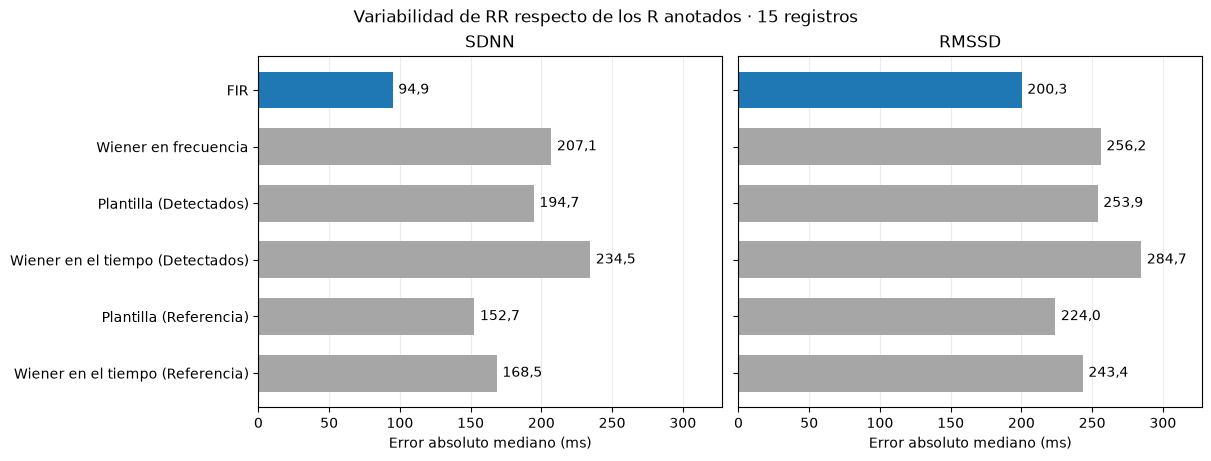

In [85]:
datos = resumen_hrv_temporal_ii
posiciones = np.arange(len(datos))
colores = ["tab:blue" if version == "FIR" else "0.65" for version in datos.index]

paneles = [
    ("Error mediano SDNN (ms)", "SDNN"),
    ("Error mediano RMSSD (ms)", "RMSSD"),
]

fig, ejes = plt.subplots(
    1, 2, figsize=(12, 4.5), sharex=True, sharey=True,
    constrained_layout=True,
)

limite_x = 1.15 * datos[[columna for columna, _ in paneles]].max().max()

for ax, (columna, titulo) in zip(ejes, paneles):
    valores = datos[columna]
    barras = ax.barh(posiciones, valores, color=colores, height=0.65)
    ax.bar_label(
        barras,
        labels=[f"{valor:.1f}".replace(".", ",") for valor in valores],
        padding=4,
    )
    ax.set(title=titulo, xlabel="Error absoluto mediano (ms)", xlim=(0, limite_x))
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.25)

ejes[0].set_yticks(posiciones, datos.index)
ejes[0].invert_yaxis()
fig.suptitle("Variabilidad de RR respecto de los R anotados · 15 registros")
plt.show()

#### Resultados del análisis temporal

Se pudieron comparar los 15 registros internos en las seis versiones.
FIR presentó los menores errores absolutos medianos respecto de los
R anotados, con 94,9 ms para SDNN y 200,3 ms para RMSSD. En cambio,
Wiener en el tiempo con R detectados, que había obtenido el mayor F1
en la sección 7.2, presentó los mayores errores en ambos índices,
con 234,5 ms para SDNN y 284,7 ms para RMSSD.

Al usar R anotados para guiar las correcciones, disminuyeron los
errores de SDNN y RMSSD tanto para Wiener en el tiempo como para
la resta de plantilla, frente a sus respectivas versiones guiadas
por R detectados. En ambos casos, los errores medianos siguieron
siendo superiores a los de FIR.

El F1 resume cuántos picos R se emparejaron con las anotaciones
dentro de ±50 ms. SDNN y RMSSD, en cambio, dependen de la duración
de los intervalos entre picos consecutivos. Perder un pico puede
unir dos intervalos RR, y agregar un pico falso puede dividir uno
en dos. Por eso, el resultado de detección y el de variabilidad
temporal pueden ordenar los métodos de manera diferente.